# Environmental Sound Classification on ESC-50

**COMP9444 26T3 · Team Fireworks**

| Member | zID | Method (section) | Project-wide work | Presentation part |
|---|---|---|---|---|
| Steven Tang | z5079275 | Temporal models: CRNN / LSTM (4.4) | Project topic and design: five methods under one evaluation protocol. Shared data and evaluation code (`support/`). Integration of all methods into this notebook. Literature review and comparison with previous work (5.4). Independent re-runs of methods 2 and 3 (7.1) | Motivation and literature |
| Bruce Li | z5471979 | MFCC statistics + SVM / random forest (4.1) | Exploratory data analysis (3) | Data and EDA |
| Fujinmei Liu | z5618709 | CNN trained from scratch (4.2) | This CNN is the reference model (anchor) of the augmentation series (4.5) | Methods |
| Haole Yin | z5783825 | ImageNet-pretrained ResNet-18 (4.3) | Review of the shared data and evaluation code. Independent re-runs of methods 1, 4 and 5 and audit of their test-fold use (7.1). Contributions to the results-table run list and the previous-work table (5.1, 5.4) | Results |
| Antony Choi | z5708007 | Augmentation series: SpecAugment, mixup (4.5) | Cross-model analysis (6.1) | Augmentation and conclusion |

**Overview.** We classify five-second environmental sound clips into the 50 classes of ESC-50. We compare five kinds of model under one protocol:
1. MFCC statistics (mel-frequency cepstral coefficients, a compact summary of the spectrum) with a classical classifier;
2. a CNN trained from scratch on log-mel spectrograms;
3. an ImageNet-pretrained ResNet-18;
4. temporal models (CRNN and BiLSTM);
5. an augmentation series on the from-scratch CNN.

For each selected configuration, each test fold is evaluated once per seed, after the configurations of the results table were selected on validation results. The data-size runs (25% and 50% of the training clips) and the band-limit control are validation only.

**How to read / run**
- Keep the `support/` folder next to this notebook. It holds the shared code (`support/*.py`) and the saved results of every run (`support/frozen/`).
- Nothing is trained when the notebook runs: Restart & Run All reproduces all tables and figures from the saved results in `support/frozen/`, offline and in under a minute.
- The training and test code of every method is shown in Section 4, and the data preparation in Section 2.2. The reported neural runs used a Tesla T4 GPU.
- The project repository ([https://github.com/tangsteven64/comp9444-fireworks](https://github.com/tangsteven64/comp9444-fireworks)) holds this notebook and its `support/` folder; all saved results the notebook reads are in `support/frozen/`.
- Code names starting with `L1_` to `L5_` belong to methods 1 to 5 (Sections 4.1 to 4.5).

**Glossary.**
- **Method k:** one of the five methods 1 to 5 (`L1_` to `L5_` in the code), described in Sections 4.1 to 4.5.
- **Anchor:** the small CNN of Section 4.2 (method 2) without augmentation. The augmentation series (Section 4.5) ran it again under its own name and compares every augmented model with it.
- **Compound comparison:** a comparison in which more than one setting changes, marked with * in Section 5.3.
- **Seed spread:** the range of a configuration's per-seed five-fold mean test accuracies. A gap smaller than both seed spreads is called "no clear difference" (Section 5.1).
- **M1, M2, M3:** the metrics defined in `support/eval_io.py`: M1 = test accuracy (the main metric), M2 = macro-F1 (mean of the 50 per-class F1 scores), M3 = per-class recall and the confusion matrix.

**Fast reading path.** Section 1 (problem and questions) -> 3.1 (data properties) -> 5.1 (results table) -> 5.5 (short answers to the questions) -> 6.2 (strengths, limitations and future work).

**Contents**
0. Setup · 1. Introduction & Problem Statement · 2. Data Sources · 3. Exploratory Data Analysis · 4. Models & Methods · 5. Results · 6. Discussion · 7. Reproducibility & References

## 0. Setup

Section 0 sets up the environment; reading can start at Section 1.
- **What it does:** it imports the libraries, sets the paths, and loads the shared code and the saved results from the `support/` folder next to this notebook.
- **What to change:** nothing in this section needs to be changed to reproduce the results.

### 0.1 Libraries
Common imports. The versions printed below are those of the environment that produced this saved copy. The environments used for training are in the first table of Section 7.1.

In [1]:
# Standard library
import sys, re, json, math, time, hashlib, platform, inspect
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # progress-bar display notice only; no effect on results

# Third-party
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import torch
import torchaudio
import torchvision

# per-fold learning curves (Section 4): Okabe-Ito colours (colour-blind safe), each fold also with its own line style
FOLD_COLOURS = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7"]
FOLD_STYLES = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| torchaudio", torchaudio.__version__, "| torchvision", torchvision.__version__,
      "| matplotlib", matplotlib.__version__)

python 3.12.13 | numpy 1.26.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.2.2 | torchaudio 2.2.2 | torchvision 0.17.2 | matplotlib 3.11.2


### 0.2 Paths
The training code of Section 4 refers to the ESC-50 audio in `data/`, the log-mel cache in `common/` and the run folders in `results/`. The runs shown in this notebook are read from the saved copies in `support/frozen/`, so nothing is trained and no file is written.

In [2]:
SUPPORT = Path.cwd() / "support"     # shared code and saved results, kept next to this notebook
sys.dont_write_bytecode = True        # never write __pycache__ next to the notebook
sys.path.insert(0, str(SUPPORT))      # the modules in support/ are imported as top-level modules
from notebook_setup import load_saved_results

N_FOLDS = 5                            # official ESC-50 folds
# folders referenced by the training code of Section 4 (ESC-50 audio, log-mel cache, run folders);
# the runs shown in this notebook are read from support/frozen/
ROOT = Path.cwd()
COMMON, RESULTS = ROOT / "common", ROOT / "results"

### 0.3 Shared code and saved results
- **Shared modules:** two modules are used by every method. They are plain Python files in `support/`, imported below.
- **Saved results:** the cell below calls `load_saved_results` (`support/notebook_setup.py`). It loads every saved result in `support/frozen/`: the 41 runs, the split, the EDA data and example clips, the log-mels of the confused-pairs figure and the evidence tables. The saved split is checked against its SHA-256 fingerprint.
- **Method code:** the model and training code of each method stays in Section 4.

| Module | What it does | File |
|---|---|---|
| `eval_io` | Result format, metrics, protocol checks, and reading saved runs | `support/eval_io.py` |
| `data` | Frozen split, log-mel loading, and the noise used in the robustness test | `support/data.py` |
| `notebook_setup` | Loading of the saved results in `support/frozen/` (this section) | `support/notebook_setup.py` |

The saved results are compressed text files (base64-encoded), read only through `load_saved_results`:

| File | Contents | Used in |
|---|---|---|
| `runs.b64` | the 41 runs shown in this notebook: configuration, per-fold validation metrics and learning curves, validation and test predictions, selection and test times, noise-test predictions, and environment records | Sections 3.1 and 4 to 7 |
| `eda.b64` | a copy of the split, and the per-clip bandwidth band and quiet-frame counts of the 2,000 clips | Section 3.1; `SPLIT` wherever the split is needed |
| `sample_clips.b64` | the five example clips: waveform envelopes and half-resolution log-mels | Sections 3.1 and 5.3 |
| `pair_mels.b64` | the nine log-mel inputs of the confused-pairs figure | Section 5.1 |
| `evidence.b64` | the data-freeze record, the test logs and prediction hashes of the 34 selected runs, and the fold-1 re-runs | Sections 2.3 and 7.1 |

In [3]:
import eval_io, data            # the shared modules in support/ (data imports eval_io by name)
# the split and the saved results in support/frozen/ (see support/notebook_setup.py)
SPLIT, EDA_DATA, SAMPLE_CLIPS, EVIDENCE, PAIR_MELS = load_saved_results(SUPPORT)

shared code in support/: version 1.0.5


## 1. Introduction & Problem Statement

**Problem.** We classify five-second environmental audio clips into one of 50 everyday sound classes, such as dog barks, rain, sirens and keyboard typing.
- **Data:** ESC-50 (Piczak, 2015a), 2,000 clips, 40 per class, in five official folds, one label per clip.
- **Why it is hard:**
  - each class has only 40 examples;
  - several classes are easy to confuse (Section 3.1);
  - many clips have an estimated effective bandwidth well below the top of the frequency band, at a rate that differs between classes (Section 3.1).
- **Human reference:** even human listeners reach only 81.3% accuracy (Piczak, 2015a).

**Why it matters.**
- **Use:** recognising everyday sounds helps wherever a device must react to its surroundings, for example urban noise monitoring (Bello et al., 2019) and sound-awareness tools for deaf and hard-of-hearing users (Jain et al., 2020).
- **Gap:** the selected published ESC-50 results we compare with (Section 5.4) go from 39.6% for an SVM on hand-crafted MFCC and zero-crossing-rate statistics (Piczak, 2015a) to 95.6% for a transformer pretrained on ImageNet and AudioSet (Gong et al., 2021). But they come from different inputs, training budgets and evaluation code.
- **Our question:** which model families perform best under one shared protocol and a student compute budget.

**Research questions.**
- **Q1** (4.1): how far can hand-crafted audio features (MFCC statistics) go without a neural network?
- **Q2** (4.2): how well does a plain CNN on log-mel spectrograms do when trained from scratch?
- **Q3** (4.3): do ImageNet visual features help on sound spectrograms, and at what compute cost?
- **Q4** (4.4): for which sound classes does a model with explicit time modelling do better?
- **Q5** (4.5): does augmentation (SpecAugment, mixup) help the from-scratch CNN? We call that CNN without augmentation the "anchor": every augmented run is compared against it.
- Across all methods we also ask where the models fail (Section 6.1).

**Novelty.** We do not propose a new model. We contribute three things:
1. **Five kinds of model under one protocol.**
   - They share the folds, the 128-band mel front end (Section 3.2), the validation set grouped by recording, the scoring code and a comparable compute budget.
   - Every neural and random-forest configuration runs with three seeds. The SVM uses probability calibration with a fixed seed 0 and runs once per fold, so its variation between seeds is not measured.
   - A difference between two models is then unlikely to come from the protocol. We do not claim to know which design choice explains it.
2. **Two recording properties of ESC-50 that we measure** (Section 3.1).
   - 31.4% of the clips have an estimated effective bandwidth below 17 kHz, and 39.8% share an original recording with another clip. The ESC-50 repository already notes that some source recordings were preprocessed in a possibly class-dependent way, mostly band-limiting; our contribution is the per-clip measurement and the control below.
   - Reducing the MFCC filterbank upper edge from 22.05 to 11.025 kHz lowered mean validation accuracy by 3.4 points, and every fold was lower (Section 5.3). Because the lower mel filters move as well, this control does not separate sound content from recording artefacts.
3. **A close look at an ImageNet-pretrained ResNet-18.** We keep it frozen, fine-tune it, train it with less data, and train it from random weights (that run also changes the epoch cap and the input normalisation).

**Fair comparison.**
- Where we could not change one thing at a time, we say so next to the result.
- We fixed the final settings, the "not clearly different" rule and the noise levels before any test fold was used.
- Each test fold is used once per selected configuration and seed; the data-size and band-limit runs are validation only.

## 2. Data Sources

This section documents where the data come from and how they were fixed before any model was trained. Section 2.1 describes ESC-50, its five official folds and our grouped training/validation split. Section 2.2 gives the one-off preparation code (shown, not run), and Section 2.3 lists the fingerprints of the split that every method uses and of the log-mel cache read by the neural methods.

### 2.1 Data source

We use the [ESC-50 dataset](https://github.com/karolpiczak/ESC-50), downloaded from the repository's `master.zip` archive.
- **Size:** 2,000 five-second clips from 50 classes (40 per class) in five official folds. The SHA-256 fingerprints of the ESC-50 metadata, the split and the log-mel cache are in Section 2.3.
- **Licence:** ESC-50 is released under the Creative Commons Attribution-NonCommercial 3.0 licence (CC BY-NC 3.0). Clip-level source credits are listed in the repository's [LICENSE file](https://github.com/karolpiczak/ESC-50/blob/master/LICENSE) and must be retained.

**Split design.** Each evaluation round splits the data as follows:
1. **Test:** one official fold is the test fold.
2. **Validation:** from the other four folds we hold out about one seventh of the clips. The validation set is stratified by class. It is also grouped, so clips cut from the same original recording always stay on the same side of the split.
3. **Training:** the rest of the four folds is used for training (`data` module, Section 0.3).

**Why grouped.**
- Many clips share a source recording (Section 3.1). Excerpts from one recording can share background sounds or recording conditions, so we keep them together in the training/validation split.
- Grouping has a cost: each round's validation set has about 215-230 clips covering 47-49 classes, not all 50.
- The test folds are complete official folds with all 50 classes.
- **Source overlap:** no original recording appears in both the training and the validation clips of any round. The official folds are kept as published, and 4 recordings span more than one fold (Section 3.1), so in rounds 2-5 one or two source recordings also have clips in the test fold.

### 2.2 One-off data preparation (shown, not run)
Preprocessing outline for the fixed split and log-mel cache. It is fully commented out, so it can be read without being run.

In [4]:
# Preprocessing outline for the fixed split and log-mel cache -- not run in this notebook (every line is commented out).
# MFCC features (Section 4.1) are not cached here: the Section 4.1 code computes them from the raw audio.
#
# import hashlib, json, os, sys, urllib.request, zipfile
# from pathlib import Path
# import numpy as np, pandas as pd, soundfile as sf, torch, torchaudio, sklearn
# from sklearn.model_selection import StratifiedGroupKFold
#
# # 1. Download ESC-50 (2,000 five-second clips, 50 classes x 40 clips, five official folds) and check it is complete
# urllib.request.urlretrieve("https://github.com/karolpiczak/ESC-50/archive/master.zip", "data/master.zip")
# zipfile.ZipFile("data/master.zip").extractall("data")
# meta = pd.read_csv("data/ESC-50-master/meta/esc50.csv")
# assert len(meta) == 2000 and meta["fold"].value_counts().eq(400).all() and meta["target"].value_counts().eq(40).all()
# assert len(list(Path("data/ESC-50-master/audio").glob("*.wav"))) == 2000
#
# # 2. Split (data.make_split): round k uses official fold k as the test fold. The other four folds are divided into
# #    7 parts, stratified by class and grouped by original recording (src_file); one part is the validation set,
# #    so no original recording appears in both training and validation.
# split = meta[["filename", "fold", "target", "category", "src_file"]].copy()
# for k in range(1, 5 + 1):
#     pool = split[split["fold"] != k]
#     sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=0 + k)
#     _, val_pos = next(sgkf.split(pool, pool["target"], groups=pool["src_file"]))
#     split[f"val_r{k}"] = split["filename"].isin(pool.iloc[val_pos]["filename"]).astype(int)
# split.to_csv("common/split.csv", index=False)
#
# # 3. Log-mel cache, one row per clip in split order (2000 x 1 x 128 x 431, float16), computed clip by clip with
# #    data.logmel_from_waveform (Section 0.3): torchaudio MelSpectrogram (sample_rate=44100, n_fft=2048, win_length=2048, hop_length=512, n_mels=128)
# #    + AmplitudeToDB(power, top_db=80), cropped to 431 frames, full band (0-22.05 kHz).
# CACHES = {"logmel_fp16.npy": 22050.0}
# for name, f_max in CACHES.items():
#     cache = np.zeros((len(split), 1, 128, 431), dtype=np.float16)
#     for i, fn in enumerate(split["filename"]):
#         x, sr = sf.read(f"data/ESC-50-master/audio/{fn}", dtype="float32")   # mono, 5 s
#         assert sr == 44100
#         cache[i] = data.logmel_from_waveform(x, f_max=f_max, fp16=False)
#     np.save(f"common/{name}", cache)
#
# # 4. Freeze: the SHA-256 of split.csv is hard-coded into data.py as EXPECTED_SPLIT_SHA256 (data.load_split checks it on
# #    every load), and common/FROZEN.json records the size and SHA-256 of the split and the cache, the SHA-256 of the
# #    ESC-50 metadata file, the log-mel parameters (summarised in Section 2.3) and the library versions (the versions of
# #    this notebook run are printed in Section 0.1, those of the final runs in Section 7.1).
# sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
# frozen = {"logmel_params": data.LOGMEL_PARAMS, "cache_f_max_hz": CACHES,
#           "files": {f: {"bytes": os.path.getsize(f"common/{f}"), "sha256": sha(f"common/{f}")} for f in ["split.csv", *CACHES]},
#           "esc50_meta_sha256": sha("data/ESC-50-master/meta/esc50.csv"),
#           "versions": {"python": sys.version.split()[0], "torch": torch.__version__, "torchaudio": torchaudio.__version__,
#                        "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__}}
# json.dump(frozen, open("common/FROZEN.json", "w"), indent=2)

### 2.3 Frozen split and feature cache
SHA-256 fingerprints of the split and of the log-mel cache that the neural runs read, with the log-mel parameters. The split is loaded from its copy in `support/frozen/` and checked against this fingerprint (Section 0.3).

In [5]:
# Fingerprints of the frozen split and log-mel cache, and the log-mel parameters every run reads, from EVIDENCE:
# the freeze record and the test-log evidence saved in support/frozen/ (Section 0.3); also used in Section 7.1
# rows: freeze status, confirmation time, code version, then the split and metadata fingerprints
fz = EVIDENCE["frozen"]
lm = fz["logmel_params"]
rows = [("status", fz["status"]), ("confirmed at (UTC)", fz["confirmed_at"]), ("shared code version", fz["common_version"]),
        ("split.csv SHA-256 (first 12)", fz["files"]["split.csv"][:12]),
        ("ESC-50 metadata SHA-256 (first 12)", (fz["esc50_meta_sha256"] or "")[:12])]
# the log-mel cache read by the neural runs, with its upper frequency
fmax = fz["cache_f_max_hz"]["logmel_fp16.npy"]
rows.append((f"logmel_fp16.npy SHA-256 (first 12), f_max {fmax / 1000:g} kHz", fz["files"]["logmel_fp16.npy"][:12]))
# the log-mel parameters shared by every run
rows.append(("log-mel parameters", f"sample rate {lm['sample_rate']} Hz, n_fft {lm['n_fft']}, hop {lm['hop_length']}, "
                                   f"n_mels {lm['n_mels']}, frames {lm['frames']}, top_db {lm['top_db']}"))
with pd.option_context("display.max_colwidth", None, "display.width", 250):   # show every value in full
    display(pd.DataFrame(rows, columns=["item", "value"]).set_index("item"))

,value
item,
status,frozen
confirmed at (UTC),2026-10-10T07:13:00Z
shared code version,1.0.5
split.csv SHA-256 (first 12),dd83fbbbf08c
ESC-50 metadata SHA-256 (first 12),ca660da60191
"logmel_fp16.npy SHA-256 (first 12), f_max 22.05 kHz",01eb2090ab52
log-mel parameters,"sample rate 44100 Hz, n_fft 2048, hop 512, n_mels 128, frames 431, top_db 80"


**Reading the table.**
- **Frozen on 10 October 2026 (UTC):** the split and the log-mel cache have been fixed since then, and the split, loaded from its copy in `support/frozen/`, is checked against this fingerprint.
- **Why it matters:** every method in Section 4 uses this one split, so all comparisons use the same folds. The neural models also read the full-band log-mel cache, while the MFCC models compute their features from the raw audio.

## 3. Exploratory Data Analysis

This section looks at the properties of the data that matter for the models. Section 3.1 covers the number of classes and folds and four challenging aspects (early cut-offs in frequency, clips from the same recording, quiet portions and classes that sound alike), with one figure for each of the five angles and a figure of example clips. Section 3.2 lists the pre-processing steps that all methods share and those that differ by method.

### 3.1 Properties, number of classes and challenging aspects

We looked at the data from five angles:
1. classes and folds;
2. early cut-offs in frequency;
3. clips from the same recording;
4. quiet portions;
5. classes that sound alike.

**Definitions.**
- **Quiet:** a 100 ms piece of a clip is "quiet" when its RMS level is below −40 dBFS, 40 dB under the loudest level a file can hold.
- **Effective bandwidth:** the centre of a clip's highest mel band whose 95th-percentile level is within 60 dB of its loudest band. It is an estimate from a threshold, not a measurement of the recording equipment.
- **Similar classes:** this figure uses validation predictions of the MFCC + SVM baseline (Section 4.1), never test predictions.

**The first code cell below** defines how these values are computed (`eda_values`, not run here), and **the second** draws the five figures from per-clip values saved in `support/frozen/`: the effective-bandwidth band of every clip, computed from the full-band log-mel cache, and the number of quiet 100 ms pieces per clip, computed from the raw audio.

In [6]:
# How the per-clip EDA values saved in support/frozen/eda.b64 are computed. Shown, not run here: it needs the ESC-50
# audio and the log-mel cache. The next cell plots the saved values. Example call:
#   eda_values(SPLIT, data.load_logmel(COMMON / "logmel_fp16.npy", np.arange(len(SPLIT))),
#              ROOT / "data" / "ESC-50-master" / "audio")
def eda_values(split, logmel, audio_dir):
    """Effective-bandwidth band of every clip (from its full-band log-mel) and its number of quiet 100 ms frames."""
    # effective bandwidth = centre of the highest mel band whose 95th-percentile level over time is within 60 dB of the
    # clip's loudest band (the cache is in dB, clipped at 80 dB below each clip's maximum)
    level = np.percentile(logmel[:, 0], 95, axis=2)                    # (clips, 128): rows are (1, 128 mel, 431 frames)
    top = level >= level.max(axis=1, keepdims=True) - 60
    band_top_index = (127 - np.argmax(top[:, ::-1], axis=1)).tolist()  # highest band above the threshold
    # quiet frame: 100 ms of waveform with RMS below -40 dBFS
    frame = int(round(data.LOGMEL_PARAMS["sample_rate"] * 0.1))
    quiet = []
    for start in range(0, len(split), 100):
        chunk = np.arange(start, min(start + 100, len(split)))
        for x, _sr in data.load_waveform(audio_dir, split, chunk):
            frames = x[:(len(x) // frame) * frame].reshape(-1, frame)
            db = 20 * np.log10(np.maximum(np.sqrt(np.mean(np.square(frames, dtype=np.float32), axis=1)), 1e-12))
            quiet.append(int((db < -40.0).sum()))
    # key names as stored in support/frozen/eda.b64
    return {"band_top_index": band_top_index, "low_energy_frames": quiet, "frames_per_clip": len(x) // frame}

fold
1    400
2    400
3    400
4    400
5    400
dtype: int64
50 classes; clips per class: 40–40; clips per class per fold: 8–8
           train  validation  test  val_share
test fold                                    
1           1370         230   400      0.144
2           1383         217   400      0.136
3           1370         230   400      0.144
4           1385         215   400      0.134
5           1374         226   400      0.141


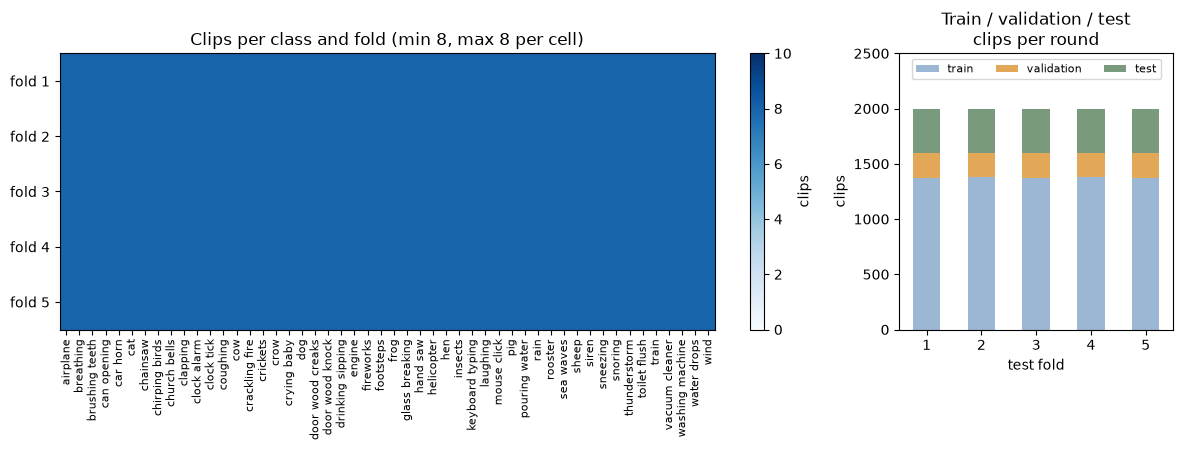

effective bandwidth (kHz): median 18.6; below 11.025 kHz: 137 clips; below 17 kHz: 628 clips (31.4%); in the 15.5–16.5 kHz peak: 257 clips
classes with the largest share of clips with an estimated bandwidth below 17 kHz: {'rooster': 88.0, 'helicopter': 85.0, 'siren': 78.0, 'dog': 75.0, 'church bells': 72.0}
highest mel-band centre (kHz): full-band cache 21.44 | band-limit control 10.77


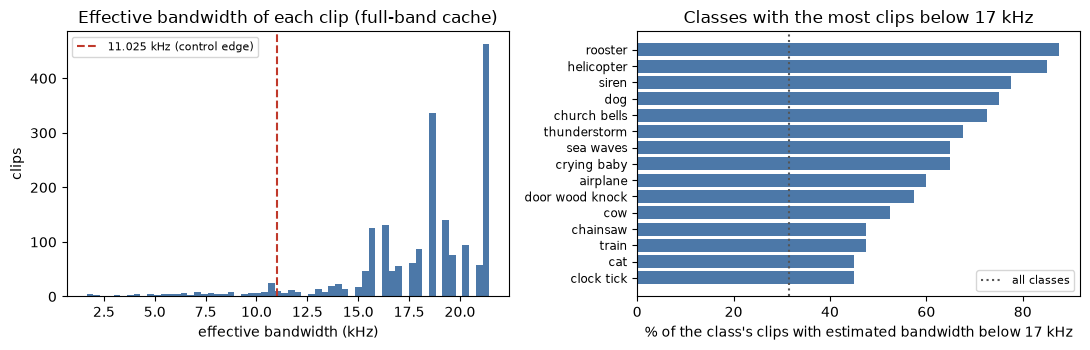

1524 original recordings for 2000 clips; clips sharing a recording with another clip: 795 (39.8%); largest group: 8 clips; recordings spanning more than one official fold: 4


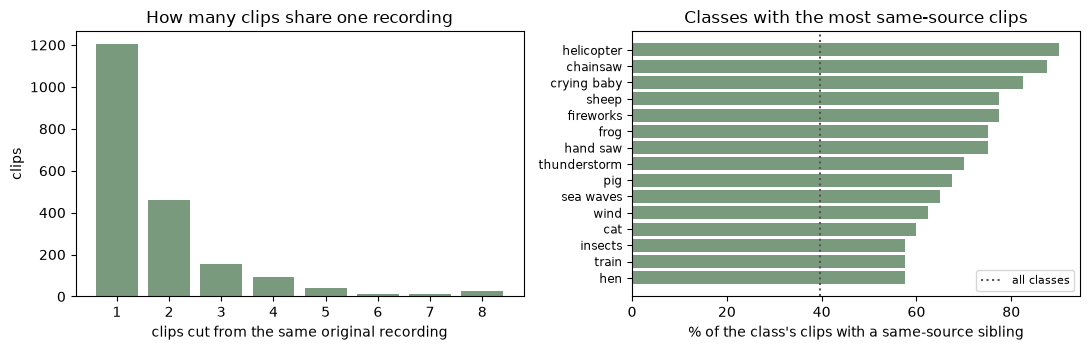

quiet definition: 100 ms frame RMS below -40 dBFS
median quiet duration per clip: 18.0%; clips with at least one quiet frame: 1213 (60.7%)
classes with the largest mean quiet share: {'sneezing': 82.4, 'can opening': 79.1, 'water drops': 76.2, 'glass breaking': 74.3, 'mouse click': 71.6}


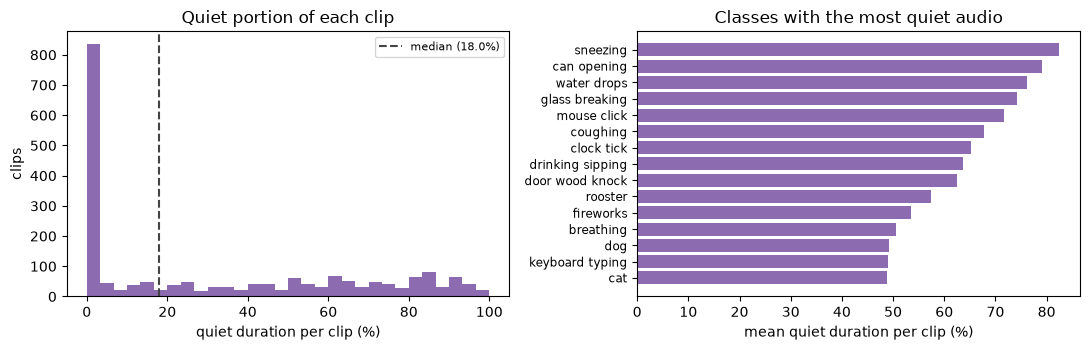

MFCC-SVM: 1118 validation predictions across five rounds; top confused class pairs (both directions): [('insects', 'snoring', 8), ('crying baby', 'door wood creaks', 8), ('clock tick', 'crackling fire', 8), ('keyboard typing', 'mouse click', 7), ('engine', 'washing machine', 6), ('coughing', 'sneezing', 6), ('clock tick', 'keyboard typing', 6), ('church bells', 'siren', 6), ('church bells', 'cow', 6), ('cat', 'crying baby', 6)]


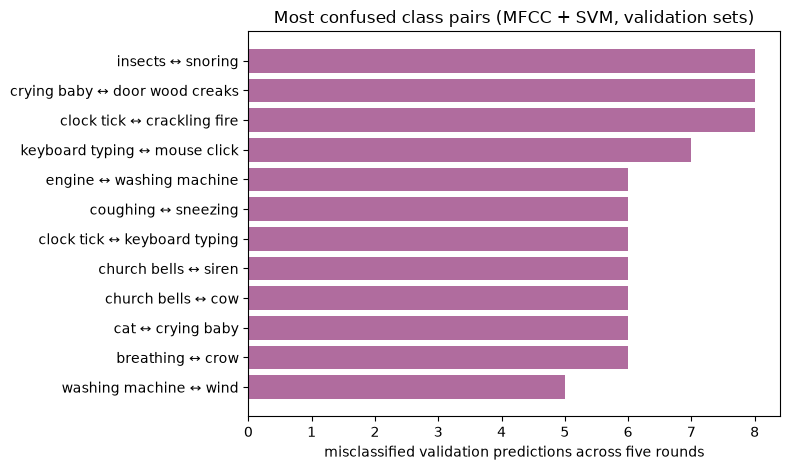

In [7]:
# The five EDA figures, from the per-clip values saved in support/frozen/ (Section 0.3).
EDA_SIMILAR_RUN = "line1/2026-10-17_mfcc-svm_s0"   # MFCC-SVM validation predictions for angle 5
# EDA_DATA (Section 0.3) holds the saved per-clip values: effective-bandwidth band and quiet frames


def eda_mel_centres(f_max, n_mels=128):
    """Centre frequency (Hz) of each mel band of torchaudio's MelSpectrogram (HTK mel scale, f_min = 0)."""
    mel = np.linspace(0, 2595 * np.log10(1 + f_max / 700), n_mels + 2)
    return 700 * (10 ** (mel / 2595) - 1)[1:-1]



def eda_name(c):
    return c.replace("_", " ")          # class names as a reader sees them (spaces), as in Section 5

# Angle 1: classes and folds
EDA_counts = SPLIT.groupby(["fold", "category"]).size().unstack(fill_value=0)
print(EDA_counts.sum(axis=1))   # 400 clips per fold
print(f"{SPLIT['category'].nunique()} classes; clips per class: {SPLIT['category'].value_counts().min()}–"
      f"{SPLIT['category'].value_counts().max()}; clips per class per fold: {EDA_counts.values.min()}–{EDA_counts.values.max()}")
EDA_rounds = pd.DataFrame([dict(zip(["train", "validation", "test"], map(len, data.get_round(SPLIT, k)))) for k in range(1, N_FOLDS + 1)],
                          index=pd.Index(range(1, N_FOLDS + 1), name="test fold"))
print(EDA_rounds.assign(val_share=(EDA_rounds["validation"] / (EDA_rounds["train"] + EDA_rounds["validation"])).round(3)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [2.6, 1]})
im = ax[0].imshow(EDA_counts.values, aspect="auto", cmap="Blues", vmin=0, vmax=EDA_counts.values.max() * 1.25)
ax[0].set_yticks(range(N_FOLDS), [f"fold {k}" for k in EDA_counts.index])
ax[0].set_xticks(range(EDA_counts.shape[1]), [eda_name(n) for n in EDA_counts.columns], rotation=90, fontsize=8)
ax[0].set_title(f"Clips per class and fold (min {EDA_counts.values.min()}, max {EDA_counts.values.max()} per cell)")
plt.colorbar(im, ax=ax[0], fraction=0.03, label="clips")
EDA_rounds.plot.bar(stacked=True, ax=ax[1], rot=0, color=["#9bb7d4", "#e3a857", "#7a9a7e"])
ax[1].set_ylabel("clips"); ax[1].set_title("Train / validation / test\nclips per round")
ax[1].set_ylim(0, len(SPLIT) * 1.25); ax[1].legend(fontsize=8, ncol=3, loc="upper center")
plt.tight_layout(); plt.show()

# Angle 2: effective bandwidth of each clip (full-band cache), against the 11.025 kHz limit of the band-limit control
# Effective bandwidth of a clip = centre of the highest mel band whose 95th-percentile level over time is within
# 60 dB of the clip's loudest band (saved: the index of that band for every clip).
EDA_bw = pd.Series(eda_mel_centres(22050.0)[np.asarray(EDA_DATA["band_top_index"])] / 1000, index=SPLIT.index, name="bandwidth_khz")
EDA_cut = EDA_bw < 17.0                                                     # clips with an estimated bandwidth below 17 kHz
EDA_bw_cls = EDA_cut.groupby(SPLIT["category"]).mean().sort_values(ascending=False)
print(f"effective bandwidth (kHz): median {EDA_bw.median():.1f}; below 11.025 kHz: {(EDA_bw < 11.025).sum()} clips; "
      f"below 17 kHz: {EDA_cut.sum()} clips ({EDA_cut.mean():.1%}); in the 15.5–16.5 kHz peak: {EDA_bw.between(15.5, 16.5).sum()} clips")
print("classes with the largest share of clips with an estimated bandwidth below 17 kHz:",
      {eda_name(n): v for n, v in (EDA_bw_cls.head(5) * 100).round(0).to_dict().items()})
print("highest mel-band centre (kHz): full-band cache", round(eda_mel_centres(22050.0)[-1] / 1000, 2),
      "| band-limit control", round(eda_mel_centres(11025.0)[-1] / 1000, 2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(EDA_bw, bins=60, color="#4c78a8")
ax[0].axvline(11.025, color="#c0392b", ls="--", label="11.025 kHz (control edge)")
ax[0].set_xlabel("effective bandwidth (kHz)"); ax[0].set_ylabel("clips"); ax[0].legend(fontsize=8, loc="upper left")
ax[0].set_title("Effective bandwidth of each clip (full-band cache)")
ax[1].barh([eda_name(n) for n in EDA_bw_cls.index[:15][::-1]], EDA_bw_cls.values[:15][::-1] * 100, color="#4c78a8")
ax[1].axvline(EDA_cut.mean() * 100, color="#555", ls=":", label="all classes")
ax[1].set_xlabel("% of the class's clips with estimated bandwidth below 17 kHz"); ax[1].tick_params(axis="y", labelsize=8.5)
ax[1].set_title("Classes with the most clips below 17 kHz"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Angle 3: same-source recordings (src_file)
EDA_src = SPLIT.groupby("src_file").agg(clips=("filename", "size"), folds=("fold", "nunique"), category=("category", "first"))
EDA_sib = SPLIT["src_file"].map(EDA_src["clips"]) > 1
print(f"{len(EDA_src)} original recordings for {len(SPLIT)} clips; clips sharing a recording with another clip: "
      f"{EDA_sib.sum()} ({EDA_sib.mean():.1%}); largest group: {EDA_src['clips'].max()} clips; "
      f"recordings spanning more than one official fold: {(EDA_src['folds'] > 1).sum()}")
EDA_sib_cls = EDA_sib.groupby(SPLIT["category"]).mean().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
EDA_n = EDA_src["clips"].value_counts().sort_index()
ax[0].bar(EDA_n.index.astype(str), EDA_n.values * EDA_n.index, color="#7a9a7e")
ax[0].set_xlabel("clips cut from the same original recording"); ax[0].set_ylabel("clips")
ax[0].set_title("How many clips share one recording")
ax[1].barh([eda_name(n) for n in EDA_sib_cls.index[:15][::-1]], EDA_sib_cls.values[:15][::-1] * 100, color="#7a9a7e")
ax[1].axvline(EDA_sib.mean() * 100, color="#555", ls=":", label="all classes")
ax[1].set_xlabel("% of the class's clips with a same-source sibling"); ax[1].tick_params(axis="y", labelsize=8.5)
ax[1].set_title("Classes with the most same-source clips"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Angle 4: quiet portions (100 ms frames with waveform RMS below -40 dBFS; frames per clip)
EDA_silence = pd.Series((np.asarray(EDA_DATA["low_energy_frames"]) / EDA_DATA["frames_per_clip"]).astype(np.float32),
                        index=SPLIT.index, name="quiet_fraction")
EDA_silence_cls = EDA_silence.groupby(SPLIT["category"]).mean().sort_values(ascending=False)
print("quiet definition: 100 ms frame RMS below -40 dBFS")
print(f"median quiet duration per clip: {EDA_silence.median():.1%}; clips with at least one quiet frame: "
      f"{(EDA_silence > 0).sum()} ({(EDA_silence > 0).mean():.1%})")
print("classes with the largest mean quiet share:",
      {eda_name(c): round(float(s * 100), 1) for c, s in EDA_silence_cls.head(5).items()})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(EDA_silence * 100, bins=30, color="#8c6bb1")
ax[0].axvline(EDA_silence.median() * 100, color="#444", ls="--", label=f"median ({EDA_silence.median():.1%})")
ax[0].set_xlabel("quiet duration per clip (%)"); ax[0].set_ylabel("clips")
ax[0].set_title("Quiet portion of each clip")
ax[0].legend(fontsize=8)
ax[1].barh([eda_name(n) for n in EDA_silence_cls.index[:15][::-1]], EDA_silence_cls.values[:15][::-1] * 100, color="#8c6bb1")
ax[1].set_xlabel("mean quiet duration per clip (%)"); ax[1].tick_params(axis="y", labelsize=8.5)
ax[1].set_title("Classes with the most quiet audio")
plt.tight_layout(); plt.show()

# Angle 5: similar classes, from the saved MFCC-SVM validation predictions
EDA_svm_run = eval_io.load_run_or_none(RESULTS / EDA_SIMILAR_RUN)
if EDA_svm_run is not None and EDA_svm_run["val_preds"]:
    EDA_val_preds = pd.concat([EDA_svm_run["val_preds"][k] for k in sorted(EDA_svm_run["val_preds"])], ignore_index=True)
    EDA_target_to_category = SPLIT.drop_duplicates("target").set_index("target")["category"].to_dict()
    EDA_true = EDA_val_preds["y_true"].map(EDA_target_to_category)
    EDA_pred = EDA_val_preds["y_pred"].map(EDA_target_to_category)
    EDA_classes = sorted(SPLIT["category"].unique())
    EDA_cm = pd.crosstab(EDA_true, EDA_pred).reindex(index=EDA_classes, columns=EDA_classes, fill_value=0)
    EDA_pairs = []
    for i, a in enumerate(EDA_classes):
        for b in EDA_classes[i + 1:]:
            n = int(EDA_cm.loc[a, b] + EDA_cm.loc[b, a])
            if n:
                EDA_pairs.append((n, a, b))
    EDA_pairs.sort(reverse=True)
    print(f"MFCC-SVM: {len(EDA_val_preds)} validation predictions across five rounds; top confused class pairs (both directions):",
          [(eda_name(a), eda_name(b), n) for n, a, b in EDA_pairs[:10]])
    if EDA_pairs:
        EDA_top = EDA_pairs[:12]
        fig, ax = plt.subplots(figsize=(8, 4.8))
        ax.barh([f"{eda_name(p[1])} ↔ {eda_name(p[2])}" for p in EDA_top][::-1], [p[0] for p in EDA_top][::-1], color="#b06c9e")
        ax.set_xlabel("misclassified validation predictions across five rounds")
        ax.set_title("Most confused class pairs (MFCC + SVM, validation sets)")
        plt.tight_layout(); plt.show()


**Reading the figures.**

**Number of classes.** ESC-50 has 50 classes and is balanced. Every class has the same number of clips in every official fold (first figure). With balanced classes, plain accuracy is a fair headline number.

**Properties.**
- **Bandwidth:** many clips have an estimated effective bandwidth well below the top of the full band, and the share differs strongly between classes (second figure).
- **Same-source recordings:** many clips come from the same original recording, and a few recordings span official folds (third figure). We keep all clips of one recording on the same side of the training / validation split. The official folds are kept as published.
- **Quiet portions:** quiet time per clip has a large pile at zero and a broad spread above it (fourth figure). Sneezing, can opening and water drops are the quietest classes on average. "Quiet" is a fixed threshold, not what a listener would call silence.

**Challenging aspects.**
- **Bandwidth and recording artefacts:** the band limit differs by class, so a model could learn the cut-off instead of the sound. Section 5.3 compares the MFCC baseline with a run whose mel filterbank upper edge is lowered to 11.025 kHz (validation only). That test alone cannot show whether a model uses the sound or the cut-off.
- **Confusable classes:** the MFCC + SVM validation predictions mix up the same pairs again and again (fifth figure, validation set only). Examples are clock tick / crackling fire, insects / snoring and crying baby / door wood creaks. These pairs are repeatedly confused by the MFCC-summary baseline.
- **Little data:** forty clips per class is very little, and excerpts of one recording stay together in the training/validation split (Section 2.1).
- **Quiet clips:** when short events are separated by long quiet stretches, much of the clip carries little class information. The MFCC baseline averages over the whole clip, quiet parts included.

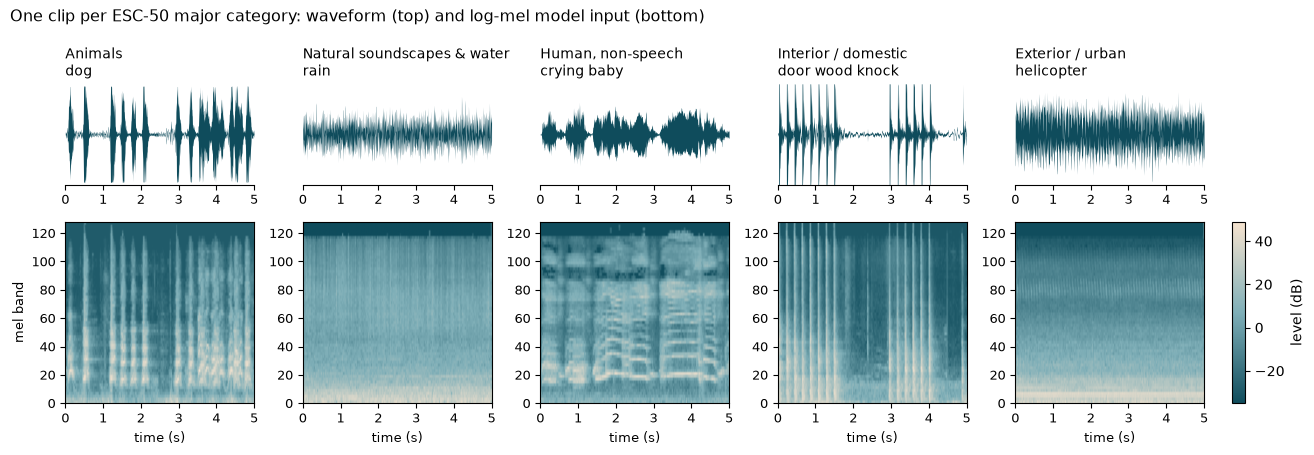

Clips (file, official fold): Animals: 2-117271-A-0.wav (fold 2); Natural soundscapes & water: 3-143929-A-10.wav (fold 3); Human, non-speech: 5-198411-E-20.wav (fold 5); Interior / domestic: 1-81001-A-30.wav (fold 1); Exterior / urban: 5-177957-D-40.wav (fold 5)
SD of the frame-average level over time: door wood knock 11.7 dB (largest), helicopter 0.7 dB (smallest); quiet 100 ms frames per clip: none in any of the five clips


In [8]:
# One example clip per ESC-50 major category: waveform envelope (top) and log-mel model input (bottom).
# colour map of the notebook figures (dark teal to light apricot)
SLIDE_CMAP = matplotlib.colors.LinearSegmentedColormap.from_list("slides", ["#0F4C5C", "#7FAFB8", "#F6E3CF"])


def sc_dequantise(q, lo, hi):
    # map the 0-255 codes back to the original range
    return lo + q.astype(np.float32) / 255 * (hi - lo)


# per category: the clip of its first class with the fewest quiet 100 ms frames (ties: median level, file name),
# saved in support/frozen/ as an 8-bit waveform envelope and a half-resolution 8-bit log-mel
SC_CLIPS = []
E = SAMPLE_CLIPS
for i in range(len(E["filenames"])):
    # rebuild the waveform envelope from its 8-bit codes
    env = (E["env_q"][i].astype(np.float32) / 127 * E["env_scale"][i])
    SC_CLIPS.append({"group": str(E["groups"][i]), "category": str(E["categories"][i]), "filename": str(E["filenames"][i]),
                     "fold": int(E["folds"][i]), "low": int(E["low_frames"][i]), "n_frames": int(E["frames_per_clip"]), "env": (env[0], env[1]),
                     "mel": sc_dequantise(E["mel_q"][i], E["mel_lo"][i], E["mel_hi"][i]),
                     "q": E["mel_q"][i], "lo": float(E["mel_lo"][i]), "hi": float(E["mel_hi"][i])})

if SC_CLIPS:
    # top row: waveform envelope; bottom row: log-mel input
    fig, axes = plt.subplots(2, len(SC_CLIPS), figsize=(2.6 * len(SC_CLIPS), 4.6), gridspec_kw={"height_ratios": [1, 1.8]})
    t_env = np.linspace(0, 5, len(SC_CLIPS[0]["env"][0]))
    sc_ims = []                                  # the five log-mel images, given one shared colour scale below
    for j, c in enumerate(SC_CLIPS):
        ax = axes[0, j]
        ax.fill_between(t_env, c["env"][0], c["env"][1], color="#0F4C5C", lw=0)
        ax.set_xlim(0, 5); ax.set_ylim(-1, 1); ax.set_yticks([])
        ax.set_title(f"{c['group']}\n{c['category'].replace('_', ' ')}", fontsize=10, loc="left")
        ax.spines[["top", "right", "left"]].set_visible(False); ax.tick_params(labelsize=9)
        ax = axes[1, j]
        sc_ims.append(ax.imshow(c["mel"], origin="lower", aspect="auto", cmap=SLIDE_CMAP, extent=[0, 5, 0, 128]))
        ax.set_xlabel("time (s)", fontsize=9); ax.tick_params(labelsize=9)
        if j == 0:
            ax.set_ylabel("mel band", fontsize=9)
    fig.suptitle("One clip per ESC-50 major category: waveform (top) and log-mel model input (bottom)",
                 x=0.01, ha="left", fontsize=11.5)
    # one colour scale for all five log-mels, so levels can be compared across clips
    sc_lo = min(float(np.min(c["mel"])) for c in SC_CLIPS)
    sc_hi = max(float(np.max(c["mel"])) for c in SC_CLIPS)
    for im in sc_ims:
        im.set_clim(sc_lo, sc_hi)
    plt.tight_layout(rect=(0, 0, 0.94, 1))
    sc_pos = axes[1, -1].get_position()
    fig.colorbar(sc_ims[0], cax=fig.add_axes([0.95, sc_pos.y0, 0.01, sc_pos.height]), label="level (dB)")
    plt.show()
    # how much each clip's frame-average level varies over time
    sc_var = [float(sc_dequantise(c["q"], c["lo"], c["hi"]).mean(axis=0).std()) for c in SC_CLIPS]   # half-res 8-bit copy
    hi_i, lo_i = int(np.argmax(sc_var)), int(np.argmin(sc_var))
    name = lambda c: c["category"].replace("_", " ")   # noqa: E731
    lows = [c["low"] for c in SC_CLIPS]
    # print the chosen files, the largest and smallest variation over time, and the quiet frames
    print("Clips (file, official fold):", "; ".join(f"{c['group']}: {c['filename']} (fold {c['fold']})" for c in SC_CLIPS))
    print(f"SD of the frame-average level over time: {name(SC_CLIPS[hi_i])} {sc_var[hi_i]:.1f} dB (largest), "
          f"{name(SC_CLIPS[lo_i])} {sc_var[lo_i]:.1f} dB (smallest); quiet 100 ms frames per clip: "
          + ("none in any of the five clips" if max(lows) == 0 else
             f"{min(lows)} to {max(lows)} of {SC_CLIPS[0]['n_frames']}"))
else:
    print("Example-clip figure skipped: the saved example clips in support/frozen/ are not available.")

**Example clips.** The figure shows one clip from each of the five major categories of ESC-50. These are animals, natural soundscapes and water, human non-speech, interior / domestic, and exterior / urban. Each is the first class of its block. Within that class we picked the clip with the fewest quiet pieces, so the examples have few quiet stretches. The top row is the waveform envelope, and the bottom row is the model input, the full-band log-mel (a saved half-resolution copy), with one colour scale for all five clips. The inputs differ visibly: some clips change strongly over time, others are close to stationary.

### 3.2 Pre-processing

All methods share the clips, the folds, the mel analysis settings of the main input (Section 2.3) and the scoring code. The feature reduction and the normalisation are method-specific (table below), so a difference between methods can also come from these input steps. The log-mel cache is built once (Section 2.2) and fingerprinted (Section 2.3).

| Step | Setting | Used by |
|---|---|---|
| Audio | ESC-50 WAV files, 44.1 kHz, mono, 5 s (220,500 samples); no resampling | all |
| Log-mel, full band (shared input) | STFT with a 2048-sample window and FFT, hop 512. 128 mel bands from 0 to 22.05 kHz. Power converted to dB with `top_db = 80` per clip. 431 frames, stored as float16 | 4.2-4.5 |
| MFCC statistics | 40 MFCCs from the same mel front end, plus first and second deltas. Mean and SD over time give 240 values per clip, standardised with training-set statistics | 4.1 |
| Normalisation | per mel band, with the mean and SD of the training clips of the current round only (4.2, 4.4, 4.5). For ResNet-18, one min-max range from the training clips, repeated to three channels and normalised with the ImageNet mean and SD; the randomly initialised ResNet-18 uses a fixed mean of 0.5 and SD of 0.25 instead (4.3) | per method |
| Augmentation | during training only, on the normalised log-mel (Section 4.5). Validation and test clips are never augmented | 4.5 |

**Steps we leave out.**
- **No silence trimming:** the quiet intervals belong to short events such as sneezing and can opening, and trimming would give clips of different lengths.
- **No filtering of the high band of the main input:** instead, the band-limit control of Section 5.3 measures how the MFCC baseline changes when its mel filterbank stops at 11.025 kHz.

## 4. Models & Methods

This section presents the five methods in the order of the questions in Section 1. Section 4.0 describes what all methods share. Sections 4.1 to 4.5 then have the same four parts for each method: the question and why we chose the method, which parts are our own work and which are borrowed, the settings and code, and the results and what they show.

### 4.0 Shared pipeline, naming and sources

**Shared pipeline.**
- **Shared code:** all methods share the `data` and `eval_io` modules (Section 0.3). So the split, the mel front end and the scoring are the same everywhere. The project repository ([https://github.com/tangsteven64/comp9444-fireworks](https://github.com/tangsteven64/comp9444-fireworks)) holds this notebook and its `support/` folder with the same shared code.
- **What differs:** the feature reduction (MFCC statistics or the full log-mel) and the normalisation differ by method (table in Section 3.2).
- **Protocol:** every model is trained, validated and selected on the training and validation sets only; the data-size and band-limit runs stay validation only.
- **Settings:** a method's settings are one configuration dictionary (`L<k>_CONFIG`). Model and training hyperparameters are fixed across seeds.
- **Hardware:** the neural models train on a CUDA GPU when there is one (the final runs used a Tesla T4 on Colab, Section 7.1), otherwise on the CPU.

**How the runs were made.** Every configuration was trained and validated on the training and validation parts of the four non-test folds of each round only; for the neural models the saved model of a fold is the epoch with the best validation accuracy. The configurations of the results table were then selected, and each test fold was evaluated once per seed with the saved model of that fold. Each method's section shows its functions that train and test one fold (`L<k>_train_one_fold`, `L<k>_test_one_fold`); the saved runs (their names start with `line1` to `line5`, one per method) are loaded from `support/frozen/`. When the runs were trained, `eval_io.select_for_final` recorded the selection, and `eval_io.save_test` refused to save a test result for a run that had not been selected, or a second result for the same fold.

**Naming.**
- We call the methods 1 to 5; Sections 4.1 to 4.5 describe them.
- Code names starting with `L1_` to `L5_` belong to one method, so the five methods can share one notebook without overwriting each other. Names without a prefix are shared.

**Shared parts: own work vs borrowed.** Each method's subsection lists only what is specific to it.

| Part | Own work / borrowed | Source |
|---|---|---|
| Data loading and split | Own work, team code `support/data.py`: test folds, grouped validation set, split fingerprint check, log-mel computation, noise for the robustness test. It calls scikit-learn `StratifiedGroupKFold` and torchaudio `MelSpectrogram` | ESC-50 (Piczak, 2015a); [scikit-learn](https://scikit-learn.org); [torchaudio](https://pytorch.org/audio) |
| Evaluation and result format | Own work, team code `support/eval_io.py`: result files, metrics, protocol checks. Section 5.1 lists where each metric function is defined in this file | - |
| Training-loop template | Own work, adapted in each method. Normalisation uses training clips only. The neural models are trained with the Adam optimiser on cross-entropy loss. Early stopping watches validation accuracy. The best model is saved and reloaded before predicting. Each test fold is run once, after selection | PyTorch / scikit-learn APIs; Adam: Kingma and Ba, 2015 |

### 4.1 Hand-crafted features: MFCC statistics + SVM / random forest (`L1_`)

#### 4.1.1 Question and why this method
**Q1.** How far can hand-crafted audio features (MFCC statistics) go without a neural network?
- **Why this method:** a non-neural baseline shows how much of ESC-50 can be solved from summary statistics of the spectrum alone. It also sets the bar every neural model has to clear.
- **Literature:** the original ESC-50 baselines used MFCC and zero-crossing-rate statistics with simple classifiers (Piczak, 2015a). We follow them with 40 MFCCs plus first- and second-order deltas, and an RBF SVM (Cortes and Vapnik, 1995) or a random forest (Breiman, 2001).
- **What it cannot see:** because we average over time, this baseline does not know the order of events. The deltas only capture short-term change. So if a neural model beats it, time information is not the only possible reason.

#### 4.1.2 Sources: own work vs borrowed
| Part | Own work / borrowed | Source (link) |
|---|---|---|
| Features | Borrowed library: torchaudio MFCC and deltas. Own work: the per-clip mean / SD summary (as in the ESC-50 MFCC baselines) | [torchaudio.transforms.MFCC](https://pytorch.org/audio/stable/generated/torchaudio.transforms.MFCC.html); Piczak, 2015a, *ESC: Dataset for Environmental Sound Classification* |
| Model | Borrowed library: scikit-learn StandardScaler, SVC (RBF kernel) and RandomForestClassifier | [scikit-learn SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html); [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html); Cortes and Vapnik, 1995, *Support-vector networks*; Breiman, 2001, *Random Forests* |
| Pretrained weights | none | - |

We wrote the feature extraction and its cache, the per-clip summary and the train / test functions in the implementation cells below.

#### 4.1.3 Settings and implementation
`L1_CONFIG` below lists the settings, and the random-forest variant changes only the `model` field. Its `input` field only names the frequency band (the full band, as for the log-mel models); the MFCCs are computed from the raw audio.
- **Features:** the MFCCs use the same 128-band mel front end as the log-mel cache, and the scaler is fitted on each round's training rows only.
- **Seeds:** the SVM uses probability calibration (Platt scaling) with a fixed seed 0 and runs once per fold. Its prediction is the class with the highest calibrated probability, so the seed can change a prediction; its variation between seeds was not measured. The random forest uses seeds 0, 1 and 2.
- **Tuning:** nothing was tuned.

In [9]:
L1_CONFIG = {
    "line": "line1",
    "run_name": "mfcc-svm",
    "date": "2026-10-17",
    "seed": 0,
    "group": "non_deep",
    "question": "How far can hand-crafted audio features (MFCC / log-mel statistics) go without a neural network?",
    "compare_to": "baseline",
    "changed_variable": "none",
    "input": "logmel_128x431",
    "features": {"type": "mfcc_stats", "n_mfcc": 40, "deltas": 2, "stats": ["mean", "std"]},
    "scaler": "standard_train_rows",       # StandardScaler fitted on the training rows of this round only
    "model": {"type": "svm", "C": 10.0, "gamma": "scale"},
}
L1_RUN_DIR = eval_io.run_dir(RESULTS, L1_CONFIG)

**Features.** The next cell defines how each clip is turned into one feature vector: MFCCs with their first- and second-order deltas, summarised by their mean and SD over time. The vectors are cached, so each clip is processed once per feature setting.

In [10]:
# 4.1 MFCC statistics (CPU): torchaudio MFCC + deltas -> per-clip mean / std -> StandardScaler -> RBF SVM or random forest
L1_AUDIO_DIR = ROOT / "data" / "ESC-50-master" / "audio"
L1_FMAX = {"logmel_128x431": 22050.0, "logmel_128x431_fmax11k": 11025.0}   # mel upper edge implied by "input"
L1_FEATURES: dict = {}     # in-memory feature cache: feature key -> {filename: vector}


# hash of everything that changes the feature vector (feature settings, band, mel front end, library version)
def L1_feature_key(config):
    import torchaudio
    spec = {"features": config["features"], "f_max": L1_FMAX[config["input"]], "mel": data.LOGMEL_PARAMS,
            "torchaudio": torchaudio.__version__}
    return hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:16]


# scratch disk cache for the MFCC features (Colab local disk, or the system temp folder elsewhere)
def L1_cache_file(key):
    import tempfile
    base = Path("/content/fw_cache") if Path("/content").is_dir() else Path(tempfile.gettempdir()) / "fw_cache"
    return base / f"line1_features_{key}.npz"


# one clip (1-D float32 waveform, 44.1 kHz) -> 1-D feature vector
def L1_clip_features(x, config):
    import torch
    import torchaudio
    f, P = config["features"], data.LOGMEL_PARAMS
    mfcc = torchaudio.transforms.MFCC(
        sample_rate=P["sample_rate"], n_mfcc=f["n_mfcc"], dct_type=2, norm="ortho", log_mels=False,
        melkwargs=dict(n_fft=P["n_fft"], win_length=P["win_length"], hop_length=P["hop_length"], n_mels=P["n_mels"],
                       f_max=L1_FMAX[config["input"]]))
    with torch.no_grad():
        # (n_mfcc, 431); dB with top_db=80 per clip
        m = mfcc(torch.from_numpy(np.asarray(x, dtype=np.float32)))[:, :P["frames"]]
        blocks = [m]
        for _ in range(f["deltas"]):
            blocks.append(torchaudio.functional.compute_deltas(blocks[-1]))
        z = torch.cat(blocks, dim=0)                                   # (n_mfcc * (1 + deltas), 431)
    stats = {"mean": z.mean(dim=1), "std": z.std(dim=1)}
    return torch.cat([stats[s] for s in f["stats"]]).numpy().astype(np.float32)


# feature matrix for the given split rows; each clip is extracted once (memory and scratch disk cache)
def L1_features(config, idx):
    key = L1_feature_key(config)
    cache = L1_FEATURES.setdefault(key, {})
    path = L1_cache_file(key)
    if not cache and path.exists():
        with np.load(path) as z:
            cache.update(zip(z["filename"].tolist(), z["x"]))
    names = SPLIT.loc[idx, "filename"].tolist()
    todo = [i for i, n in zip(idx, names) if n not in cache]
    if todo:
        t0 = time.time()
        for start in range(0, len(todo), 100):
            chunk = todo[start:start + 100]
            for i, (x, _sr) in zip(chunk, data.load_waveform(L1_AUDIO_DIR, SPLIT, chunk)):
                cache[SPLIT.loc[i, "filename"]] = L1_clip_features(x, config)
        print(f"extracted features of {len(todo)} clips in {time.time() - t0:.0f} s")
        try:
            path.parent.mkdir(parents=True, exist_ok=True)
            tmp = path.with_suffix(".tmp.npz")
            np.savez(tmp, filename=np.array(list(cache)), x=np.stack(list(cache.values())))
            tmp.replace(path)
        except OSError as e:                                           # the disk cache is only a speed-up
            print("feature cache not written:", e)
    return np.stack([cache[n] for n in names])

**Classifier, training and testing one fold.** A scaler followed by an RBF SVM or a random forest, the prediction rule, and the two functions that every method in Section 4 defines:
- **Train:** fits on a round's training rows and predicts its validation rows; the test fold is not read.
- **Test:** predicts the test fold once, with no further training or tuning.

In [11]:
# 4.1 classifier, prediction rule, and the train / test functions for one fold
def L1_make_model(config):
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC
    m = config["model"]
    if m["type"] == "svm":
        # probability=True (Platt scaling) gives prob_top1; predictions are the argmax of these probabilities
        clf = SVC(kernel="rbf", C=m["C"], gamma=m["gamma"], probability=True, random_state=config["seed"])
    elif m["type"] == "rf":
        clf = RandomForestClassifier(n_estimators=m["n_estimators"], max_features=m["max_features"],
                                     random_state=config["seed"], n_jobs=-1)
    else:
        raise ValueError(f"unknown model type {m['type']!r}")
    return make_pipeline(StandardScaler(), clf)


# class index and top-1 probability, the same decision rule for validation and test
def L1_predict(pipe, x):
    probs = pipe.predict_proba(x)
    classes = pipe.classes_
    return classes[probs.argmax(1)].astype(np.int64), probs.max(1)


# fit on the training rows, then reload the saved model to predict validation; never touches the test fold
def L1_train_one_fold(config, test_fold, out_dir):
    import joblib
    eval_io.seed_everything(config["seed"])
    train_idx, val_idx, _ = data.get_round(SPLIT, test_fold)       # training and validation do not use the test fold
    out_dir = Path(out_dir)
    # extraction time is printed separately
    x_tr, x_va = L1_features(config, train_idx), L1_features(config, val_idx)
    t0 = time.time()
    y_tr = SPLIT.loc[train_idx, "target"].to_numpy().astype(np.int64)
    y_va = SPLIT.loc[val_idx, "target"].to_numpy().astype(np.int64)
    # scaler + classifier fitted on training rows only
    pipe = L1_make_model(config).fit(x_tr, y_tr)
    # fitting only, so the cost does not depend on the feature cache
    train_seconds = time.time() - t0
    joblib.dump(pipe, out_dir / "model.joblib")
    del pipe
    pipe = joblib.load(out_dir / "model.joblib")                    # reload the saved model before predicting
    y_hat, _ = L1_predict(pipe, x_va)
    correct = int((y_hat == y_va).sum())
    print(f"fold {test_fold} ({config['model']['type']}): val_acc {correct / len(y_va):.4f}  ({correct}/{len(y_va)}), {train_seconds:.0f} s")
    val_preds = pd.DataFrame({"filename": SPLIT.loc[val_idx, "filename"].to_numpy(), "y_true": y_va, "y_pred": y_hat})
    metrics = dict(best_epoch=0, best_val_acc=correct / len(y_va), best_val_correct=correct,
                   # n_params = 0: it counts neural-network parameters only
                   val_n=len(y_va), train_seconds=train_seconds, n_params=0)
    return metrics, val_preds, pd.DataFrame(columns=["epoch", "train_loss", "val_acc"])


# test phase: reload the saved model and predict the test fold once (no training, no tuning)
def L1_test_one_fold(config, test_fold, out_dir):
    import joblib
    _, _, test_idx = data.get_round(SPLIT, test_fold)
    # the model fitted and saved during training
    pipe = joblib.load(Path(out_dir) / "model.joblib")
    y_hat, p_top1 = L1_predict(pipe, L1_features(config, test_idx))
    return pd.DataFrame({"filename": SPLIT.loc[test_idx, "filename"].to_numpy(),
                         "y_true": SPLIT.loc[test_idx, "target"].to_numpy().astype(np.int64),
                         "y_pred": y_hat, "prob_top1": p_top1})

#### 4.1.4 Results and reading
Seed 0 of this method is shown below: its validation summary, then test accuracy and macro-F1 per fold. The SVM runs once per fold; Section 5.1 gives the results table.

In [12]:
L1_RUN = eval_io.load_run_or_none(L1_RUN_DIR)   # the saved run of L1_CONFIG (support/frozen/)
L1_NAME = "MFCC + SVM"   # as in the Section 5.1 results table
if L1_RUN:
    L1_dev = eval_io.dev_summary(L1_RUN)
    print(f"{L1_NAME}, seed {L1_RUN['config']['seed']} (the SVM runs once per fold; results table in Section 5.1)")
    print(f"validation accuracy, mean over {L1_dev['folds_done']} folds (%): {L1_dev['val_acc_mean']}; "
          f"total training time {L1_dev['train_min']} min; parameters: n/a (no network weights)")
    if L1_RUN["test_preds"]:
        # M1 and M2 per test fold (M3 is in Section 5)
        print("test accuracy per fold (%):", (eval_io.test_acc(L1_RUN) * 100).round(1).to_dict())
        print("test macro-F1 per fold (%):", (eval_io.test_macro_f1(L1_RUN) * 100).round(1).to_dict())


MFCC + SVM, seed 0 (the SVM runs once per fold; results table in Section 5.1)
validation accuracy, mean over 5 folds (%): 49.2; total training time 0.4 min; parameters: n/a (no network weights)
test accuracy per fold (%): {1: 41.2, 2: 48.2, 3: 48.0, 4: 51.2, 5: 44.2}
test macro-F1 per fold (%): {1: 40.6, 2: 46.8, 3: 46.9, 4: 49.3, 5: 42.5}


**MFCC statistics with an SVM or a random forest stay clearly below every CNN on the test folds.** The random forest is a few points above the SVM. Two very different classifiers end up close together, which is consistent with the fixed features, rather than the classifier, limiting the result. Reducing the MFCC filterbank upper edge to 11.025 kHz lowered mean validation accuracy by 3.4 points (validation only, Section 5.3).

Because the SVM runs once per fold, we cannot tell whether the forest-SVM gap is larger than the variation between seeds. Against the CNNs both the input and the model change, so the gap reflects the two together. The band-limit control also moves the mel filters below 11 kHz, so it does not isolate high-frequency content (Section 5.3).

### 4.2 CNN trained from scratch (`L2_`)

#### 4.2.1 Question and why this method
**Q2.** How well does a plain CNN on log-mel spectrograms do when trained from scratch?
- **Why this method:** a CNN learns local time-frequency patterns instead of relying on hand-crafted summaries. An early CNN on ESC-50 was already clearly ahead of the MFCC baselines (Piczak, 2015b).
- **Why from scratch:** training from scratch keeps the comparison clean, because everything the model knows comes from the ESC-50 training folds. This CNN is the reference for the other neural models. Without augmentation, it is also the anchor of the augmentation series (Section 4.5).
- **Literature:** we test augmentation on this same CNN because of Salamon and Bello (2017). On UrbanSound8K, their CNN with augmentation beat both the same CNN without it and a shallow model with augmentation.

#### 4.2.2 Sources: own work vs borrowed
| Part | Own work / borrowed | Source (link) |
|---|---|---|
| Model | Own work: four Conv3x3-BatchNorm-ReLU-MaxPool blocks, global average pooling, dropout, linear layer (a standard small CNN on log-mel, in the spirit of Piczak, 2015b), built from PyTorch layers | Piczak, 2015b, *Environmental sound classification with convolutional neural networks* (IEEE MLSP); [PyTorch nn](https://pytorch.org/docs/stable/nn.html) |
| Pretrained weights | none (trained from scratch) | - |

We wrote the model class, the input and normalisation helpers and the train / test functions in the implementation cells below.

#### 4.2.3 Settings and implementation
`L2_CONFIG` below lists the settings.
- **Input:** the full 128 × 431 log-mel without resizing.
- **Architecture:** four 2-D convolution blocks whose 3 × 3 kernels slide over the mel-frequency and time axes of the single-channel log-mel (128 mel bins × 431 frames), followed by global average pooling, dropout and a linear layer.
- **Variant:** the wider variant (64 to 512 channels) changes only the `arch` field.
- **Tuning:** nothing was tuned. We kept this configuration fixed, because the augmentation series (Section 4.5) uses it as its anchor.

In [13]:
L2_CONFIG = {
    "line": "line2",
    "run_name": "cnn-baseline",
    "date": "2026-10-16",
    "seed": 0,
    "group": "from_scratch",
    "question": "How well does a plain CNN on log-mel spectrograms do when trained from scratch?",
    "compare_to": "baseline",
    "changed_variable": "none",
    "input": "logmel_128x431",
    "epochs_max": 50, "early_stop_patience": 8, "lr": 1e-3, "batch_size": 32,
    "arch": {"type": "cnn", "conv_channels": [32, 64, 128, 256], "dropout": 0.3},
    "weight_decay": 1e-4,
    "grad_clip": 5.0,                      # gradient-norm clipping, a safety net (same value as the CRNN, 4.4)
    "norm": "per_mel_train_stats",         # per mel bin, mean / std of the training clips of this round only
}
L2_RUN_DIR = eval_io.run_dir(RESULTS, L2_CONFIG)

**Model and input.** The CNN, the per-mel-band standardisation of the log-mel (statistics from the training rows only) and the batched prediction function.

In [14]:
# 4.2 CNN trained from scratch: per-mel standardisation and prediction
import torch
from torch import nn

# GPU if available, otherwise the CPU; the same rule in every neural method
L2_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
L2_CACHE = {"logmel_128x431": COMMON / "logmel_fp16.npy"}


# four Conv3x3-BN-ReLU-MaxPool(2x2) blocks (128 x 431 -> 8 x 26), global average pooling, dropout, linear
class L2_SmallCNN(nn.Module):
    def __init__(self, arch, n_classes=50):
        super().__init__()
        if arch["type"] != "cnn":
            raise ValueError(f"unknown arch type {arch['type']!r}")
        blocks, c_in = [], 1
        for c_out in arch["conv_channels"]:
            blocks += [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                       nn.MaxPool2d(2)]
            c_in = c_out
        self.conv = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Dropout(arch["dropout"]), nn.Linear(c_in, n_classes))

    def forward(self, x):                                         # x: (batch, 1, mel, time)
        z = self.conv(x)                                          # (batch, channels, freq, time)
        return self.head(z.mean(dim=(2, 3)))                      # global average pooling -> logits


# log-mel of the given rows standardised per mel bin; stats = (mean, std) from the training rows only
def L2_arrays(config, idx, stats=None):
    x = data.load_logmel(L2_CACHE[config["input"]], idx)          # (n, 1, 128, 431) float32
    if stats is None:
        stats = (x.mean(axis=(0, 1, 3), keepdims=True)[0], x.std(axis=(0, 1, 3), keepdims=True)[0] + 1e-6)
    x = (x - stats[0]) / stats[1]
    y = SPLIT.loc[idx, "target"].to_numpy().astype(np.int64)
    return x.astype(np.float32), y, stats


# class probabilities in eval mode (BatchNorm running statistics, dropout off)
def L2_predict(model, x, batch_size=64):
    model.eval()
    probs = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            probs.append(torch.softmax(model(torch.from_numpy(x[i:i + batch_size]).to(L2_DEVICE)), dim=1).cpu())
    return torch.cat(probs).numpy()

**Training and testing one fold.**
- **Train:** keeps the epoch with the best validation accuracy (early stopping) and never reads the test fold.
- **Test:** reloads that checkpoint and predicts the test fold once.

In [15]:
# 4.2 train / test functions for one fold

# train, then reload the best-epoch checkpoint to predict validation; never touches the test fold
def L2_train_one_fold(config, test_fold, out_dir):
    gen = eval_io.seed_everything(config["seed"])
    train_idx, val_idx, _ = data.get_round(SPLIT, test_fold)       # training and validation do not use the test fold
    out_dir = Path(out_dir)
    # normalisation statistics from the training rows only
    x_tr, y_tr, stats = L2_arrays(config, train_idx)
    x_va, y_va, _ = L2_arrays(config, val_idx, stats)
    np.savez(out_dir / "norm_stats.npz", mean=stats[0], std=stats[1])
    # shuffled mini-batches drawn with the seeded generator
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.from_numpy(x_tr), torch.from_numpy(y_tr)),
                                         batch_size=config["batch_size"], shuffle=True, num_workers=0,
                                         worker_init_fn=eval_io.seed_worker, generator=gen)
    # model, optimiser (Adam with weight decay) and loss
    model = L2_SmallCNN(config["arch"]).to(L2_DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    # epoch log and early-stopping state
    rows, best_acc, best_epoch, wait, t0 = [], -1.0, 0, 0, time.time()
    for epoch in range(1, config["epochs_max"] + 1):
        model.train()
        total, n = 0.0, 0
        # one pass over the training set, with gradient clipping
        for xb, yb in loader:
            xb, yb = xb.to(L2_DEVICE), yb.to(L2_DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), config["grad_clip"])
            opt.step()
            total, n = total + loss.item() * len(yb), n + len(yb)
        # validation accuracy after this epoch
        val_acc = float((L2_predict(model, x_va).argmax(1) == y_va).mean())
        rows.append({"epoch": epoch, "train_loss": total / n, "val_acc": val_acc})
        print(f"fold {test_fold} epoch {epoch:2d}  train_loss {total / n:.4f}  val_acc {val_acc:.4f}")
        if val_acc > best_acc:
            # strict improvement: ties keep the earlier epoch
            best_acc, best_epoch, wait = val_acc, epoch, 0
            torch.save(model.state_dict(), out_dir / "ckpt.pt")
        else:
            wait += 1
            # stop after early_stop_patience epochs without improvement
            if wait >= config["early_stop_patience"]:
                break
    train_seconds = time.time() - t0
    # reload the best checkpoint
    model.load_state_dict(torch.load(out_dir / "ckpt.pt", map_location=L2_DEVICE))
    y_hat = L2_predict(model, x_va).argmax(1)
    # validation predictions and summary metrics of the best epoch
    val_preds = pd.DataFrame({"filename": SPLIT.loc[val_idx, "filename"].to_numpy(), "y_true": y_va, "y_pred": y_hat})
    correct = int((y_hat == y_va).sum())
    metrics = dict(best_epoch=best_epoch, best_val_acc=correct / len(y_va), best_val_correct=correct,
                   val_n=len(y_va), train_seconds=train_seconds, n_params=n_params)
    return metrics, val_preds, pd.DataFrame(rows, columns=["epoch", "train_loss", "val_acc"])


# test phase: reload the best checkpoint and predict the test fold once (no training, no tuning)
def L2_test_one_fold(config, test_fold, out_dir):
    _, _, test_idx = data.get_round(SPLIT, test_fold)
    out_dir = Path(out_dir)
    # training-set statistics saved during training
    s = np.load(out_dir / "norm_stats.npz")
    x_te, y_te, _ = L2_arrays(config, test_idx, (s["mean"], s["std"]))
    model = L2_SmallCNN(config["arch"]).to(L2_DEVICE)
    model.load_state_dict(torch.load(out_dir / "ckpt.pt", map_location=L2_DEVICE))
    # class probabilities for the test fold; keep the top class and its probability
    probs = L2_predict(model, x_te)
    return pd.DataFrame({"filename": SPLIT.loc[test_idx, "filename"].to_numpy(), "y_true": y_te,
                         "y_pred": probs.argmax(1), "prob_top1": probs.max(1)})

#### 4.2.4 Results and reading
Below are the validation summary, the per-fold test accuracy and macro-F1, and the learning curves of seed 0. Section 5.1 averages the seeds.

CNN (from scratch), seed 0 (Section 5.1 averages over all seeds of this method)
validation accuracy, mean over 5 folds (%): 67.8; total training time 12.0 min; parameters (millions): 0.4
test accuracy per fold (%): {1: 59.0, 2: 63.2, 3: 50.7, 4: 68.2, 5: 68.2}
test macro-F1 per fold (%): {1: 57.1, 2: 61.4, 3: 48.7, 4: 66.0, 5: 67.3}


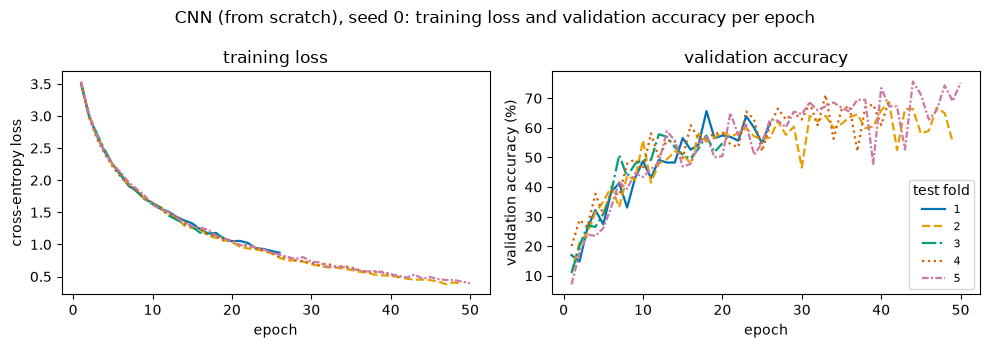

In [16]:
L2_RUN = eval_io.load_run_or_none(L2_RUN_DIR)   # the saved run of L2_CONFIG (support/frozen/)
L2_NAME = "CNN (from scratch)"   # as in the Section 5.1 results table
if L2_RUN:
    L2_dev = eval_io.dev_summary(L2_RUN)
    print(f"{L2_NAME}, seed {L2_RUN['config']['seed']} (Section 5.1 averages over all seeds of this method)")
    print(f"validation accuracy, mean over {L2_dev['folds_done']} folds (%): {L2_dev['val_acc_mean']}; "
          f"total training time {L2_dev['train_min']} min; parameters (millions): {L2_dev['params_M']}")
    if L2_RUN["test_preds"]:
        # M1 and M2 per test fold (M3 is in Section 5)
        print("test accuracy per fold (%):", (eval_io.test_acc(L2_RUN) * 100).round(1).to_dict())
        print("test macro-F1 per fold (%):", (eval_io.test_macro_f1(L2_RUN) * 100).round(1).to_dict())
if L2_RUN is not None and len(L2_RUN["curves"]):
    L2_fig, L2_ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for L2_i, (L2_k, L2_g) in enumerate(L2_RUN["curves"].groupby("fold")):
        L2_style = dict(color=FOLD_COLOURS[L2_i % 5], ls=FOLD_STYLES[L2_i % 5], lw=1.6)   # Section 0.1
        L2_ax[0].plot(L2_g["epoch"], L2_g["train_loss"], label=f"{L2_k}", **L2_style)
        L2_ax[1].plot(L2_g["epoch"], L2_g["val_acc"] * 100, label=f"{L2_k}", **L2_style)   # stored as a fraction
    L2_ax[0].set(title="training loss", xlabel="epoch", ylabel="cross-entropy loss")
    L2_ax[1].set(title="validation accuracy", xlabel="epoch", ylabel="validation accuracy (%)")
    L2_ax[1].legend(title="test fold", fontsize=8, loc="lower right")
    L2_fig.suptitle(f"{L2_NAME}, seed {L2_RUN['config']['seed']}: training loss and validation accuracy per epoch")
    plt.tight_layout(); plt.show()

**The CNN trained from scratch clearly outperforms the hand-crafted baseline on the test folds, and doubling its width makes no clear difference.** It learns useful patterns from the log-mel spectrogram without any pretrained features. It stays below the fine-tuned ResNet-18 (Section 4.3) and the CRNN (Section 4.4), so it is a stable reference rather than the strongest model.

The wider CNN is higher on some test folds and lower on others. Its average gain is smaller than the spread across seeds of either model, and it has about four times the parameters and takes about twice as long per epoch. With three seeds and five folds the spread estimates are rough, so a gap this small should not be read as a real gain or loss.

### 4.3 ImageNet-pretrained ResNet-18 (`L3_`)

#### 4.3.1 Question and why this method
**Q3.** Do ImageNet visual features help on sound spectrograms, and at what compute cost?
- **Why this method:** a log-mel spectrogram is an image-like array, so a network pretrained on natural images may transfer useful low-level filters.
- **Literature:** fine-tuned ImageNet-pretrained ResNets have been reported to reach high accuracy on ESC-50. They were well above the same network trained from random initialisation (Palanisamy et al., 2020). Shin et al. (2021) trained only a new last layer on a frozen ResNet-50 (pretrained on ImageNet without labels). That gave lower ESC-50 accuracy than fine-tuning it.
- **What we test:** both uses, frozen and fully fine-tuned, with ResNet-18 (He et al., 2016), the smallest standard ResNet. We compare accuracy with measured cost.

#### 4.3.2 Sources: own work vs borrowed
| Part | Own work / borrowed | Source (link) |
|---|---|---|
| Model | Borrowed: torchvision ResNet-18, its 1000-class layer replaced by a new 50-class layer. Own work: the wrapper that repeats the one-channel input to three channels and normalises it | [torchvision ResNet-18](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html); He et al., 2016, *Deep Residual Learning for Image Recognition* |
| Pretrained weights | Borrowed: torchvision `ResNet18_Weights.IMAGENET1K_V1` (ImageNet-1k) | [torchvision weights](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html#torchvision.models.ResNet18_Weights); ImageNet: Deng et al., 2009 |

We wrote the input wrapper, the linear probe on cached frozen features, the end-to-end fine-tuning loop and the train / test functions in the implementation cells below.

#### 4.3.3 Settings and implementation
`L3_CONFIG` below shows the full fine-tune run; the other configurations change the fields named here.
- **Input:** the full log-mel scaled to [0, 1] with training statistics, repeated to three channels and normalised with the ImageNet mean and SD.
- **Linear probe (baseline):** the pretrained network is frozen in evaluation mode, so BatchNorm keeps its ImageNet statistics. Only the new last layer is trained.
- **Full fine-tune:** trains every layer and lowers the learning rate from 1e-3 to 1e-4, because a pretrained backbone needs smaller steps than a new layer. It also lowers the epoch cap from 50 to 30. So three settings change at once, and we treat it as one package.
- **From scratch:** changes the starting weights to random, the epoch cap to 60 and the input normalisation: a fixed mean of 0.5 and SD of 0.25 instead of the ImageNet statistics, which no longer apply.
- **Less data:** half and a quarter of each round's training clips, dropped evenly per class. The quarter set is part of the half set, so only the amount of data changes. These runs are validation only, by protocol.
- **Tuning:** nothing was tuned.

In [17]:
L3_CONFIG = {
    "line": "line3",
    "run_name": "r18-ft",
    "date": "2026-10-20",
    "seed": 0,
    # from_scratch for the variant trained from scratch, external_pretrained for linear probe / full fine-tune
    "group": "external_pretrained",
    "question": "Do ImageNet visual features help on sound spectrograms, and at what compute cost?",
    "compare_to": "line3/2026-10-17_r18-lp_s0",
    "changed_variable": "arch+epochs_max+lr",
    "input": "logmel_128x431",
    "epochs_max": 30, "early_stop_patience": 8, "lr": 1e-4, "batch_size": 32,
    # "mode": linear_probe trains only the new 50-class fc layer, full_finetune trains every parameter
    "arch": {"type": "resnet18", "pretrained": "imagenet", "mode": "full_finetune"},
    "weight_decay": 1e-4,
    "grad_clip": 5.0,                      # gradient-norm clipping, a safety net (as in 4.2 / 4.4)
    "norm": "minmax01_train_stats+imagenet",
}
L3_RUN_DIR = eval_io.run_dir(RESULTS, L3_CONFIG)

**Model.** ResNet-18 from torchvision on the full log-mel (no resizing), with ImageNet weights or random weights, and a new 50-class last layer. In the linear probe only that last layer is trained.

In [18]:
# 4.3 ImageNet-pretrained ResNet-18 on the log-mel (linear probe, full fine-tune or from scratch)
import torch
from torch import nn
import torchvision

# GPU if available, otherwise the CPU; the same rule in every neural method
L3_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
L3_CACHE = {"logmel_128x431": COMMON / "logmel_fp16.npy"}
L3_IMAGENET_MEAN, L3_IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


# torchvision ResNet-18 on the full 128 x 431 log-mel (no resizing); new fc layer Linear(512, 50)
class L3_ResNet18(nn.Module):
    def __init__(self, arch, n_classes=50):
        super().__init__()
        if arch["type"] != "resnet18" or arch["mode"] not in ("linear_probe", "full_finetune"):
            raise ValueError(f"unknown arch {arch!r}")
        if arch["pretrained"] == "imagenet":
            self.net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
            mean, std = L3_IMAGENET_MEAN, L3_IMAGENET_STD
        elif arch["pretrained"] == "none":
            # from-scratch variant: no ImageNet normalisation
            self.net = torchvision.models.resnet18(weights=None)
            # only centres [0, 1] inputs; no external statistics
            mean, std = (0.5, 0.5, 0.5), (0.25, 0.25, 0.25)
        else:
            raise ValueError(f"unknown pretrained {arch['pretrained']!r}")
        self.net.fc = nn.Linear(self.net.fc.in_features, n_classes)
        # ImageNet mean / std for pretrained weights, so the inputs match what the filters were trained on
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1), persistent=False)
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1), persistent=False)
        self.frozen = arch["mode"] == "linear_probe"
        self.fc_only_ckpt = self.frozen and arch["pretrained"] == "imagenet"   # see L3_ckpt_state
        if self.frozen:
            for name, p in self.net.named_parameters():
                p.requires_grad = name.startswith("fc.")

    # linear probe: the backbone stays in eval mode, so BatchNorm keeps the ImageNet running statistics
    def train(self, mode=True):
        super().train(mode)
        if self.frozen and mode:
            for name, m in self.net.named_children():
                if name != "fc":
                    m.eval()
        return self

    def features(self, x):                                        # x: (batch, 1, mel, time) in [0, 1]
        # 1 -> 3 channels (a view, no copy), then normalise
        x = (x.expand(-1, 3, -1, -1) - self.mean) / self.std
        n = self.net
        x = n.maxpool(n.relu(n.bn1(n.conv1(x))))
        x = n.layer4(n.layer3(n.layer2(n.layer1(x))))
        return torch.flatten(n.avgpool(x), 1)                     # (batch, 512)

    def forward(self, x):
        return self.net.fc(self.features(x))

**Input and helpers.** Scaling the log-mel to [0, 1] with training statistics, batched prediction, saving and loading checkpoints, and the subsampling used by the runs with 25% and 50% of the training data.

In [19]:
# 4.3 data, prediction and checkpoint helpers

# log-mel of the given rows scaled to [0, 1]; stats = (min, max) over all values of the training rows only
def L3_arrays(config, idx, stats=None):
    x = data.load_logmel(L3_CACHE[config["input"]], idx)          # (n, 1, 128, 431) float32, in dB
    if stats is None:
        # one global range keeps the relative energy across mel bins; per-mel standardisation followed by the
        # ImageNet mean / std would normalise twice and flatten the spectral shape
        stats = (np.float32(x.min()), np.float32(x.max()))
    # values outside the training range are clipped
    x = np.clip((x - stats[0]) / (stats[1] - stats[0]), 0.0, 1.0)
    y = SPLIT.loc[idx, "target"].to_numpy().astype(np.int64)
    return x.astype(np.float32), y, stats


# apply fn to x in batches without gradients and concatenate the results on the CPU
def L3_batched(fn, x, batch_size=64):
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            out.append(fn(torch.as_tensor(x[i:i + batch_size]).to(L3_DEVICE)).cpu())
    return torch.cat(out)


# class probabilities in eval mode (BatchNorm running statistics)
def L3_predict(model, x):
    model.eval()
    return torch.softmax(L3_batched(model, x), dim=1).numpy()


# what ckpt.pt holds: only fc for the ImageNet linear probe, otherwise the whole model
def L3_ckpt_state(model):
    # the frozen backbone is the fixed IMAGENET1K_V1 weights, which L3_ResNet18 rebuilds identically
    sd = model.net.fc.state_dict() if model.fc_only_ckpt else model.state_dict()
    # a CPU copy, so the best weights can stay in memory during training and be written once afterwards
    return {k: v.detach().to("cpu", copy=True) for k, v in sd.items()}


# reload ckpt.pt into a freshly built model; accepts the fc-only file and a full-model file
def L3_load_ckpt(model, path):
    sd = torch.load(path, map_location=L3_DEVICE)
    if set(sd) == {"weight", "bias"}:                             # fc only (ImageNet linear probe)
        if not model.fc_only_ckpt:
            raise ValueError(f"{path} holds only fc, but this model's backbone is not the fixed ImageNet one")
        model.net.fc.load_state_dict(sd)
    else:
        # full-model state dict
        model.load_state_dict(sd)
    return model


# data-size ablation: stratified subsample of the training rows only (validation and test never)
def L3_subsample(idx, frac, seed):
    # one permutation per class with the run seed, so the 25% subset lies inside the 50% one; at least one clip
    rng = np.random.default_rng(seed)
    y = SPLIT.loc[idx, "target"].to_numpy()
    keep = [rng.permutation(idx[y == c])[:max(1, round(frac * (y == c).sum()))] for c in np.unique(y)]
    return np.sort(np.concatenate(keep))

**Training and testing one fold.** The same procedure as Section 4.2: the best validation epoch is kept, then the test fold is predicted once.

In [20]:
# 4.3 train / test functions for one fold

# train, then reload the best checkpoint into a fresh model to predict validation; never touches the test fold
def L3_train_one_fold(config, test_fold, out_dir):
    if config["epochs_max"] < 1:
        raise ValueError("epochs_max must be at least 1")
    gen = eval_io.seed_everything(config["seed"])
    train_idx, val_idx, _ = data.get_round(SPLIT, test_fold)       # training and validation do not use the test fold
    if config.get("train_frac", 1.0) < 1.0:                        # data-size ablation (full fine-tune only)
        train_idx = L3_subsample(train_idx, config["train_frac"], config["seed"])
        print(f"fold {test_fold}: train_frac {config['train_frac']} -> {len(train_idx)} training clips")
    out_dir = Path(out_dir)
    # normalisation statistics from the training rows only
    x_tr, y_tr, stats = L3_arrays(config, train_idx)
    x_va, y_va, _ = L3_arrays(config, val_idx, stats)
    np.savez(out_dir / "norm_stats.npz", min=stats[0], max=stats[1])
    model = L3_ResNet18(config["arch"]).to(L3_DEVICE)
    # total parameters, including the frozen backbone
    n_params = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"fold {test_fold}: mode {config['arch']['mode']}, parameters {n_params:,} total / {n_trainable:,} trainable")
    t0 = time.time()
    if model.frozen:
        # linear probe: the frozen backbone in eval mode is a fixed function, so its 512-d features are
        # computed once and only fc is trained on them (same result as running it every epoch);
        # train_seconds includes this pass
        model.eval()
        inputs_tr, inputs_va, step = L3_batched(model.features, x_tr), L3_batched(model.features, x_va), model.net.fc
    else:
        inputs_tr, inputs_va, step = torch.from_numpy(x_tr), torch.from_numpy(x_va), model
    train_set = torch.utils.data.TensorDataset(inputs_tr, torch.from_numpy(y_tr))
    loader = torch.utils.data.DataLoader(train_set, batch_size=config["batch_size"], shuffle=True, num_workers=0,
                                         worker_init_fn=eval_io.seed_worker, generator=gen)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=config["lr"], weight_decay=config["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    rows, best_acc, best_epoch, wait, best_state = [], -1.0, 0, 0, None
    for epoch in range(1, config["epochs_max"] + 1):
        # linear probe: the backbone stays in eval mode
        model.train()
        total, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(L3_DEVICE), yb.to(L3_DEVICE)
            opt.zero_grad()
            loss = loss_fn(step(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(params, config["grad_clip"])
            opt.step()
            total, n = total + loss.item() * len(yb), n + len(yb)
        model.eval()
        val_acc = float((L3_batched(step, inputs_va).argmax(1).numpy() == y_va).mean())
        rows.append({"epoch": epoch, "train_loss": total / n, "val_acc": val_acc})
        print(f"fold {test_fold} epoch {epoch:2d}  train_loss {total / n:.4f}  val_acc {val_acc:.4f}  ({time.time() - t0:.0f} s)")
        if val_acc > best_acc:
            # strict improvement: ties keep the earlier epoch
            best_acc, best_epoch, wait = val_acc, epoch, 0
            # kept in memory; written once after training
            best_state = L3_ckpt_state(model)
        else:
            wait += 1
            if wait >= config["early_stop_patience"]:
                break
    # compute only: the checkpoint is written after the clock stops
    train_seconds = time.time() - t0
    torch.save(best_state, out_dir / "ckpt.pt")
    # fresh model, then reload the best checkpoint; predict end to end on the log-mel, not on cached features
    model = L3_load_ckpt(L3_ResNet18(config["arch"]).to(L3_DEVICE), out_dir / "ckpt.pt")
    y_hat = L3_predict(model, x_va).argmax(1)
    val_preds = pd.DataFrame({"filename": SPLIT.loc[val_idx, "filename"].to_numpy(), "y_true": y_va, "y_pred": y_hat})
    correct = int((y_hat == y_va).sum())
    metrics = dict(best_epoch=best_epoch, best_val_acc=correct / len(y_va), best_val_correct=correct,
                   val_n=len(y_va), train_seconds=train_seconds, n_params=n_params)
    return metrics, val_preds, pd.DataFrame(rows, columns=["epoch", "train_loss", "val_acc"])


# test phase: reload the best checkpoint and predict the test fold once (no training, no tuning)
def L3_test_one_fold(config, test_fold, out_dir):
    _, _, test_idx = data.get_round(SPLIT, test_fold)
    out_dir = Path(out_dir)
    # training-set statistics saved during training
    s = np.load(out_dir / "norm_stats.npz")
    x_te, y_te, _ = L3_arrays(config, test_idx, (s["min"], s["max"]))
    model = L3_load_ckpt(L3_ResNet18(config["arch"]).to(L3_DEVICE), out_dir / "ckpt.pt")
    probs = L3_predict(model, x_te)
    return pd.DataFrame({"filename": SPLIT.loc[test_idx, "filename"].to_numpy(), "y_true": y_te,
                         "y_pred": probs.argmax(1), "prob_top1": probs.max(1)})

#### 4.3.4 Results and reading
For the fine-tuned run with seed 0, the output gives the validation summary, test accuracy and macro-F1 per fold, and the learning curves. Section 5.1 averages the seeds.

ResNet-18 fine-tuned, seed 0 (Section 5.1 averages over all seeds of this method)
validation accuracy, mean over 5 folds (%): 88.3; total training time 10.5 min; parameters (millions): 11.2
test accuracy per fold (%): {1: 86.0, 2: 82.2, 3: 83.8, 4: 87.2, 5: 85.0}
test macro-F1 per fold (%): {1: 86.1, 2: 81.7, 3: 83.3, 4: 87.0, 5: 84.7}


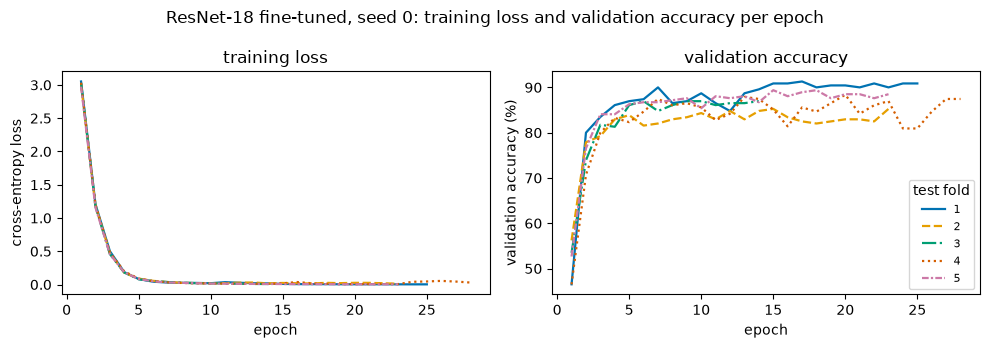

In [21]:
L3_RUN = eval_io.load_run_or_none(L3_RUN_DIR)   # the saved run of L3_CONFIG (support/frozen/)
L3_NAME = "ResNet-18 fine-tuned"   # as in the Section 5.1 results table
if L3_RUN:
    L3_dev = eval_io.dev_summary(L3_RUN)
    print(f"{L3_NAME}, seed {L3_RUN['config']['seed']} (Section 5.1 averages over all seeds of this method)")
    print(f"validation accuracy, mean over {L3_dev['folds_done']} folds (%): {L3_dev['val_acc_mean']}; "
          f"total training time {L3_dev['train_min']} min; parameters (millions): {L3_dev['params_M']}")
    if L3_RUN["test_preds"]:
        # M1 and M2 per test fold (M3 is in Section 5)
        print("test accuracy per fold (%):", (eval_io.test_acc(L3_RUN) * 100).round(1).to_dict())
        print("test macro-F1 per fold (%):", (eval_io.test_macro_f1(L3_RUN) * 100).round(1).to_dict())
if L3_RUN is not None and len(L3_RUN["curves"]):
    L3_fig, L3_ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for L3_i, (L3_k, L3_g) in enumerate(L3_RUN["curves"].groupby("fold")):
        L3_style = dict(color=FOLD_COLOURS[L3_i % 5], ls=FOLD_STYLES[L3_i % 5], lw=1.6)   # Section 0.1
        L3_ax[0].plot(L3_g["epoch"], L3_g["train_loss"], label=f"{L3_k}", **L3_style)
        L3_ax[1].plot(L3_g["epoch"], L3_g["val_acc"] * 100, label=f"{L3_k}", **L3_style)   # stored as a fraction
    L3_ax[0].set(title="training loss", xlabel="epoch", ylabel="cross-entropy loss")
    L3_ax[1].set(title="validation accuracy", xlabel="epoch", ylabel="validation accuracy (%)")
    L3_ax[1].legend(title="test fold", fontsize=8, loc="lower right")
    L3_fig.suptitle(f"{L3_NAME}, seed {L3_RUN['config']['seed']}: training loss and validation accuracy per epoch")
    plt.tight_layout(); plt.show()

**Fully fine-tuning the ImageNet-pretrained ResNet-18 gives the highest test accuracy of all our configurations.** Frozen features alone land at about the level of the from-scratch CNN of Section 4.2. That gap is smaller than the spread across seeds, so we call it no clear difference. Trained from random weights, the ResNet-18 stays well below the fine-tuned network but above the linear probe. This fits with the pretrained weights providing part of the gain; the from-scratch run also changes the epoch cap and the normalisation (a compound comparison), so part of that gap may come from those settings.

With less training data (validation only), accuracy falls with each halving, more sharply from a half to a quarter. The quarter-data runs also vary more from fold to fold than the half- and full-data runs (Section 5.2).

All three configurations have the same 11.2 M parameters. On a T4 GPU, fine-tuning takes about 2.0 min per fold and random initialisation about 2.5 min. The linear probe takes about 0.1 min, because the frozen features are computed once (Section 5.3).

### 4.4 Temporal models: CRNN / LSTM (`L4_`)

#### 4.4.1 Question and why this method
**Q4.** For which sound classes does a model with explicit time modelling do better?
- **Why this method:** sounds differ in how they unfold over time. A bark is a short burst, a clock tick a regular pulse, rain a steady texture. The CNN of Section 4.2 averages its feature map over time, so it does not model the order of events explicitly.
- **CRNN:** a CRNN adds a bidirectional GRU after a convolutional front end. A GRU (gated recurrent unit; Cho et al., 2014) is a recurrent layer that carries a memory from frame to frame.
- **Literature:** on most sound-event detection measures, CRNNs that keep the time axis before the recurrent layer beat the models they were compared with (Çakır et al., 2017). CRNNs were also used for music tagging (Choi et al., 2017) and evaluated on ESC-50 with the official folds (Zhang et al., 2021).
- **Contrast:** a bidirectional LSTM (BiLSTM; Hochreiter and Schmidhuber, 1997) reads pooled log-mel frames directly.

#### 4.4.2 Sources: own work vs borrowed
| Part | Own work / borrowed | Source (link) |
|---|---|---|
| Model | Own implementation in PyTorch. The CRNN layout (convolutional blocks, then a recurrent layer over time) follows the general CRNN design for audio. Our pooling shrinks frequency more than time, adapting the frequency-only pooling of Çakır et al. The LSTM is our own bidirectional LSTM over pooled log-mel frames | CRNN: Çakır et al., 2017; Choi et al., 2017. CRNN on ESC-50: Zhang et al., 2021 (table and page numbers refer to the arXiv preprint 1907.02230). LSTM: Hochreiter & Schmidhuber, 1997. Links in Section 7.2 |
| Pretrained weights | none (trained from scratch) | - |

We wrote the model class (the CRNN and the BiLSTM in one class), the input helpers and the train / test functions in the implementation cells below.

#### 4.4.3 Settings and implementation
`L4_CONFIG` below lists the CRNN settings, and the BiLSTM variant changes only the `arch` field.
- **CRNN:** the convolutional blocks pool frequency more than time. Frequency shrinks 128 → 4, while 26 time steps are left for the GRU.
- **BiLSTM:** two layers, reading log-mel frames pooled in time by 2, so it differs from the CRNN in several design choices at once.
- **Input, training and tuning:** as in Section 4.2, and nothing was tuned.

In [22]:
L4_CONFIG = {
    "line": "line4",
    "run_name": "crnn-baseline",
    "date": "2026-10-10",
    "seed": 0,
    "group": "from_scratch",          # trained on ESC-50 only
    "question": "For which sound classes does modelling time explicitly help?",
    "compare_to": "baseline",
    "changed_variable": "none",
    "input": "logmel_128x431",
    "epochs_max": 50, "early_stop_patience": 8, "lr": 1e-3, "batch_size": 32,
    "arch": {"type": "crnn", "conv_channels": [32, 64, 128, 128], "rnn_hidden": 128, "dropout": 0.3},
    "weight_decay": 1e-4,
    "grad_clip": 5.0,                      # gradient-norm clipping (standard for recurrent layers)
    "norm": "per_mel_train_stats",         # per mel bin, mean / std of the training clips of this round only
}
L4_RUN_DIR = eval_io.run_dir(RESULTS, L4_CONFIG)

**Models and input.** The CRNN and the BiLSTM in one class (chosen by the `arch` field), the per-mel-band standardisation of Section 4.2 and the batched prediction function.

In [23]:
# 4.4 CRNN and LSTM on the log-mel, per-mel standardisation and prediction
import torch
from torch import nn

# GPU if available, otherwise the CPU; the same rule in every neural method
L4_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
L4_CACHE = {"logmel_128x431": COMMON / "logmel_fp16.npy"}


# CRNN (conv blocks, then a BiGRU over 26 time steps) or BiLSTM over pooled frames; outputs averaged over time
class L4_TemporalNet(nn.Module):
    def __init__(self, arch, n_classes=50, n_mels=128):
        super().__init__()
        self.kind = arch["type"]
        h = arch["rnn_hidden"]
        if self.kind == "crnn":
            pools = [(2, 2), (2, 2), (2, 2), (4, 2)]          # (frequency, time)
            blocks, c_in = [], 1
            for c_out, pool in zip(arch["conv_channels"], pools):
                blocks += [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
                           nn.MaxPool2d(pool), nn.Dropout(0.1)]
                c_in = c_out
            self.conv = nn.Sequential(*blocks)
            n_freq = n_mels // 32                                 # 128 -> 4 after the four frequency poolings
            self.rnn = nn.GRU(c_in * n_freq, h, batch_first=True, bidirectional=True)
        elif self.kind == "lstm":
            self.time_pool = nn.AvgPool1d(arch["time_pool"]) if arch["time_pool"] > 1 else nn.Identity()
            self.rnn = nn.LSTM(n_mels, h, num_layers=arch["rnn_layers"], batch_first=True, bidirectional=True,
                               dropout=arch["dropout"] if arch["rnn_layers"] > 1 else 0.0)
        else:
            raise ValueError(f"unknown arch type {arch['type']!r}")
        self.head = nn.Sequential(nn.Dropout(arch["dropout"]), nn.Linear(2 * h, n_classes))

    def forward(self, x):                                         # x: (batch, 1, mel, time)
        if self.kind == "crnn":
            z = self.conv(x)                                      # (batch, channels, freq, time)
            z = z.permute(0, 3, 1, 2).flatten(2)                  # (batch, time, channels * freq)
        else:
            z = self.time_pool(x.squeeze(1)).transpose(1, 2)      # (batch, time, mel)
        out, _ = self.rnn(z)
        return self.head(out.mean(dim=1))


# log-mel of the given rows standardised per mel bin; stats = (mean, std) from the training rows only
def L4_arrays(config, idx, stats=None):
    x = data.load_logmel(L4_CACHE[config["input"]], idx)          # (n, 1, 128, 431) float32
    if stats is None:
        stats = (x.mean(axis=(0, 1, 3), keepdims=True)[0], x.std(axis=(0, 1, 3), keepdims=True)[0] + 1e-6)
    x = (x - stats[0]) / stats[1]
    y = SPLIT.loc[idx, "target"].to_numpy().astype(np.int64)
    return x.astype(np.float32), y, stats


# class probabilities in eval mode (BatchNorm running statistics, dropout off)
def L4_predict(model, x, batch_size=64):
    model.eval()
    probs = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            probs.append(torch.softmax(model(torch.from_numpy(x[i:i + batch_size]).to(L4_DEVICE)), dim=1).cpu())
    return torch.cat(probs).numpy()

**Training and testing one fold.** The same procedure as Section 4.2, with the temporal model.

In [24]:
# 4.4 train / test functions for one fold

# train, then reload the best-epoch checkpoint to predict validation; never touches the test fold
def L4_train_one_fold(config, test_fold, out_dir):
    gen = eval_io.seed_everything(config["seed"])
    train_idx, val_idx, _ = data.get_round(SPLIT, test_fold)       # training and validation do not use the test fold
    out_dir = Path(out_dir)
    # normalisation statistics from the training rows only
    x_tr, y_tr, stats = L4_arrays(config, train_idx)
    x_va, y_va, _ = L4_arrays(config, val_idx, stats)
    np.savez(out_dir / "norm_stats.npz", mean=stats[0], std=stats[1])
    # shuffled mini-batches drawn with the seeded generator
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.from_numpy(x_tr), torch.from_numpy(y_tr)),
                                         batch_size=config["batch_size"], shuffle=True, num_workers=0,
                                         worker_init_fn=eval_io.seed_worker, generator=gen)
    # model, optimiser (Adam with weight decay) and loss
    model = L4_TemporalNet(config["arch"]).to(L4_DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    # epoch log and early-stopping state
    rows, best_acc, best_epoch, wait, t0 = [], -1.0, 0, 0, time.time()
    for epoch in range(1, config["epochs_max"] + 1):
        model.train()
        total, n = 0.0, 0
        # one pass over the training set, with gradient clipping
        for xb, yb in loader:
            xb, yb = xb.to(L4_DEVICE), yb.to(L4_DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), config["grad_clip"])
            opt.step()
            total, n = total + loss.item() * len(yb), n + len(yb)
        # validation accuracy after this epoch
        val_acc = float((L4_predict(model, x_va).argmax(1) == y_va).mean())
        rows.append({"epoch": epoch, "train_loss": total / n, "val_acc": val_acc})
        print(f"fold {test_fold} epoch {epoch:2d}  train_loss {total / n:.4f}  val_acc {val_acc:.4f}")
        if val_acc > best_acc:
            # strict improvement: ties keep the earlier epoch
            best_acc, best_epoch, wait = val_acc, epoch, 0
            torch.save(model.state_dict(), out_dir / "ckpt.pt")
        else:
            wait += 1
            # stop after early_stop_patience epochs without improvement
            if wait >= config["early_stop_patience"]:
                break
    train_seconds = time.time() - t0
    # reload the best checkpoint
    model.load_state_dict(torch.load(out_dir / "ckpt.pt", map_location=L4_DEVICE))
    y_hat = L4_predict(model, x_va).argmax(1)
    # validation predictions and summary metrics of the best epoch
    val_preds = pd.DataFrame({"filename": SPLIT.loc[val_idx, "filename"].to_numpy(), "y_true": y_va, "y_pred": y_hat})
    correct = int((y_hat == y_va).sum())
    metrics = dict(best_epoch=best_epoch, best_val_acc=correct / len(y_va), best_val_correct=correct,
                   val_n=len(y_va), train_seconds=train_seconds, n_params=n_params)
    return metrics, val_preds, pd.DataFrame(rows, columns=["epoch", "train_loss", "val_acc"])


# test phase: reload the best checkpoint and predict the test fold once (no training, no tuning)
def L4_test_one_fold(config, test_fold, out_dir):
    _, _, test_idx = data.get_round(SPLIT, test_fold)
    out_dir = Path(out_dir)
    # training-set statistics saved during training
    s = np.load(out_dir / "norm_stats.npz")
    x_te, y_te, _ = L4_arrays(config, test_idx, (s["mean"], s["std"]))
    model = L4_TemporalNet(config["arch"]).to(L4_DEVICE)
    model.load_state_dict(torch.load(out_dir / "ckpt.pt", map_location=L4_DEVICE))
    # class probabilities for the test fold; keep the top class and its probability
    probs = L4_predict(model, x_te)
    return pd.DataFrame({"filename": SPLIT.loc[test_idx, "filename"].to_numpy(), "y_true": y_te,
                         "y_pred": probs.argmax(1), "prob_top1": probs.max(1)})

#### 4.4.4 Results and reading
The CRNN run with seed 0 comes first: validation summary, test results per fold and learning curves. It then prints both models' validation accuracy over seeds. The per-class comparison with the Section 4.2 CNN is the per-class difference figure in Section 5.3.

CRNN, seed 0 (Section 5.1 averages over all seeds of this method)
validation accuracy, mean over 5 folds (%): 77.6; total training time 8.2 min; parameters (millions): 0.75
test accuracy per fold (%): {1: 70.5, 2: 69.5, 3: 73.5, 4: 71.2, 5: 72.5}
test macro-F1 per fold (%): {1: 70.3, 2: 68.6, 3: 72.2, 4: 69.5, 5: 71.2}


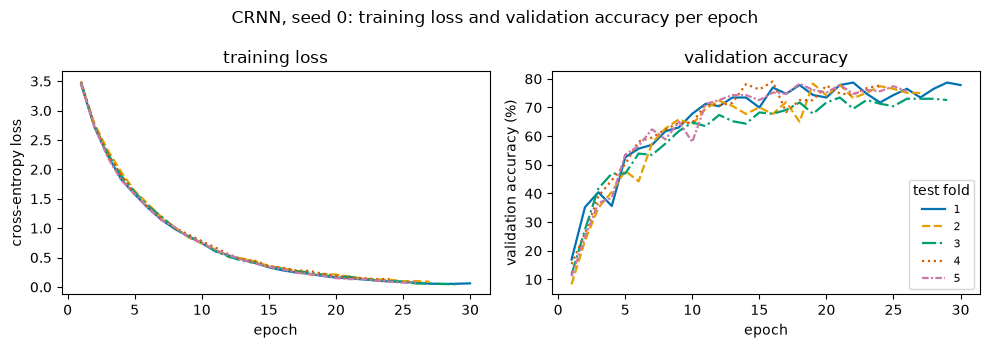

Validation accuracy (%), mean over five folds per seed:
method  seed  val. accuracy (%)
  CRNN     0               77.6
  CRNN     1               79.6
  CRNN     2               79.4
BiLSTM     0               42.1
BiLSTM     1               42.7
BiLSTM     2               42.9
Mean and sample SD across seed means:
        mean  std
method           
CRNN    78.9  1.1
BiLSTM  42.6  0.4


In [25]:
L4_RUN = eval_io.load_run_or_none(L4_RUN_DIR)   # the saved run of L4_CONFIG (support/frozen/)
L4_NAME = "CRNN"   # as in the Section 5.1 results table
# dev summary of the loaded CRNN run (one seed)
if L4_RUN:
    L4_dev = eval_io.dev_summary(L4_RUN)
    print(f"{L4_NAME}, seed {L4_RUN['config']['seed']} (Section 5.1 averages over all seeds of this method)")
    print(f"validation accuracy, mean over {L4_dev['folds_done']} folds (%): {L4_dev['val_acc_mean']}; "
          f"total training time {L4_dev['train_min']} min; parameters (millions): {L4_dev['params_M']}")
    # test-phase numbers, only if test predictions exist
    if L4_RUN["test_preds"]:
        # M1 and M2 per test fold (M3 is in Section 5)
        print("test accuracy per fold (%):", (eval_io.test_acc(L4_RUN) * 100).round(1).to_dict())
        print("test macro-F1 per fold (%):", (eval_io.test_macro_f1(L4_RUN) * 100).round(1).to_dict())
# learning curves of that run, one line per test fold
if L4_RUN is not None and len(L4_RUN["curves"]):
    L4_fig, L4_ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for L4_i, (L4_k, L4_g) in enumerate(L4_RUN["curves"].groupby("fold")):
        # training loss (left) and validation accuracy (right) per epoch
        L4_style = dict(color=FOLD_COLOURS[L4_i % 5], ls=FOLD_STYLES[L4_i % 5], lw=1.6)   # Section 0.1
        L4_ax[0].plot(L4_g["epoch"], L4_g["train_loss"], label=f"{L4_k}", **L4_style)
        L4_ax[1].plot(L4_g["epoch"], L4_g["val_acc"] * 100, label=f"{L4_k}", **L4_style)   # stored as a fraction
    L4_ax[0].set(title="training loss", xlabel="epoch", ylabel="cross-entropy loss")
    L4_ax[1].set(title="validation accuracy", xlabel="epoch", ylabel="validation accuracy (%)")
    L4_ax[1].legend(title="test fold", fontsize=8, loc="lower right")
    L4_fig.suptitle(f"{L4_NAME}, seed {L4_RUN['config']['seed']}: training loss and validation accuracy per epoch")
    plt.tight_layout(); plt.show()

# dev summary: validation accuracy (%) per seed = mean over five folds, then mean and sample SD across seeds
# run names of the three seeds of each method
L4_DEV_RUNS = {"CRNN": [f"line4/{eval_io.run_id({**L4_CONFIG, 'seed': L4_s})}" for L4_s in (0, 1, 2)],
               "BiLSTM": [f"line4/2026-10-11_lstm-baseline_s{L4_s}" for L4_s in (0, 1, 2)]}
# one row per seed; only runs with all five folds count
L4_dev_rows = []
for L4_m, L4_rels in L4_DEV_RUNS.items():
    for L4_rel in L4_rels:
        L4_r = eval_io.load_run_or_none(RESULTS / L4_rel)
        if L4_r is not None and len(L4_r["dev"]) == N_FOLDS:
            L4_dev_rows.append({"method": L4_m, "seed": L4_r["config"]["seed"],
                                "val_acc_pct": L4_r["dev"]["best_val_acc"].mean() * 100})
L4_dev_table = pd.DataFrame(L4_dev_rows, columns=["method", "seed", "val_acc_pct"])
# print only when both methods have all three seeds
if all(set(L4_dev_table.loc[L4_dev_table["method"] == L4_m, "seed"]) == {0, 1, 2} for L4_m in L4_DEV_RUNS):
    print("Validation accuracy (%), mean over five folds per seed:")
    print(L4_dev_table.rename(columns={"val_acc_pct": "val. accuracy (%)"}).round(1).to_string(index=False))
    print("Mean and sample SD across seed means:")
    print(L4_dev_table.groupby("method", sort=False)["val_acc_pct"].agg(["mean", "std"]).round(1).to_string())
else:
    print("Dev summary skipped: all three seeds x five folds of both methods are required.")

**Under the shared training settings, the CRNN reached substantially higher test accuracy than the frame-sequence BiLSTM, with a gap far larger than the difference between seeds.** Our BiLSTM, reading the spectrogram frame by frame, ended far below the CRNN, which lets a small CNN summarise each short window first. The BiLSTM's training loss keeps falling while its validation accuracy stays low, so it fits the training clips far better than it generalises. The CRNN also has higher test recall than the Section 4.2 CNN on most classes (per-class difference figure, Section 5.3).

The CRNN and the BiLSTM differ in more than one way: the CNN front end, GRU versus LSTM, the number of recurrent layers and the sequence length. So we cannot say which difference matters most. The CRNN and the CNN also differ in several ways, so the per-class gains do not show that modelling time is the cause. Optimisation or architecture limits may also explain the BiLSTM result, and a stronger recurrent baseline was not tried.

### 4.5 Augmentation series (`L5_`)

#### 4.5.1 Question and why this method
**Q5.** Does augmentation (SpecAugment, mixup) help the anchor, the CNN of Section 4.2 without augmentation?
- **Why this method:** ESC-50 has only 40 clips per class, so a model trained from scratch can memorise the training folds. Augmentation creates new training examples without new data.
- **Literature:** SpecAugment masks random frequency bands and time spans (Park et al., 2019). Mixup blends two clips and their labels in a random proportion (Zhang et al., 2018). All networks tested by Tokozume et al. (2018) had lower ESC-50 error with between-class learning under the authors' doubled training schedule.
- **What we test:** we add SpecAugment to the anchor, then mixup on top, one step at a time. We then test the same models on test clips with added white noise, training on clean clips as Wang et al. (2020) did. This shows whether augmentation changes noise robustness.
- Where all models fail is analysed in Section 6.1.

#### 4.5.2 Sources: own work vs borrowed
| Part | Own work / borrowed | Source (link) |
|---|---|---|
| Model | Team code: L5 uses the Section 4.2 CNN and training settings; only augmentation varies | Section 4.2.3 |
| Augmentation | Own implementation of SpecAugment frequency / time masking and of mixup, applied to training batches only | [Park et al., 2019, *SpecAugment* (Interspeech)](https://arxiv.org/abs/1904.08779); [Zhang et al., 2018, *mixup* (ICLR)](https://arxiv.org/abs/1710.09412) |
| Pretrained weights | none (trained from scratch) | - |

We wrote the augmentation steps inside the training loop and the helper that predicts on noisy test clips (with the shared `data.add_noise`). The rest of the implementation cells is the anchor's code.

#### 4.5.3 Settings and implementation
`L5_CONFIG` below shows the last step of the series. L5 uses the Section 4.2 CNN and training settings; only augmentation varies (the `augment` field).
- **SpecAugment** (`specaug_f27_t40_m2`): sets 2 frequency masks of up to 27 mel bins and 2 time masks of up to 40 frames to 0. That is the training mean after standardisation.
- **Mixup** (`+mixup_alpha0.2`): draws its mixing weights from Beta(0.2, 0.2).
- **Random numbers:** augmentation has its own random number generator, so shuffling, initial weights and dropout match the anchor run exactly.
- **Noise test:** declared when the configurations were selected. White Gaussian noise at 20, 10 and 0 dB signal-to-noise ratio (SNR; noise seed 0) is added to each test clip's waveform. The log-mel is then recomputed, standardised with that fold's training statistics and classified by the reloaded best checkpoint. There is no training or tuning in this step.
- **Tuning:** the augmentation parameters were fixed before the first run, and nothing was tuned.

In [26]:
L5_CONFIG = {
    "line": "line5",
    "run_name": "specaug-mixup",
    "date": "2026-10-30",
    "seed": 0,
    "group": "from_scratch",          # anchor = the CNN from scratch (4.2)
    "question": "Does augmentation (SpecAugment, mixup) help the anchor model, and where do all models fail?",
    "compare_to": "line5/2026-10-24_specaug_s0",
    "changed_variable": "augment",
    "input": "logmel_128x431",
    # L5 uses the Section 4.2 CNN and training settings; only augmentation varies
    "epochs_max": 50, "early_stop_patience": 8, "lr": 1e-3, "batch_size": 32,
    "arch": {"type": "cnn", "conv_channels": [32, 64, 128, 256], "dropout": 0.3},
    "weight_decay": 1e-4,
    "grad_clip": 5.0,
    "norm": "per_mel_train_stats",
    # all augmentation lives in this one field, parsed by L5_parse_augment:
    # "none" | "specaug_f<F>_t<T>_m<M>" | "specaug_f<F>_t<T>_m<M>+mixup_alpha<a>"
    "augment": "specaug_f27_t40_m2+mixup_alpha0.2",
}
L5_RUN_DIR = eval_io.run_dir(RESULTS, L5_CONFIG)

**Anchor model.** L5 uses the Section 4.2 CNN (`L2_SmallCNN`) and training settings; only augmentation varies.

In [27]:
# 4.5: the Section 4.2 CNN and training settings, plus augmentation in training and a noisy-input prediction helper
import torch
from torch import nn

# L5 uses the Section 4.2 CNN, input and prediction helpers and device: L2_SmallCNN, L2_arrays, L2_predict, L2_DEVICE
# f_max of each cache, used when a log-mel is computed from a waveform
L5_FMAX = {"logmel_128x431": 22050.0}

**Augmentation helpers.** The parser of the `augment` field and SpecAugment masking. Standardisation and batched prediction are those of Section 4.2 (`L2_arrays`, `L2_predict`).

In [28]:
# 4.5 augmentation helpers (standardisation and prediction: L2_arrays and L2_predict, Section 4.2)

# "augment" string -> dict(specaug=(F, T, M) or None, mixup_alpha); a typo raises, never trains unaugmented
def L5_parse_augment(spec):
    out = {"specaug": None, "mixup_alpha": 0.0}
    if spec == "none":
        return out
    for part in str(spec).split("+"):
        m_spec = re.fullmatch(r"specaug_f(\d+)_t(\d+)_m(\d+)", part)
        m_mix = re.fullmatch(r"mixup_alpha(\d+(?:\.\d+)?)", part)
        if m_spec and out["specaug"] is None:
            out["specaug"] = tuple(int(v) for v in m_spec.groups())
        elif m_mix and out["mixup_alpha"] == 0.0 and float(m_mix.group(1)) > 0:
            out["mixup_alpha"] = float(m_mix.group(1))
        else:
            raise ValueError(f"cannot parse augment part {part!r} of {spec!r}")
    return out


# SpecAugment frequency and time masking (no time warping) on normalised log-mels (batch, 1, mel, time)
def L5_spec_augment(xb, f_max, t_max, n_masks, gen):
    # per clip, n_masks bands of width U{0..f_max} and n_masks spans of width U{0..t_max} are set to 0, the
    # training mean after per-mel standardisation; the CPU generator gen keeps the masks device-independent
    # and separate from the global torch random state
    b, _, n_mel, n_t = xb.shape
    keep = torch.ones(b, 1, n_mel, n_t, dtype=torch.bool)
    for size, axis_len, dim in ((f_max, n_mel, 2), (t_max, n_t, 3)):
        for _ in range(n_masks):
            w = torch.randint(0, size + 1, (b,), generator=gen)
            start = (torch.rand(b, generator=gen) * (axis_len - w + 1)).long()
            pos = torch.arange(axis_len)[None, :]
            band = (pos >= start[:, None]) & (pos < (start + w)[:, None])          # (b, axis_len)
            keep &= ~(band[:, None, :, None] if dim == 2 else band[:, None, None, :])
    return xb * keep.to(xb.device)

**Training, testing and the noise test.**
- **Train:** the Section 4.2 procedure plus augmentation of the training batches only. With `augment` set to `none` it computes exactly what the anchor computes.
- **Test:** predicts the clean test fold once.
- **Noise test:** predicts clips with added white noise (the test fold in the final phase), for the robustness comparison in Section 5.3.

In [29]:
# 4.5 train / test functions for one fold, and the robustness predictions

# as L2_train_one_fold plus augmentation of training batches only (same computation when "augment" is "none")
def L5_train_one_fold(config, test_fold, out_dir):
    gen = eval_io.seed_everything(config["seed"])
    train_idx, val_idx, _ = data.get_round(SPLIT, test_fold)       # training and validation do not use the test fold
    out_dir = Path(out_dir)
    aug = L5_parse_augment(config["augment"])
    # separate random streams: augmentation does not change the anchor's shuffling, initialisation or dropout
    aug_gen = torch.Generator().manual_seed(int(config["seed"]) + 10_000)
    mix_rng = np.random.default_rng(int(config["seed"]) + 20_000)
    # normalisation statistics from the training rows only
    x_tr, y_tr, stats = L2_arrays(config, train_idx)
    x_va, y_va, _ = L2_arrays(config, val_idx, stats)
    np.savez(out_dir / "norm_stats.npz", mean=stats[0], std=stats[1])
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.from_numpy(x_tr), torch.from_numpy(y_tr)),
                                         batch_size=config["batch_size"], shuffle=True, num_workers=0,
                                         worker_init_fn=eval_io.seed_worker, generator=gen)
    model = L2_SmallCNN(config["arch"]).to(L2_DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    rows, best_acc, best_epoch, wait, t0 = [], -1.0, 0, 0, time.time()
    for epoch in range(1, config["epochs_max"] + 1):
        model.train()
        total, n = 0.0, 0
        for xb, yb in loader:
            if aug["specaug"] is not None:                         # SpecAugment first, then mixup
                xb = L5_spec_augment(xb, *aug["specaug"], aug_gen)
            xb, yb = xb.to(L2_DEVICE), yb.to(L2_DEVICE)
            opt.zero_grad()
            if aug["mixup_alpha"] > 0:
                # mixup: one lam per batch, partner = a random permutation of the batch, mixed cross-entropy
                a = aug["mixup_alpha"]
                lam = float(mix_rng.beta(a, a))
                perm = torch.randperm(len(yb), generator=aug_gen).to(L2_DEVICE)
                out = model(lam * xb + (1 - lam) * xb[perm])
                loss = lam * loss_fn(out, yb) + (1 - lam) * loss_fn(out, yb[perm])
            else:
                loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), config["grad_clip"])
            opt.step()
            total, n = total + loss.item() * len(yb), n + len(yb)
        # clean validation set (no augmentation)
        val_acc = float((L2_predict(model, x_va).argmax(1) == y_va).mean())
        rows.append({"epoch": epoch, "train_loss": total / n, "val_acc": val_acc})
        print(f"fold {test_fold} epoch {epoch:2d}  train_loss {total / n:.4f}  val_acc {val_acc:.4f}")
        if val_acc > best_acc:
            # strict improvement: ties keep the earlier epoch
            best_acc, best_epoch, wait = val_acc, epoch, 0
            torch.save(model.state_dict(), out_dir / "ckpt.pt")
        else:
            wait += 1
            if wait >= config["early_stop_patience"]:
                break
    train_seconds = time.time() - t0
    # reload the best checkpoint
    model.load_state_dict(torch.load(out_dir / "ckpt.pt", map_location=L2_DEVICE))
    y_hat = L2_predict(model, x_va).argmax(1)
    val_preds = pd.DataFrame({"filename": SPLIT.loc[val_idx, "filename"].to_numpy(), "y_true": y_va, "y_pred": y_hat})
    correct = int((y_hat == y_va).sum())
    metrics = dict(best_epoch=best_epoch, best_val_acc=correct / len(y_va), best_val_correct=correct,
                   val_n=len(y_va), train_seconds=train_seconds, n_params=n_params)
    return metrics, val_preds, pd.DataFrame(rows, columns=["epoch", "train_loss", "val_acc"])


# test phase: reload the best checkpoint and predict the test fold once (no training, no tuning)
def L5_test_one_fold(config, test_fold, out_dir):
    _, _, test_idx = data.get_round(SPLIT, test_fold)
    out_dir = Path(out_dir)
    # training-set statistics saved during training
    s = np.load(out_dir / "norm_stats.npz")
    x_te, y_te, _ = L2_arrays(config, test_idx, (s["mean"], s["std"]))
    model = L2_SmallCNN(config["arch"]).to(L2_DEVICE)
    model.load_state_dict(torch.load(out_dir / "ckpt.pt", map_location=L2_DEVICE))
    probs = L2_predict(model, x_te)
    return pd.DataFrame({"filename": SPLIT.loc[test_idx, "filename"].to_numpy(), "y_true": y_te,
                         "y_pred": probs.argmax(1), "prob_top1": probs.max(1)})


# robustness: predict clips idx with white noise at snr_db, using the fold's reloaded best checkpoint
def L5_noisy_preds(config, fold, out_dir, idx, snr_db, noise_seed):
    out_dir = Path(out_dir)
    # test_idx for the test folds, validation rows otherwise
    idx = np.asarray(idx)
    rng = data.noise_rng(noise_seed, fold, snr_db)                 # once per (fold, condition)
    mels = []
    # split order, one clip per call (add_noise / logmel reject batches)
    for i in idx:
        x, _ = data.load_waveform(ROOT / "data/ESC-50-master/audio", SPLIT, [i])[0]
        x = data.add_noise(x, snr_db, rng)
        # (1, 128, 431), fp16-rounded like the cache
        mels.append(data.logmel_from_waveform(x, f_max=L5_FMAX[config["input"]]))
    # training-set statistics of this fold's checkpoint
    s = np.load(out_dir / "norm_stats.npz")
    xs = ((np.stack(mels) - s["mean"]) / s["std"]).astype(np.float32)
    model = L2_SmallCNN(config["arch"]).to(L2_DEVICE)
    model.load_state_dict(torch.load(out_dir / "ckpt.pt", map_location=L2_DEVICE))
    probs = L2_predict(model, xs)
    return pd.DataFrame({"filename": SPLIT.loc[idx, "filename"].to_numpy(),
                         "y_true": SPLIT.loc[idx, "target"].to_numpy().astype(np.int64),
                         "y_pred": probs.argmax(1), "prob_top1": probs.max(1)})

#### 4.5.4 Results and reading
We show seed 0 of SpecAugment + mixup here, with its validation summary, per-fold test accuracy and macro-F1, and learning curves. Section 5.1 averages the seeds, and Section 5.3 shows the noisy-test results.

CNN + SpecAugment + mixup, seed 0 (Section 5.1 averages over all seeds of this method)
validation accuracy, mean over 5 folds (%): 59.1; total training time 10.9 min; parameters (millions): 0.4
test accuracy per fold (%): {1: 51.0, 2: 56.8, 3: 55.5, 4: 55.0, 5: 61.5}
test macro-F1 per fold (%): {1: 48.0, 2: 54.3, 3: 53.6, 4: 52.9, 5: 60.8}


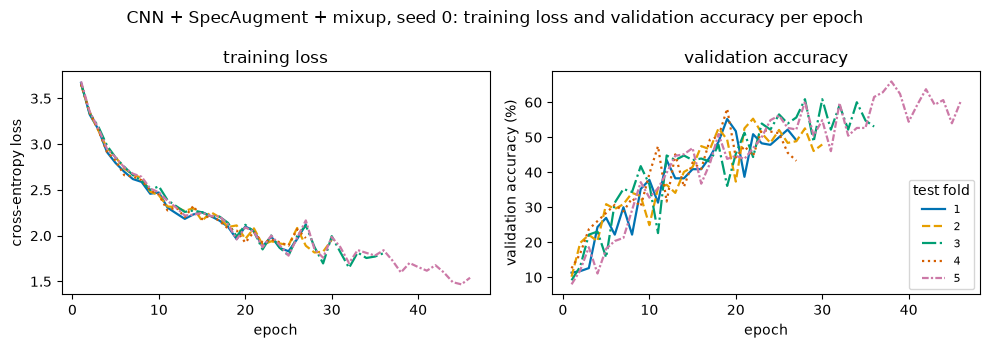

In [30]:
L5_RUN = eval_io.load_run_or_none(L5_RUN_DIR)   # the saved run of L5_CONFIG (support/frozen/)
L5_NAME = "CNN + SpecAugment + mixup"   # as in the Section 5.1 results table
if L5_RUN:
    L5_dev = eval_io.dev_summary(L5_RUN)
    print(f"{L5_NAME}, seed {L5_RUN['config']['seed']} (Section 5.1 averages over all seeds of this method)")
    print(f"validation accuracy, mean over {L5_dev['folds_done']} folds (%): {L5_dev['val_acc_mean']}; "
          f"total training time {L5_dev['train_min']} min; parameters (millions): {L5_dev['params_M']}")
    if L5_RUN["test_preds"]:
        # M1 and M2 per test fold (M3 is in Section 5)
        print("test accuracy per fold (%):", (eval_io.test_acc(L5_RUN) * 100).round(1).to_dict())
        print("test macro-F1 per fold (%):", (eval_io.test_macro_f1(L5_RUN) * 100).round(1).to_dict())
if L5_RUN is not None and len(L5_RUN["curves"]):
    L5_fig, L5_ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for L5_i, (L5_k, L5_g) in enumerate(L5_RUN["curves"].groupby("fold")):
        L5_style = dict(color=FOLD_COLOURS[L5_i % 5], ls=FOLD_STYLES[L5_i % 5], lw=1.6)   # Section 0.1
        L5_ax[0].plot(L5_g["epoch"], L5_g["train_loss"], label=f"{L5_k}", **L5_style)
        L5_ax[1].plot(L5_g["epoch"], L5_g["val_acc"] * 100, label=f"{L5_k}", **L5_style)   # stored as a fraction
    L5_ax[0].set(title="training loss", xlabel="epoch", ylabel="cross-entropy loss")
    L5_ax[1].set(title="validation accuracy", xlabel="epoch", ylabel="validation accuracy (%)")
    L5_ax[1].legend(title="test fold", fontsize=8, loc="lower right")
    L5_fig.suptitle(f"{L5_NAME}, seed {L5_RUN['config']['seed']}: training loss and validation accuracy per epoch")
    plt.tight_layout(); plt.show()

**Under the shared training budget, neither SpecAugment nor SpecAugment plus mixup improved the anchor CNN: each added step lowered test accuracy.** This holds under our fixed schedule, although all networks tested by Tokozume et al. (2018) had lower ESC-50 error with between-class learning under the authors' doubled training schedule. The learning curves in Section 5.3 show that neither augmentation lifts the validation curve within the epoch cap. We did not try longer training or stronger augmentation, so longer schedules might narrow the gap a little.

## 5. Results

This section reports the results of all methods on the same folds. Section 5.1 gives the main test results, Section 5.2 the validation results of every configuration, Section 5.3 the remaining figures, Section 5.4 the comparison with published ESC-50 results, and Section 5.5 short answers to the five questions.

### 5.1 Results table

We compute the table from the saved test predictions of each run. Rows are grouped into non-deep (MFCC statistics), trained from scratch and ImageNet-pretrained, as in the `group` column.

**How we average.**
1. For each fold we first average all available seeds (three for most models, one for the SVM).
2. We then report the mean and standard deviation over the five folds, so the ± shows how much the result changes from fold to fold.
3. Per-seed details are in the second table.

**Two identical rows.** The rows "CNN (from scratch)" and "CNN anchor (no augmentation)" show the same fold accuracies. The anchor is a separate set of runs in the augmentation series, with the same model and training settings as the method-2 CNN. It gave identical test predictions. We list it under its own name because the augmentation comparisons use it.

**Metrics.**
- **Test accuracy** (column "test accuracy (%)"): the main number, because published ESC-50 results report it.
- **Macro-F1** (column "macro-F1 (%)"): the average F1 over the 50 classes. In our results macro-F1 is within 3 points of accuracy for every configuration in the results table. With balanced classes, accuracy equals the mean per-class recall, while macro-F1 also depends on per-class precision.
- **Per-class view:** the confusion matrix later in this section and the per-class recall heatmap in Section 5.3 show which classes fail and what they are mistaken for.

**No clear difference.**
- A method's seed spread (column "seed spread") is the range of its per-seed five-fold means.
- When the gap between two methods is smaller than both seed spreads, we call it "no clear difference" and do not rank them.
- In the paired comparisons and the noise-robustness comparisons (Section 5.3), gaps and seed spreads are computed in this notebook from unrounded means and rounded once for display (a value of exactly 0.85 shows as 0.9). The tables show each value rounded on its own. The SVM has one seed, so its seed spread is shown as n/a.

The functions that compute these numbers are in `support/eval_io.py`; a cell after the overview chart lists where each one is defined.

In [31]:
# Results table: the selected runs of each method (one per seed), summarised by eval_io.final_table.
# the CNN anchor is a separate run of the CNN (from scratch) configuration, listed under its own name for Section 4.5
FINAL_RUNS = {
    "MFCC + SVM": ["line1/2026-10-17_mfcc-svm_s0"],
    "MFCC + random forest": ["line1/2026-10-20_mfcc-rf_s0", "line1/2026-10-20_mfcc-rf_s1", "line1/2026-10-20_mfcc-rf_s2"],
    "CNN (from scratch)": ["line2/2026-10-16_cnn-baseline_s0", "line2/2026-10-16_cnn-baseline_s1", "line2/2026-10-16_cnn-baseline_s2"],
    "CNN 2x width": ["line2/2026-10-31_cnn-wider_s0", "line2/2026-10-31_cnn-wider_s1", "line2/2026-10-31_cnn-wider_s2"],
    "ResNet-18 linear probe": ["line3/2026-10-17_r18-lp_s0", "line3/2026-10-17_r18-lp_s1", "line3/2026-10-17_r18-lp_s2"],
    "ResNet-18 fine-tuned": ["line3/2026-10-20_r18-ft_s0", "line3/2026-10-20_r18-ft_s1", "line3/2026-10-20_r18-ft_s2"],
    "ResNet-18 random init.": ["line3/2026-10-28_r18-scratch_s0", "line3/2026-10-28_r18-scratch_s1", "line3/2026-10-28_r18-scratch_s2"],
    "CRNN": ["line4/2026-10-10_crnn-baseline_s0", "line4/2026-10-10_crnn-baseline_s1", "line4/2026-10-10_crnn-baseline_s2"],
    "BiLSTM": ["line4/2026-10-11_lstm-baseline_s0", "line4/2026-10-11_lstm-baseline_s1", "line4/2026-10-11_lstm-baseline_s2"],
    "CNN anchor (no augmentation)": ["line5/2026-10-18_anchor-noaug_s0", "line5/2026-10-18_anchor-noaug_s1", "line5/2026-10-18_anchor-noaug_s2"],
    "CNN + SpecAugment": ["line5/2026-10-24_specaug_s0", "line5/2026-10-24_specaug_s1", "line5/2026-10-24_specaug_s2"],
    "CNN + SpecAugment + mixup": ["line5/2026-10-30_specaug-mixup_s0", "line5/2026-10-30_specaug-mixup_s1", "line5/2026-10-30_specaug-mixup_s2"],
}
if FINAL_RUNS:
    RESULTS_TABLE, SEED_DETAIL = eval_io.final_table(RESULTS, FINAL_RUNS, expected_split_sha256=data.EXPECTED_SPLIT_SHA256)
else:
    RESULTS_TABLE, SEED_DETAIL = pd.DataFrame(), pd.DataFrame()
GROUP_NAMES = {"non_deep": "non-deep (MFCC statistics)", "from_scratch": "trained from scratch",
               "external_pretrained": "ImageNet-pretrained"}
# the same values, shown with readable column names (training time is in Section 5.3, the run fingerprint in config_hash)
with pd.option_context("display.width", 250, "display.max_columns", None):
    display(RESULTS_TABLE.assign(group=RESULTS_TABLE["group"].map(GROUP_NAMES),
                                 seed_spread=RESULTS_TABLE["seed_spread"].astype(object).where(RESULTS_TABLE["seed_spread"].notna(), "n/a (one seed)"))
            .set_index("method")[
        ["group", "seeds", "mean", "std_over_folds", "macro_f1", "macro_f1_std", "seed_spread", "folds"]].rename(columns={
        "mean": "test accuracy (%)", "std_over_folds": "SD over folds", "macro_f1": "macro-F1 (%)", "macro_f1_std": "macro-F1 SD",
        "seed_spread": "seed spread", "folds": "accuracy per test fold 1-5 (%)"}))

,group,seeds,test accuracy (%),SD over folds,macro-F1 (%),macro-F1 SD,seed spread,accuracy per test fold 1-5 (%)
method,,,,,,,,
MFCC + random forest,non-deep (MFCC statistics),3,49.7,2.7,46.9,2.9,0.1,45.5 / 50.2 / 52.4 / 49.0 / 51.5
MFCC + SVM,non-deep (MFCC statistics),1,46.6,3.9,45.2,3.6,n/a (one seed),41.2 / 48.2 / 48.0 / 51.2 / 44.2
CRNN,trained from scratch,3,73.2,1.6,72.3,1.4,3.0,71.5 / 72.6 / 75.8 / 73.6 / 72.4
ResNet-18 random init.,trained from scratch,3,69.1,3.2,67.8,3.2,2.7,67.5 / 66.8 / 70.2 / 74.2 / 66.7
CNN 2x width,trained from scratch,3,64.2,2.1,62.8,2.3,5.9,65.9 / 63.7 / 66.5 / 63.9 / 61.1
CNN (from scratch),trained from scratch,3,63.4,2.7,62.0,2.9,2.8,61.0 / 64.1 / 60.2 / 66.8 / 64.7
CNN anchor (no augmentation),trained from scratch,3,63.4,2.7,62.0,2.9,2.8,61.0 / 64.1 / 60.2 / 66.8 / 64.7
CNN + SpecAugment,trained from scratch,3,60.8,2.6,59.0,2.6,2.0,56.6 / 61.4 / 63.2 / 62.4 / 60.6
CNN + SpecAugment + mixup,trained from scratch,3,57.1,2.7,55.1,3.2,3.0,55.7 / 56.8 / 55.8 / 55.5 / 61.9


In [32]:
SEED_DETAIL.set_index(["method", "seed"])   # test accuracy (%) of every seed

fold1  fold2  fold3  fold4  fold5  mean
method                       seed                                         
MFCC + SVM                   0      41.2   48.2   48.0   51.2   44.2  46.6
MFCC + random forest         0      46.0   50.7   51.7   49.5   51.0  49.8
                             1      45.0   49.5   53.0   48.0   53.0  49.7
                             2      45.5   50.2   52.5   49.5   50.5  49.6
CNN (from scratch)           0      59.0   63.2   50.7   68.2   68.2  61.9
                             1      61.0   64.0   61.5   68.2   63.0  63.6
                             2      63.0   65.0   68.5   64.0   62.7  64.6
CNN 2x width                 0      68.8   66.0   68.5   59.0   58.2  64.1
                             1      68.2   62.0   66.2   70.2   69.2  67.2
                             2      60.8   63.0   64.8   62.5   55.8  61.4
ResNet-18 linear probe       0      63.2   60.8   63.2   66.0   63.7  63.4
                             1      62.7   62.7   66.5   65.8   64.5  64.4
                             2      60.5   63.5   61.5   66.0   63.0  62.9
ResNet-18 fine-tuned         0      86.0   82.2   83.8   87.2   85.0  84.8
                             1      85.8   80.0   85.2   85.0   86.5  84.5
                             2      85.5   80.8   87.5   85.8   84.2  84.8
ResNet-18 random init.       0      70.2   67.0   69.5   75.5   71.0  70.6
                             1      65.5   66.8   72.0   73.8   62.0  68.0
                             2      66.8   66.8   69.2   73.5   67.0  68.6
CRNN                         0      70.5   69.5   73.5   71.2   72.5  71.4
                             1      69.8   76.2   77.0   74.0   71.2  73.6
                             2      74.2   72.0   76.8   75.5   73.5  74.4
BiLSTM                       0      39.8   40.8   41.8   38.0   35.8  39.2
                             1      32.8   37.8   42.0   41.0   36.5  38.0
                             2      33.0   39.8   42.8   36.0   40.5  38.4
CNN anchor (no augmentation) 0      59.0   63.2   50.7   68.2   68.2  61.9
                             1      61.0   64.0   61.5   68.2   63.0  63.6
                             2      63.0   65.0   68.5   64.0   62.7  64.6
CNN + SpecAugment            0      50.7   64.0   65.8   58.8   59.8  59.8
                             1      57.8   60.8   61.8   66.0   62.7  61.8
                             2      61.3   59.5   62.3   62.5   59.2  61.0
CNN + SpecAugment + mixup    0      51.0   56.8   55.5   55.0   61.5  56.0
                             1      56.0   62.3   50.7   62.5   63.2  59.0
                             2      60.0   51.2   61.0   49.0   61.0  56.4

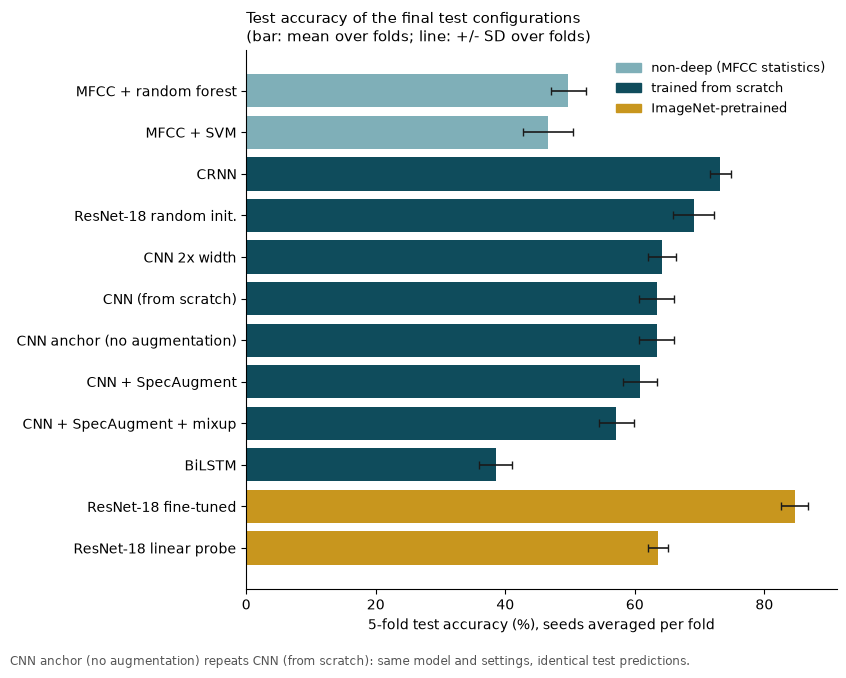

In [33]:
if len(RESULTS_TABLE):
    fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(RESULTS_TABLE) + 1.4))
    # bar colour = method group (the group colours of the Section 5 figures)
    ov_colours = {"non_deep": "#7FAFB8", "from_scratch": "#0F4C5C", "external_pretrained": "#C8961E"}
    ax.barh(RESULTS_TABLE["method"], RESULTS_TABLE["mean"], xerr=RESULTS_TABLE["std_over_folds"],
            color=RESULTS_TABLE["group"].map(ov_colours), error_kw={"ecolor": "#1A1A1A", "lw": 1.2, "capsize": 3})
    ax.invert_yaxis(); ax.set_xlabel("5-fold test accuracy (%), seeds averaged per fold")
    ax.set_title("Test accuracy of the final test configurations\n(bar: mean over folds; line: +/- SD over folds)", fontsize=11, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(handles=[matplotlib.patches.Patch(color=c, label=GROUP_NAMES[g]) for g, c in ov_colours.items()],
              frameon=False, fontsize=9, loc="upper right")
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    fig.text(0.01, 0.01, "CNN anchor (no augmentation) repeats CNN (from scratch): same model and settings, identical test predictions.",
             ha="left", va="bottom", fontsize=8.5, color="#555")
    plt.show()

**Overview chart.** Each bar is a configuration's test accuracy, averaged over the five folds with seeds averaged per fold. The line through each bar is the SD over folds. The CNN anchor bar repeats the CNN (from scratch): same model, same settings, identical test predictions (Section 5.1).

The fine-tuned ResNet-18 is far ahead, and the CRNN is the best model trained only on ESC-50. The MFCC models and the BiLSTM are at the bottom.

**How the metrics are computed.** The functions behind the test metrics in this section (test accuracy, macro-F1, confusion matrix, per-class recall and the results table) are in the shipped helper `support/eval_io.py`, imported in Section 0.3. The next cell prints where each one is defined, so it can be read there.

In [34]:
# Where the eval_io functions behind the numbers in this section are defined (the helper support/eval_io.py).
for f in [eval_io.test_acc, eval_io.macro_f1, eval_io.test_macro_f1, eval_io.confusion, eval_io.per_class_recall, eval_io.final_table]:
    print(f"eval_io.{f.__name__}: support/eval_io.py, line {inspect.getsourcelines(f)[1]}")

eval_io.test_acc: support/eval_io.py, line 498
eval_io.macro_f1: support/eval_io.py, line 503
eval_io.test_macro_f1: support/eval_io.py, line 514
eval_io.confusion: support/eval_io.py, line 519
eval_io.per_class_recall: support/eval_io.py, line 528
eval_io.final_table: support/eval_io.py, line 674


In [35]:
# M3: per-class test recall (%) of every method, all seeds and folds combined (shown as the heatmap in Section 5.3).


def pred_key(runs):
    """Fingerprint of a method's test predictions (all seeds and folds), to find methods with identical predictions."""
    return tuple((r["config"]["seed"], k, tuple(p.sort_values("filename")["y_pred"].astype(int)))
                 for r in sorted(runs, key=lambda r: r["config"]["seed"]) for k, p in sorted(r["test_preds"].items()))


if FINAL_RUNS:
    # the test runs of every method in the results table (also used in Sections 5.3, 6.1 and 7.1)
    TABLE_RUNS = eval_io.load_final_runs(RESULTS, FINAL_RUNS)
    CLASS_NAMES = SPLIT.drop_duplicates("target").sort_values("target")["category"].tolist()
    PER_CLASS = eval_io.per_class_recall(TABLE_RUNS, CLASS_NAMES)
    # method -> the first method (FINAL_RUNS order) with identical test predictions; the CNN anchor maps to
    # CNN (from scratch), so the per-class heatmap, the cost figure and the Section 6.1 error table show that model once
    SAME_AS = {}
    for m, rs in TABLE_RUNS.items():
        SAME_AS[m] = next((k for k in SAME_AS if SAME_AS[k] == k and pred_key(TABLE_RUNS[k]) == pred_key(rs)), m)

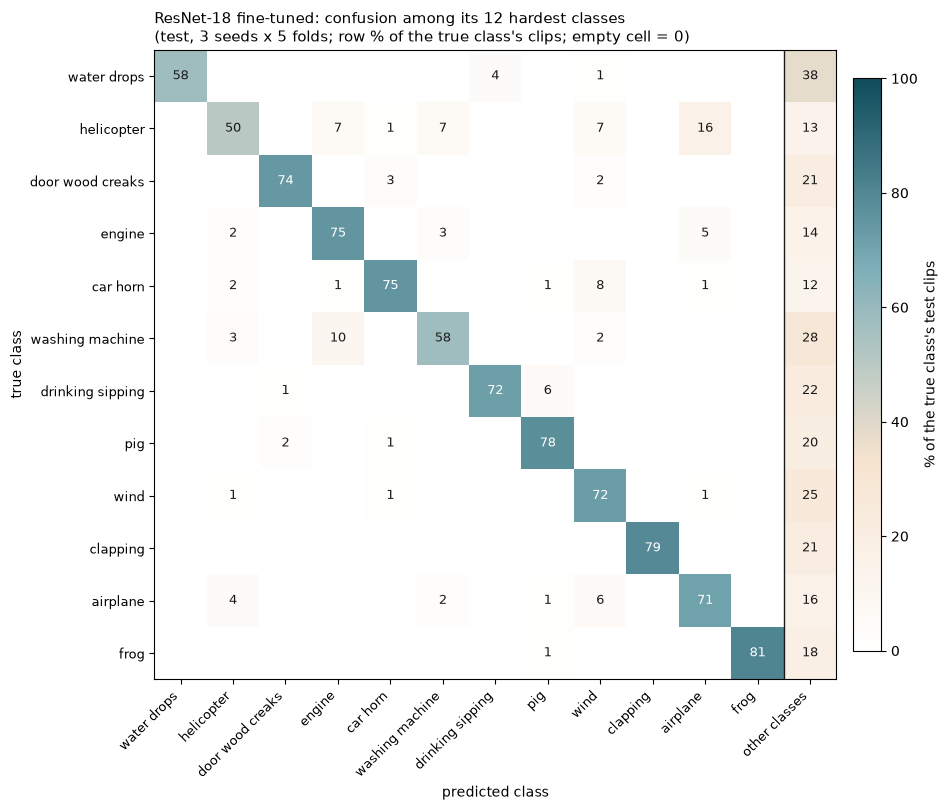

ResNet-18 fine-tuned, test recall of its three hardest classes (%): helicopter 50.0, water drops 57.5, washing machine 57.5; largest confusion among these 12 classes: helicopter -> airplane (16% of helicopter's clips); errors going to classes outside the group: 69%


In [36]:
# M3: confusion matrix of the best method among its 12 hardest classes (row %, all seeds and test folds).
# shared by the figures below: colour palette, readable class names, heatmap class order
FIG_TEAL, FIG_GOLD, FIG_MID, FIG_APRICOT = "#0F4C5C", "#C8961E", "#7FAFB8", "#F6E3CF"
FIG_SEQ = matplotlib.colors.LinearSegmentedColormap.from_list("slides_seq", ["#FFFFFF", FIG_APRICOT, FIG_MID, FIG_TEAL])
# number of hardest classes shown
N_HARD = 12
if FINAL_RUNS:
    # readable class names (underscores replaced by spaces)
    FIG_NAMES = [str(n).replace("_", " ") for n in CLASS_NAMES]
    # per-class recall table indexed by the readable names
    PER_CLASS_N = PER_CLASS.set_axis(FIG_NAMES, axis=0)
    # methods with identical test predictions appear once (the CNN anchor = CNN (from scratch), SAME_AS above)
    HEAT_METHODS = [m for m in RESULTS_TABLE["method"] if SAME_AS[m] == m]
    # class order shared by the heatmaps: mean recall over the distinct methods
    HEAT_ORDER = PER_CLASS_N[HEAT_METHODS].mean(axis=1).sort_values(kind="stable").index.tolist()   # hardest class first
    # best method = highest mean test accuracy in the results table, and its confusion matrix
    BEST = RESULTS_TABLE.sort_values("mean", ascending=False)["method"].iloc[0]
    CM = eval_io.confusion(TABLE_RUNS[BEST]).values
    # pick the 12 classes with the lowest recall of the best method, kept in heatmap order
    best_recall = PER_CLASS_N[BEST]
    hard_set = set(best_recall.sort_values(kind="stable").index[:N_HARD])
    hard = [c for c in HEAT_ORDER if c in hard_set]
    # rows of these classes; columns: these classes plus one column for all other classes
    idx = [FIG_NAMES.index(c) for c in hard]
    rows = CM[idx]
    sub = rows[:, idx]
    # convert counts to % of each true class's clips
    share = 100 * np.column_stack([sub, rows.sum(axis=1) - sub.sum(axis=1)]) / rows.sum(axis=1, keepdims=True).clip(min=1)
    # draw the heatmap and print the cell values above 0
    fig, ax = plt.subplots(figsize=(10, 8.2))
    im = ax.imshow(share, cmap=FIG_SEQ, vmin=0, vmax=100)
    for i in range(share.shape[0]):
        for j in range(share.shape[1]):
            if round(share[i, j]) > 0:
                ax.text(j, i, f"{share[i, j]:.0f}", ha="center", va="center", fontsize=9,
                        color="white" if share[i, j] > 68 else "#1A1A1A")   # dark text on the pale cells
    # axis labels, separator before the other-classes column, colour bar
    ax.set_xticks(range(len(hard) + 1), hard + ["other classes"], rotation=45, ha="right", fontsize=9.5)
    ax.set_yticks(range(len(hard)), hard, fontsize=9.5)
    ax.axvline(len(hard) - 0.5, color="#1A1A1A", lw=1)
    ax.set_xlabel("predicted class", fontsize=10); ax.set_ylabel("true class", fontsize=10)
    n_seeds = len(TABLE_RUNS[BEST])
    ax.set_title(f"{BEST}: confusion among its {len(hard)} hardest classes\n(test, {n_seeds} seeds x 5 folds; "
                 "row % of the true class's clips; empty cell = 0)", fontsize=11, loc="left")
    plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="% of the true class's test clips")
    plt.tight_layout()
    plt.show()
    # largest off-diagonal share among these classes, and how many errors leave the group
    off = share[:, :len(hard)].copy(); np.fill_diagonal(off, 0)
    i_max, j_max = np.unravel_index(int(np.argmax(off)), off.shape)
    errors = rows.sum() - np.trace(sub)
    outside = (rows.sum(axis=1) - sub.sum(axis=1)).sum()
    hardest = best_recall.sort_values(kind="stable")
    print(f"{BEST}, test recall of its three hardest classes (%): "
          + ", ".join(f"{c} {hardest[c]:.1f}" for c in hardest.index[:3])
          + f"; largest confusion among these {len(hard)} classes: {hard[i_max]} -> {hard[j_max]} "
          f"({off[i_max, j_max]:.0f}% of {hard[i_max]}'s clips); errors going to classes outside the group: "
          f"{100 * outside / max(errors, 1):.0f}%")

**Confusion matrix of the best method.** Counts are summed over all seeds and test folds, and each row shows shares of that true class's clips. Only the method's 12 lowest-recall classes are shown, in the heatmap order of Section 5.3, plus a column for predictions outside them. Most errors of these hard classes go outside the group. The largest single confusion is helicopter predicted as airplane.

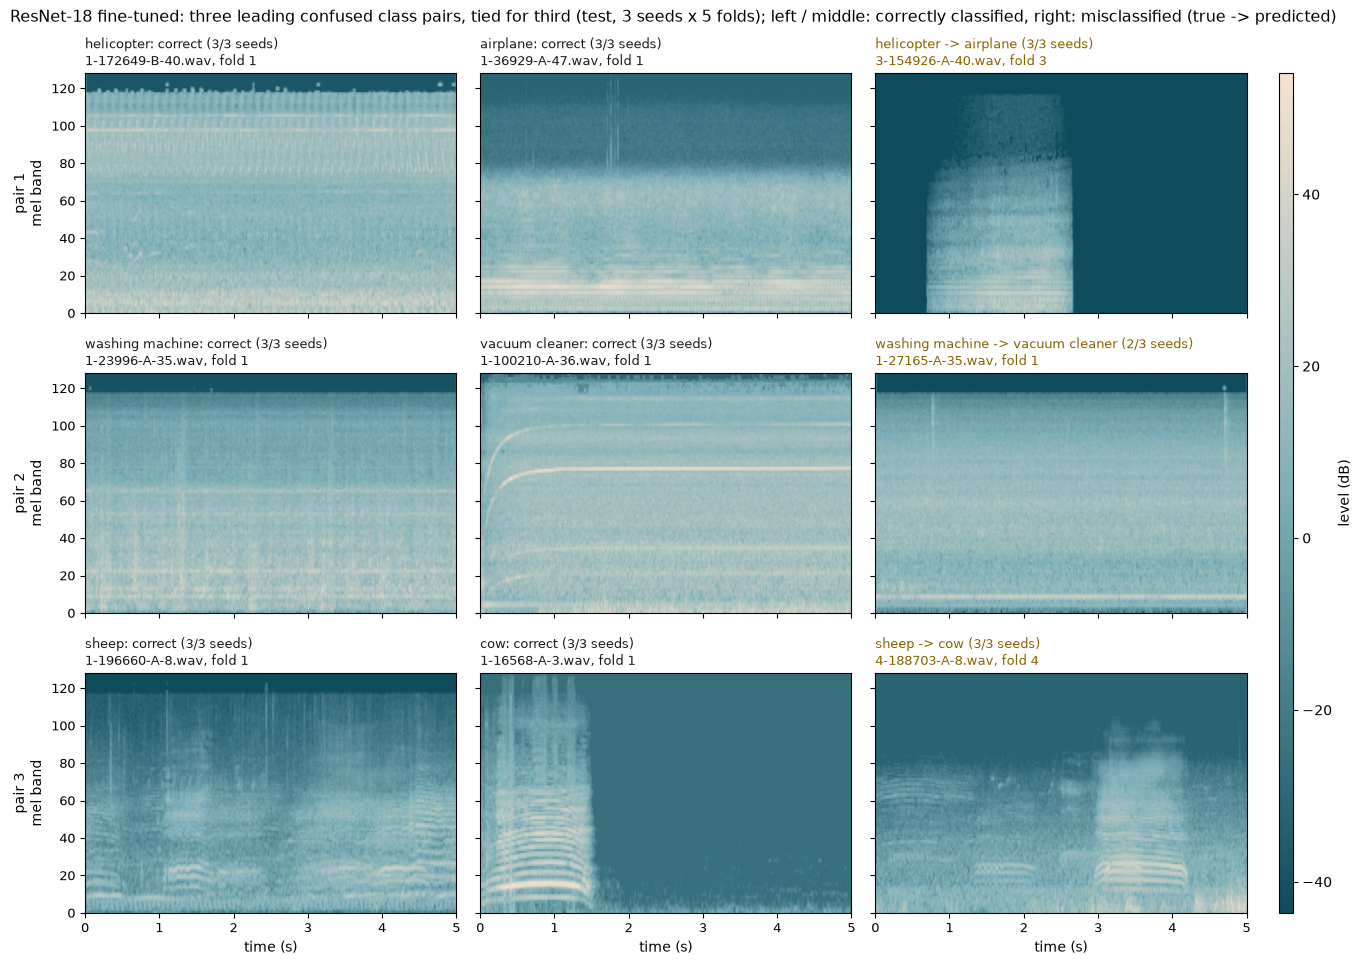

ResNet-18 fine-tuned, three leading confused pairs: helicopter <-> airplane (24 errors; 19 as helicopter -> airplane); washing machine <-> vacuum cleaner (19 errors; 12 as washing machine -> vacuum cleaner); sheep <-> cow (16 errors; 14 as sheep -> cow); share of its 918 test errors (summed over 3 seeds): 6%; tied for third: washing machine <-> engine (16 errors)


In [37]:
# The three leading confused class pairs of the best method (ties for third are printed): per pair, two correctly classified clips (one per class) and one misclassified clip.
if FINAL_RUNS:
    # test runs of the best method (one per seed)
    best_runs = TABLE_RUNS[BEST]
    n_seeds = len(best_runs)
    # how many seeds give each (clip, true class, predicted class) combination
    votes = (pd.concat([p for r in best_runs for p in r["test_preds"].values()], ignore_index=True)
             .groupby(["filename", "y_true", "y_pred"]).size().rename("n").reset_index())
    # confusions in either direction, summed per class pair
    off_cm = CM.copy(); np.fill_diagonal(off_cm, 0)
    pair_n = off_cm + off_cm.T
    # the three pairs with the most confusions (upper triangle, so each pair once)
    iu = np.triu_indices(eval_io.N_CLASSES, 1)
    pair_order = np.argsort(-pair_n[iu], kind="stable")
    top = pair_order[:3]
    # pairs with as many errors as the third one (a tie for third place)
    PAIR_TIES = [(int(iu[0][t]), int(iu[1][t])) for t in pair_order[3:] if pair_n[iu][t] == pair_n[iu][top[-1]]]
    PAIRS = [(int(iu[0][t]), int(iu[1][t])) for t in top]
    # file name -> official fold
    fold_of = SPLIT.set_index("filename")["fold"]

    # a clip of class c that every seed classifies correctly (first by file name)
    def pick_correct(c):
        v = votes[(votes["y_true"] == c) & (votes["y_pred"] == c) & (votes["n"] == n_seeds)]
        return (sorted(v["filename"])[0], n_seeds) if len(v) else (None, 0)

    # the clip of class a most often predicted as b (ties: file name)
    def pick_wrong(a, b):
        v = votes[(votes["y_true"] == a) & (votes["y_pred"] == b)].sort_values(["n", "filename"], ascending=[False, True])
        return (v["filename"].iloc[0], int(v["n"].iloc[0])) if len(v) else (None, 0)

    # 3 x 3 grid: per pair, a correct clip of each class and one misclassified clip
    fig, axes = plt.subplots(3, 3, figsize=(13.5, 9.8), sharex=True, sharey=True)
    pair_text = []
    pair_ims = []                                 # the log-mel images, given one shared colour scale below
    for i, (a, b) in enumerate(PAIRS):
        a, b = (a, b) if off_cm[a, b] >= off_cm[b, a] else (b, a)       # a -> b is the more frequent direction
        na, nb_ = FIG_NAMES[a], FIG_NAMES[b]
        pair_text.append(f"{na} <-> {nb_} ({pair_n[a, b]} errors; {off_cm[a, b]} as {na} -> {nb_})")
        # panels: a correct, b correct, a predicted as b
        panels = [(*pick_correct(a), f"{na}: correct"), (*pick_correct(b), f"{nb_}: correct"),
                  (*pick_wrong(a, b), f"{na} -> {nb_}")]
        for j, (fn, k, title) in enumerate(panels):
            ax = axes[i, j]
            # no matching clip: leave a note in the panel
            if fn is None:
                ax.text(0.5, 0.5, "no such clip", ha="center", va="center", transform=ax.transAxes, fontsize=10)
                continue
            # the log-mel input of the chosen clip (its row of the log-mel cache, saved in support/frozen/)
            mel = np.asarray(PAIR_MELS[fn], dtype=np.float32)
            # draw it and title it with the seed count, file and fold
            pair_ims.append(ax.imshow(mel, origin="lower", aspect="auto", cmap=SLIDE_CMAP, extent=[0, 5, 0, 128]))
            ax.set_title(f"{title} ({k}/{n_seeds} seeds)\n{fn}, fold {int(fold_of[fn])}", fontsize=9.5, loc="left",
                         color="#8A6200" if j == 2 else "#1A1A1A")   # darker gold: readable on white
            ax.tick_params(labelsize=9)
        axes[i, 0].set_ylabel(f"pair {i + 1}\nmel band", fontsize=10)
    # shared x labels and figure title
    for ax in axes[-1]:
        ax.set_xlabel("time (s)", fontsize=10)
    fig.suptitle(f"{BEST}: three leading confused class pairs" + (", tied for third" if PAIR_TIES else "")
                 + f" (test, {n_seeds} seeds x 5 folds); left / middle: correctly classified, right: misclassified (true -> predicted)",
                 x=0.01, ha="left", fontsize=11.5)
    # one colour scale for all panels, so levels can be compared across clips
    pair_lo = min(float(np.min(im.get_array())) for im in pair_ims)
    pair_hi = max(float(np.max(im.get_array())) for im in pair_ims)
    for im in pair_ims:
        im.set_clim(pair_lo, pair_hi)
    plt.tight_layout(rect=(0, 0, 0.94, 1))
    pair_top, pair_bottom = axes[0, -1].get_position(), axes[-1, -1].get_position()
    fig.colorbar(pair_ims[0], cax=fig.add_axes([0.95, pair_bottom.y0, 0.01, pair_top.y1 - pair_bottom.y0]), label="level (dB)")
    plt.show()
    # share of all test errors that fall in these three pairs
    total_err = int(off_cm.sum())
    print(f"{BEST}, three leading confused pairs: " + "; ".join(pair_text)
          + f"; share of its {total_err} test errors (summed over {n_seeds} seeds): "
          f"{100 * sum(pair_n[a, b] for a, b in PAIRS) / max(total_err, 1):.0f}%"
          + ("; tied for third: " + "; ".join(f"{FIG_NAMES[a]} <-> {FIG_NAMES[b]} ({pair_n[a, b]} errors)" for a, b in PAIR_TIES)
             if PAIR_TIES else ""))


**Most-confused pairs.** The figure takes the best method's three leading confused class pairs (third place is tied), with errors in both directions summed over seeds and test folds. Each row shows three log-mel inputs. The first two are clips of each class that every seed classifies correctly. The third is a clip of the more frequent error direction that the most seeds misclassify. Panel titles give the file, its fold and how many seeds agree.

The printed line names the pairs: helicopter and airplane, washing machine and vacuum cleaner, and sheep and cow. Sheep and cow tie for third place with washing machine and engine (16 errors each); the figure shows the tied pair that comes first in class-number order. All panels share one colour scale. Together they are a small share of the method's test errors, so its errors are spread over many class pairs.

### 5.2 Validation results of all configurations
Validation accuracy of every configuration we trained, including variants not selected for the results table.
- These are validation numbers; no test fold is involved.
- As in Section 5.1, seeds are averaged within each fold, then mean ± SD over the five folds.

In [38]:
# Validation accuracy of every configuration (training and validation): seeds averaged per fold, then mean and SD over folds.
# the SVM configurations have one seed; all others have three
DEV_RUNS = {   # section -> {configuration (results-table name): (run name without the _s<seed> suffix, seeds)}
    "4.1 MFCC statistics": {"MFCC + SVM": ("line1/2026-10-17_mfcc-svm", (0,)),
                            "MFCC + random forest": ("line1/2026-10-20_mfcc-rf", (0, 1, 2)),
                            "MFCC + SVM, 0-11 kHz input (band-limit control)": ("line1/2026-10-30_mfcc-svm-fmax11k", (0,))},
    "4.2 CNN from scratch": {"CNN (from scratch)": ("line2/2026-10-16_cnn-baseline", (0, 1, 2)),
                             "CNN 2x width": ("line2/2026-10-31_cnn-wider", (0, 1, 2))},
    "4.3 ResNet-18": {"ResNet-18 linear probe": ("line3/2026-10-17_r18-lp", (0, 1, 2)),
                      "ResNet-18 fine-tuned": ("line3/2026-10-20_r18-ft", (0, 1, 2)),
                      "ResNet-18 fine-tuned, 25% of the training data": ("line3/2026-10-28_r18-ft-frac25", (0, 1, 2)),
                      "ResNet-18 fine-tuned, 50% of the training data": ("line3/2026-10-28_r18-ft-frac50", (0, 1, 2)),
                      "ResNet-18 random init.": ("line3/2026-10-28_r18-scratch", (0, 1, 2))},
    "4.4 Temporal models": {"CRNN": ("line4/2026-10-10_crnn-baseline", (0, 1, 2)),
                            "BiLSTM": ("line4/2026-10-11_lstm-baseline", (0, 1, 2))},
    "4.5 Augmentation series": {"CNN anchor (no augmentation)": ("line5/2026-10-18_anchor-noaug", (0, 1, 2)),
                                "CNN + SpecAugment": ("line5/2026-10-24_specaug", (0, 1, 2)),
                                "CNN + SpecAugment + mixup": ("line5/2026-10-30_specaug-mixup", (0, 1, 2))},
}


def dev_row(method, configuration, base, seeds):
    """One row: seeds averaged within each fold, then mean / SD over folds (best validation accuracy of each fold, %)."""
    # load every seed that exists; skip the configuration if none does
    runs = [r for r in (eval_io.load_run_or_none(RESULTS / f"{base}_s{s}") for s in seeds) if r is not None]
    if not runs:
        return None
    # stack the per-fold dev metrics of all seeds
    dev = pd.concat([r["dev"] for r in runs], ignore_index=True)
    # average the seeds within each fold
    per_fold = dev.groupby("fold")["best_val_acc"].mean() * 100
    # mean and SD over the folds; parameter count from the first row
    return {"section": method, "configuration": configuration, "seeds": len(runs), "folds": len(per_fold),
            "val_acc_mean": round(per_fold.mean(), 1), "sd_over_folds": round(per_fold.std(), 1),
            "params_M": round(float(dev["n_params"].iloc[0]) / 1e6, 2)}


# one row per configuration that has at least one run
DEV_TABLE = pd.DataFrame([row for method, configs in DEV_RUNS.items() for configuration, (base, seeds) in configs.items()
                          if (row := dev_row(method, configuration, base, seeds)) is not None])
# show the table grouped by section
with pd.option_context("display.width", 250):
    display(DEV_TABLE.set_index(["section", "configuration"]).rename(columns={
        "val_acc_mean": "val. accuracy (%)", "sd_over_folds": "SD over folds", "params_M": "params (M)"}).assign(**{"params (M)": lambda t: t["params (M)"].map(lambda v: "n/a" if v == 0 else f"{v:.2f}")}))

seeds  folds  val. accuracy (%)  SD over folds params (M)
section                 configuration                                                                                             
4.1 MFCC statistics     MFCC + SVM                                           1      5               49.2            3.1        n/a
                        MFCC + random forest                                 3      5               48.7            1.9        n/a
                        MFCC + SVM, 0-11 kHz input (band-limit control)      1      5               45.8            3.0        n/a
4.2 CNN from scratch    CNN (from scratch)                                   3      5               67.9            2.3       0.40
                        CNN 2x width                                         3      5               70.1            4.0       1.58
4.3 ResNet-18           ResNet-18 linear probe                               3      5               69.0            1.2      11.20
                        ResNet-18 fine-tuned                                 3      5               87.6            2.2      11.20
                        ResNet-18 fine-tuned, 25% of the training data       3      5               65.2            2.8      11.20
                        ResNet-18 fine-tuned, 50% of the training data       3      5               78.7            1.5      11.20
                        ResNet-18 random init.                               3      5               74.3            2.3      11.20
4.4 Temporal models     CRNN                                                 3      5               78.9            2.2       0.75
                        BiLSTM                                               3      5               42.6            1.8       0.67
4.5 Augmentation series CNN anchor (no augmentation)                         3      5               67.9            2.3       0.40
                        CNN + SpecAugment                                    3      5               65.1            3.0       0.40
                        CNN + SpecAugment + mixup                            3      5               61.6            3.4       0.40

### 5.3 Figures
Each figure is followed by a short note on its data and what it shows. In order:
1. learning curves;
2. augmentation example;
3. accuracy against cost;
4. paired comparisons;
5. per-class recall;
6. CRNN against CNN;
7. amount of training data;
8. noise robustness;
9. band-limit control.

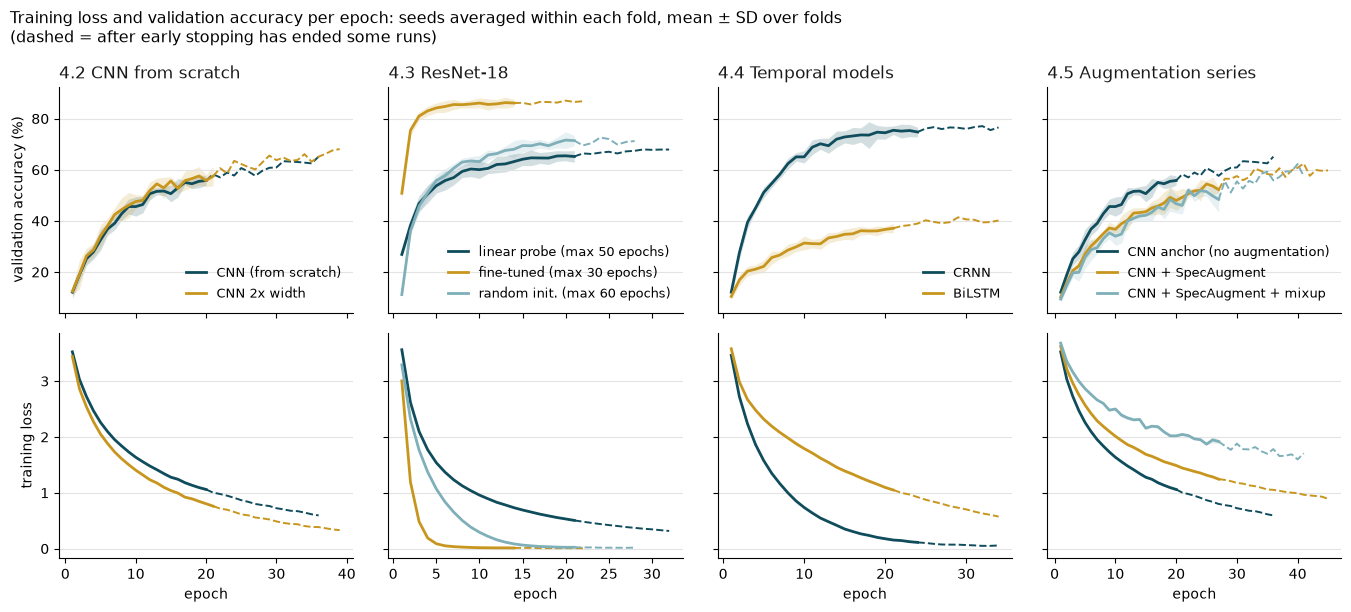

In [39]:
# Training loss and validation accuracy per epoch of selected neural configurations (dashed tail: early stopping has ended some runs).
# configurations grouped by panel (one column of the figure each)
CURVE_RUNS = {   # panel -> {configuration: run name without the _s<seed> suffix}
    "4.2 CNN from scratch": {"CNN (from scratch)": "line2/2026-10-16_cnn-baseline", "CNN 2x width": "line2/2026-10-31_cnn-wider"},
    "4.3 ResNet-18": {"linear probe (max 50 epochs)": "line3/2026-10-17_r18-lp", "fine-tuned (max 30 epochs)": "line3/2026-10-20_r18-ft",
                      "random init. (max 60 epochs)": "line3/2026-10-28_r18-scratch"},
    "4.4 Temporal models": {"CRNN": "line4/2026-10-10_crnn-baseline", "BiLSTM": "line4/2026-10-11_lstm-baseline"},
    "4.5 Augmentation series": {"CNN anchor (no augmentation)": "line5/2026-10-18_anchor-noaug",
                                "CNN + SpecAugment": "line5/2026-10-24_specaug",
                                "CNN + SpecAugment + mixup": "line5/2026-10-30_specaug-mixup"},
}
# seeds averaged for every configuration
CURVE_SEEDS = (0, 1, 2)
CURVE_COLOURS = ["#0F4C5C", "#C8961E", "#7FAFB8"]   # deep teal · gold · mid teal
CURVE_MIN_SHARE = 0.5                               # dashed tail stops once fewer than half of the runs are still training


def curve_summary(base):
    """Per epoch: seeds averaged within each fold, then mean / SD over folds; plus how many seed-fold runs are still active."""
    # load the curves of every available seed
    parts = []
    for s in CURVE_SEEDS:
        run = eval_io.load_run_or_none(RESULTS / f"{base}_s{s}")
        if run is not None and len(run["curves"]):
            parts.append(run["curves"].assign(seed=s))
    if not parts:
        return None
    # all seeds in one table; count the seed-fold runs
    c = pd.concat(parts, ignore_index=True)
    n_total = c.groupby(["seed", "fold"]).ngroups
    # average the seeds within each fold, then mean and SD over the folds, per epoch
    per_fold = c.groupby(["epoch", "fold"]).agg(acc=("val_acc", "mean"), loss=("train_loss", "mean"))
    g = per_fold.groupby("epoch").agg(acc=("acc", "mean"), acc_sd=("acc", "std"), loss=("loss", "mean"), loss_sd=("loss", "std"))
    # number of seed-fold runs still training at each epoch
    g["active"] = c.groupby("epoch").size()
    # drop epochs where fewer than half of the runs remain; flag epochs where all runs remain
    g = g[g["active"] >= CURVE_MIN_SHARE * n_total]
    g["complete"] = g["active"] == n_total
    return g


# top row: validation accuracy; bottom row: training loss; one column per panel
fig, axes = plt.subplots(2, len(CURVE_RUNS), figsize=(3.4 * len(CURVE_RUNS), 6.2), sharex="col", sharey="row")   # one y scale per row
for j, (panel, configs) in enumerate(CURVE_RUNS.items()):
    for k, (label, base) in enumerate(configs.items()):
        g = curve_summary(base)
        if g is None:
            continue
        # one colour per configuration within a panel
        col = CURVE_COLOURS[k % len(CURVE_COLOURS)]
        # last epoch at which every run is still training
        last_full = g.index[g["complete"]].max() if g["complete"].any() else g.index.min()
        for row, (m, sd, scale) in enumerate([("acc", "acc_sd", 100), ("loss", "loss_sd", 1)]):
            ax = axes[row, j]
            # solid line and SD band while all runs train; dashed tail afterwards
            y, e = g[m] * scale, g[sd].fillna(0) * scale
            full, tail = g.index <= last_full, g.index >= last_full
            ax.plot(g.index[full], y[full], color=col, lw=2, label=label if row == 0 else None)
            ax.plot(g.index[tail], y[tail], color=col, lw=1.4, ls="--")
            ax.fill_between(g.index[full], (y - e)[full], (y + e)[full], color=col, alpha=0.18, lw=0)
    # panel titles, legends and axis styling
    axes[0, j].set_title(panel, fontsize=12, loc="left", color="#1A1A1A")
    axes[0, j].legend(frameon=False, fontsize=9.5, loc="lower right", handlelength=1.5)
    axes[1, j].set_xlabel("epoch", fontsize=10)
    for ax in axes[:, j]:
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#E3E3E3", lw=0.8)
        ax.tick_params(labelsize=10)
# shared y labels and figure title
axes[0, 0].set_ylabel("validation accuracy (%)")
axes[1, 0].set_ylabel("training loss")
fig.suptitle("Training loss and validation accuracy per epoch: seeds averaged within each fold, mean ± SD over folds\n"
             "(dashed = after early stopping has ended some runs)", x=0.01, ha="left", fontsize=11.5)
plt.tight_layout()
plt.show()


**Learning curves.** The curves show validation accuracy and training loss per epoch for selected neural configurations (the 25% and 50% data-size runs are in the data-size figure), with seeds averaged within each fold, then mean ± SD over folds. The dashed tail, where early stopping has ended some runs, is for shape only. Each row uses one y scale for all four panels.

Fine-tuning the ImageNet ResNet-18 converges within a few epochs and stays well above linear probing and random initialisation. The CRNN plateaus far above the BiLSTM, the wider CNN follows the baseline, and neither augmentation lifts the curve. Mixup's training loss is measured against mixed labels, so it is not comparable with the anchor's.

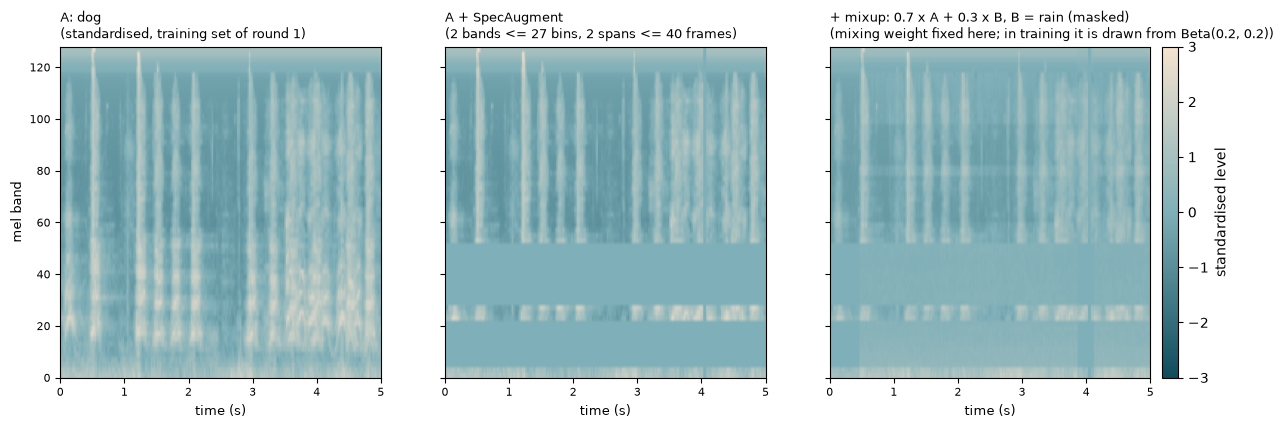

specaug_f27_t40_m2+mixup_alpha0.2: share of clip A's input set to the training mean by the drawn masks 32%; mixing weight between 0.1 and 0.9 in 32% of 10,000 seeded draws from Beta(0.2, 0.2)


In [40]:
# Augmentation examples (Section 4.5): one input before and after SpecAugment, then mixed with a second clip.
# the run whose augmentation settings are shown, and the seed for the masks drawn here
AUG_RUN = "line5/2026-10-30_specaug-mixup_s0"
AUG_SEED = 0
AUG_SHOW_LAM = 0.7                               # for display only; training draws lam from Beta(alpha, alpha)
# load the run; skip the figure if it or the example clips are missing
aug_run = eval_io.load_run_or_none(RESULTS / AUG_RUN)
if aug_run is None or len(SC_CLIPS) < 2:
    print("Augmentation figure skipped: the augmentation-series run or the example clips are not available.")
else:
    # SpecAugment widths and counts and the mixup alpha, read from the run's augment string
    aug_spec = aug_run["config"]["augment"]
    aug_F, aug_T, aug_M = (int(v) for v in re.search(r"specaug_f(\d+)_t(\d+)_m(\d+)", aug_spec).groups())
    aug_alpha = float(re.search(r"mixup_alpha(\d+(?:\.\d+)?)", aug_spec).group(1))
    # use the first two example clips as A and B
    clip_a, clip_b = SC_CLIPS[0], SC_CLIPS[1]
    # per-mel-band mean and SD of the training set of a round that contains both clips (saved with the example clips)
    aug_round, aug_mean, aug_std = int(SAMPLE_CLIPS["aug_round"]), SAMPLE_CLIPS["aug_mean"], SAMPLE_CLIPS["aug_std"]
    # the example log-mels are half-resolution copies (64 mel bands): average the statistics over pairs of mel bands
    aug_mean, aug_std = aug_mean.reshape(64, 2).mean(axis=1), aug_std.reshape(64, 2).mean(axis=1)
    # standardise a clip with those statistics
    norm = lambda c: (c["mel"] - aug_mean[:, None]) / aug_std[:, None]   # noqa: E731
    # seeded generator for the masks, and the masked share of each masked input
    rng = np.random.default_rng(AUG_SEED)
    masked_cells = []

    def aug_mask(x):
        """SpecAugment on one standardised log-mel; widths and starts are drawn on the full 128 x 431 grid."""
        # copy the input; scale maps the full grid to this copy's grid; cells marks masked cells
        x, scale, cells = x.copy(), 128 // x.shape[0], np.zeros((128, 431), bool)
        # aug_M frequency bands, then aug_M time spans
        for size, length, axis in ((aug_F, 128, 0), (aug_T, 431, 1)):
            for _ in range(aug_M):
                # random width up to the maximum, then a random start
                w = int(rng.integers(0, size + 1))
                start = int(rng.random() * (length - w + 1))
                lo, hi = start // scale, -(-(start + w) // scale)     # the same span on this copy's grid
                # zero the span on this copy and mark it on the full grid
                if axis == 0:
                    x[lo:hi, :] = 0
                    cells[start:start + w, :] = True
                else:
                    x[:, lo:hi] = 0
                    cells[:, start:start + w] = True
        # share of the full grid that is masked
        masked_cells.append(cells.mean())
        return x

    # A standardised, A masked, B masked, then the fixed-lam mix of the two masked inputs
    a0 = norm(clip_a)
    a1, b1 = aug_mask(a0), aug_mask(norm(clip_b))
    lam = AUG_SHOW_LAM
    mixed = lam * a1 + (1 - lam) * b1
    # three panels: A, A after SpecAugment, mixup of masked A and B
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3), sharey=True)
    for ax, img, title in zip(axes, (a0, a1, mixed),
                              (f"A: {clip_a['category'].replace('_', ' ')}\n(standardised, training set of round {aug_round})",
                               f"A + SpecAugment\n({aug_M} bands <= {aug_F} bins, {aug_M} spans <= {aug_T} frames)",
                               f"+ mixup: {lam:.1f} x A + {1 - lam:.1f} x B, B = {clip_b['category'].replace('_', ' ')} (masked)\n"
                               f"(mixing weight fixed here; in training it is drawn from Beta({aug_alpha:g}, {aug_alpha:g}))")):
        im = ax.imshow(img, origin="lower", aspect="auto", cmap=SLIDE_CMAP, vmin=-3, vmax=3, extent=[0, 5, 0, 128])
        ax.set_title(title, fontsize=9, loc="left"); ax.set_xlabel("time (s)", fontsize=9); ax.tick_params(labelsize=8)
    axes[0].set_ylabel("mel band", fontsize=9)
    plt.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="standardised level")
    plt.show()
    # how often lam drawn from Beta(alpha, alpha) falls between 0.1 and 0.9
    aug_draws = np.random.default_rng(AUG_SEED + 2).beta(aug_alpha, aug_alpha, 10_000)
    aug_mid = float(np.mean((aug_draws > 0.1) & (aug_draws < 0.9)))
    print(f"{aug_spec}: share of clip A's input set to the training mean by the drawn masks {100 * masked_cells[0]:.0f}%; "
          f"mixing weight between 0.1 and 0.9 in {100 * aug_mid:.0f}% of 10,000 seeded draws from Beta({aug_alpha:g}, {aug_alpha:g})")

**Augmentation example.** The figure shows the augmentation of the Section 4.5 series, applied to the first two example clips of Section 3.1 (dog and rain). The clips are standardised with the training set's per-band means and SDs (averaged over pairs of mel bands for this half-resolution copy), masked with the selected SpecAugment + mixup settings, and mixed with a fixed display weight. In training that weight is drawn from Beta(alpha, alpha). The masks hide a visible part of the input, and with this alpha most mixed inputs stay close to one of the two clips.

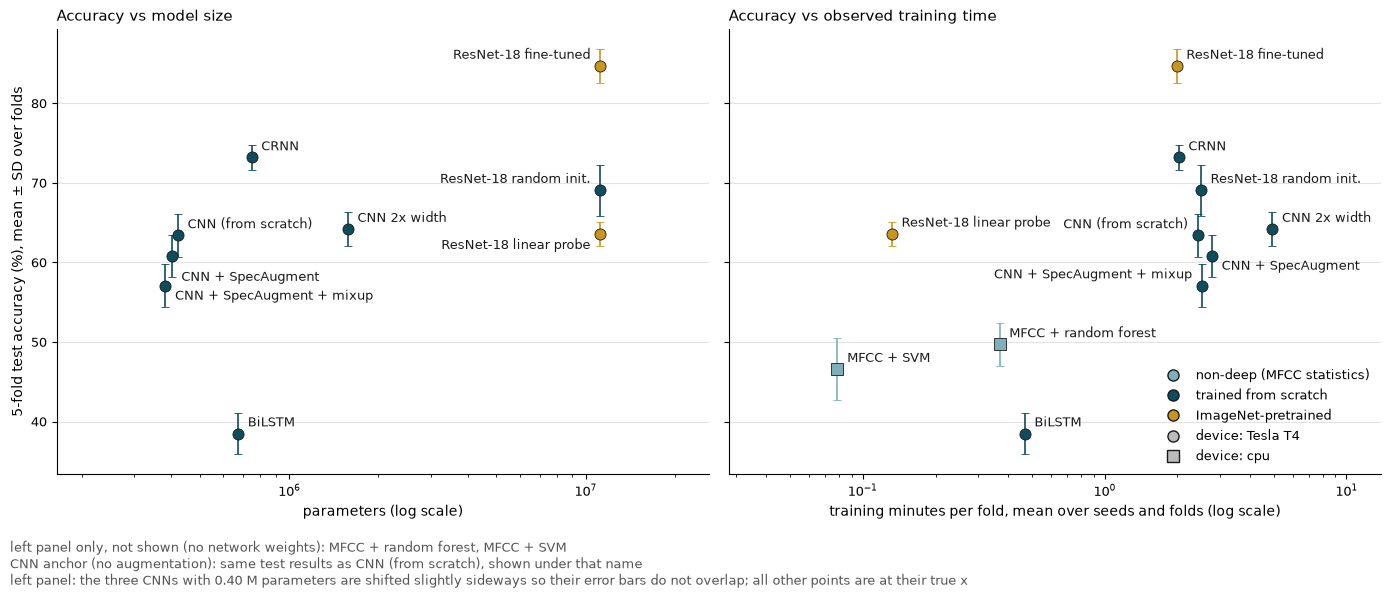

Rank correlation of parameter count and test accuracy over the 9 networks: 0.71

Cost per method (device: the CUDA GPU for the networks; scikit-learn fitted the MFCC classifiers on the CPU, and an 'mps' entry only records that Apple's MPS backend was available, Section 7.1):


,group,seeds,folds per seed,training min per seed,s per epoch,params (M),device (env.json)
method,,,,,,,
MFCC + SVM,non-deep (MFCC statistics),1,5.0,0.4,n/a,n/a,cpu + mps
MFCC + random forest,non-deep (MFCC statistics),3,5.0,1.8,n/a,n/a,cpu
CNN (from scratch),trained from scratch,3,5.0,12.1,3.8,0.40,Tesla T4
CNN 2x width,trained from scratch,3,5.0,24.7,7.9,1.58,Tesla T4
ResNet-18 linear probe,ImageNet-pretrained,3,5.0,0.7,0.2,11.20,Tesla T4
ResNet-18 fine-tuned,ImageNet-pretrained,3,5.0,9.9,5.7,11.20,Tesla T4
ResNet-18 random init.,trained from scratch,3,5.0,12.5,5.4,11.20,Tesla T4
CRNN,trained from scratch,3,5.0,10.1,3.7,0.75,Tesla T4
BiLSTM,trained from scratch,3,5.0,2.3,0.8,0.67,Tesla T4


In [41]:
# Test accuracy against parameter count and observed training time, one point per configuration of the results table,
# then the cost of every configuration (training time, time per epoch, parameters, device).


def cost_table(table_runs):
    """One row per method: seeds, folds, training minutes per seed, seconds per epoch, parameters, device."""
    rows = []
    for name, method_runs in table_runs.items():
        runs = [r for r in method_runs if r is not None]
        if not runs:
            continue
        minutes = [r["dev"]["train_seconds"].sum() / 60 for r in runs]
        epochs = sum(len(r["curves"]) for r in runs)
        devices = {e.get("device", "?") for r in runs for e in (r.get("env") or {}).values()}   # each fold's env.json
        rows.append({"method": name, "group": GROUP_NAMES[runs[0]["config"]["group"]], "seeds": len(runs),
                     "folds_per_seed": round(float(np.mean([len(r["dev"]) for r in runs])), 1),
                     "train_min_per_seed": round(float(np.mean(minutes)), 1),
                     "sec_per_epoch": round(sum(r["dev"]["train_seconds"].sum() for r in runs) / epochs, 1) if epochs else float("nan"),
                     "params_M": round(float(runs[0]["dev"]["n_params"].iloc[0]) / 1e6, 2),
                     "device": " + ".join(sorted(devices)) if devices else "not recorded"})
    return pd.DataFrame(rows)


if FINAL_RUNS:
    # point colour and legend label per method group
    GROUP_STYLE = {"non_deep": (FIG_MID, "non-deep (MFCC statistics)"), "from_scratch": (FIG_TEAL, "trained from scratch"),
                   "external_pretrained": (FIG_GOLD, "ImageNet-pretrained")}
    # one entry per configuration of the results table
    cost = []
    for _, row in RESULTS_TABLE.iterrows():
        runs = TABLE_RUNS[row["method"]]
        # dev metrics of all seeds (parameter count and training time)
        dev = pd.concat([r["dev"] for r in runs], ignore_index=True)
        # devices recorded in the runs' environment files
        devices = sorted({str(e.get("device", "unknown")) for r in runs for e in r["env"].values()}) or ["not recorded"]
        if row["group"] == "non_deep":          # scikit-learn fits on the CPU; "mps" in env.json only records availability
            devices = ["cpu"]
        # accuracy, fold SD, parameters, mean training minutes per fold and device
        cost.append({"method": row["method"], "group": row["group"], "acc": row["mean"], "sd": row["std_over_folds"],
                     "folds": row["folds"], "params": float(dev["n_params"].iloc[0]),
                     "minutes": float(dev["train_seconds"].mean() / 60), "device": " + ".join(devices)})
    COST = pd.DataFrame(cost)
    COST["label"] = COST["method"].map(SAME_AS)   # identical test predictions (Section 5.1): one label
    # groups of configurations that share the same test predictions
    same = [g for g in COST.groupby("label")["method"].apply(list) if len(g) > 1]
    # one marker shape per device
    DEVICE_MARKERS = dict(zip(sorted(COST["device"].unique()), "osD^vP"))


    def place_labels(ax, pts, markers):
        """Place each label at the first offset that stays inside the panel and overlaps no marker, error bar or earlier label."""
        # work in display coordinates; start with a box around every marker and its vertical error bar
        renderer = ax.figure.canvas.get_renderer()
        frame = ax.get_window_extent(renderer)       # labels stay inside the panel
        placed = []
        for mx, my, msd in markers:
            px, py = ax.transData.transform((mx, my))
            placed.append(matplotlib.transforms.Bbox.from_bounds(px - 6, py - 6, 12, 12))         # the marker itself
            lo, hi = ax.transData.transform((mx, my - msd))[1], ax.transData.transform((mx, my + msd))[1]
            placed.append(matplotlib.transforms.Bbox.from_extents(px - 4, lo - 4, px + 4, hi + 4))  # its error bar
        # candidate offsets in points: right or left, above or below, then further out
        options = ((7, 3, "left", "bottom"), (7, -3, "left", "top"), (-7, 3, "right", "bottom"), (-7, -3, "right", "top"),
                   (7, 11, "left", "bottom"), (7, -11, "left", "top"), (-7, 11, "right", "bottom"), (-7, -11, "right", "top"))
        # try each offset; keep the first that fits, or the first offset if none does
        for x, y, text in pts:
            for k, (dx, dy, ha, va) in enumerate(options + options[:1]):
                t = ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=9,
                                color="#1A1A1A")
                # accept the label if it stays inside horizontally and overlaps nothing placed so far
                box = t.get_window_extent(renderer)
                inside = frame.x0 <= box.x0 and box.x1 <= frame.x1
                if k == len(options) or (inside and not any(box.overlaps(b) for b in placed)):
                    placed.append(box)
                    break
                # otherwise remove it and try the next offset
                t.remove()

    def dodge_same_x(d, col, step=0.05):
        """Shift points that share one x value and have overlapping error bars apart by a few per cent on the log axis
        (display only)."""
        d = d.copy()
        for _, g in d.groupby(col):
            bars = sorted(zip(g["acc"] - g["sd"], g["acc"] + g["sd"]))
            if not any(lo2 < hi1 for (lo1, hi1), (lo2, hi2) in zip(bars, bars[1:])):
                continue                          # error bars apart already: keep the true x value
            for k, i in enumerate(g.sort_values("acc").index):
                d.loc[i, col] = d.loc[i, col] * (1 + step) ** (k - (len(g) - 1) / 2)
        return d

    # left: accuracy vs parameter count; right: accuracy vs training minutes (both log scale)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
    for ax, col, xlabel in ((axes[0], "params", "parameters (log scale)"),
                            (axes[1], "minutes", "training minutes per fold, mean over seeds and folds (log scale)")):
        # only positive values can go on the log axis; identical test predictions are drawn once
        d = COST[COST[col] > 0].drop_duplicates("label")
        d = dodge_same_x(d, col) if col == "params" else d
        for _, r in d.iterrows():
            # error bar = SD over folds; marker shape = device on the time panel
            ax.errorbar(r[col], r["acc"], yerr=r["sd"], fmt=DEVICE_MARKERS[r["device"]] if col == "minutes" else "o",
                        color=GROUP_STYLE[r["group"]][0], mec="#1A1A1A", mew=0.6, ms=8, capsize=3, lw=1.2, zorder=3)
        ax.set_xscale("log")
        ax.set_xlabel(xlabel, fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#E3E3E3", lw=0.8)
        ax.tick_params(labelsize=9)
        ax.margins(x=0.25)
    axes[0].set_ylabel("5-fold test accuracy (%), mean ± SD over folds", fontsize=10)
    axes[0].set_title("Accuracy vs model size", fontsize=11, loc="left")
    axes[1].set_title("Accuracy vs observed training time", fontsize=11, loc="left")
    # legend: method groups, then devices
    handles = [matplotlib.lines.Line2D([], [], ls="", marker="o", color=c, mec="#1A1A1A", ms=8, label=lab)
               for g, (c, lab) in GROUP_STYLE.items() if g in set(COST["group"])]
    handles += [matplotlib.lines.Line2D([], [], ls="", marker=mk, color="#BBBBBB", mec="#1A1A1A", ms=8, label=f"device: {dv}")
                for dv, mk in DEVICE_MARKERS.items()]
    axes[1].legend(handles=handles, frameon=False, fontsize=9, loc="lower right")
    # note below the figure: configurations not shown and shared test results
    no_w = COST.loc[COST["params"] == 0, "method"].tolist()
    notes = (["left panel only, not shown (no network weights): " + ", ".join(no_w)] if no_w else []) + \
            [", ".join(g[1:]) + f": same test results as {g[0]}, shown under that name" for g in same] + \
            ["left panel: the three CNNs with 0.40 M parameters are shifted slightly sideways so their error bars do not overlap; all other points are at their true x"]
    if notes:
        fig.text(0.01, -0.01, "\n".join(notes), ha="left", va="top", fontsize=9, color="#555")
    plt.tight_layout()
    # draw once so label sizes can be measured, then place the labels
    fig.canvas.draw()
    for ax, col in ((axes[0], "params"), (axes[1], "minutes")):
        d = COST[COST[col] > 0].drop_duplicates("label")
        d = dodge_same_x(d, col) if col == "params" else d
        lab = d.sort_values("acc", ascending=False)
        place_labels(ax, list(zip(lab[col], lab["acc"], lab["label"])), list(zip(d[col], d["acc"], d["sd"])))
    plt.show()
    # rank correlation of size and accuracy over the networks (identical test predictions counted once)
    nets = COST[COST["params"] > 0].drop_duplicates("label")
    rank_r = float(np.corrcoef(nets["params"].rank(), nets["acc"].rank())[0, 1])
    print(f"Rank correlation of parameter count and test accuracy over the {len(nets)} networks: {rank_r:.2f}")
    # cost per configuration (Section 6.1 refers to this table)
    COST_TABLE = cost_table(TABLE_RUNS)
    print("\nCost per method (device: the CUDA GPU for the networks; scikit-learn fitted the MFCC classifiers on the CPU, "
          "and an 'mps' entry only records that Apple's MPS backend was available, Section 7.1):")
    with pd.option_context("display.width", 250, "display.max_columns", None):
        display(COST_TABLE.set_index("method").rename(columns={
            "folds_per_seed": "folds per seed", "train_min_per_seed": "training min per seed", "sec_per_epoch": "s per epoch",
            "params_M": "params (M)", "device": "device (env.json)"}).fillna({"s per epoch": "n/a"})
                .assign(**{"params (M)": lambda t: t["params (M)"].map(lambda v: "n/a" if v == 0 else f"{v:.2f}")}))   # the MFCC classifiers have no network weights

**Accuracy against cost.** Each point is one configuration, with test accuracy as mean ± SD over folds (seeds averaged per fold). The left panel plots it against parameter count, including any frozen backbone; the three CNNs with 0.40 M parameters are shifted slightly sideways for readability, and every other point is at its true parameter count. The MFCC classifiers have no network weights, so they appear only on the right. The right panel plots training minutes per fold; the marker shows the device, a Tesla T4 GPU for the networks and the CPU for the MFCC classifiers (scikit-learn), since times from different hardware are not directly comparable. The `mps` entry of one MFCC fold in Section 7.1 only records that Apple's MPS backend was available. The CNN anchor has the same test predictions as the CNN (from scratch), so it is drawn once. For the MFCC classifiers the time covers fitting only, not the cached feature extraction. The table after the figure gives the cost of every final configuration: training minutes per seed, seconds per epoch, parameters and device.

Size alone does not explain accuracy: the three ResNet-18 configurations have the same parameter count but very different accuracy.

Not in the results table (no test folds; compared on the validation set in the data-size figure): ResNet-18 fine-tuned -> ResNet-18 fine-tuned, 50% of the training data; ResNet-18 fine-tuned, 50% of the training data -> ResNet-18 fine-tuned, 25% of the training data


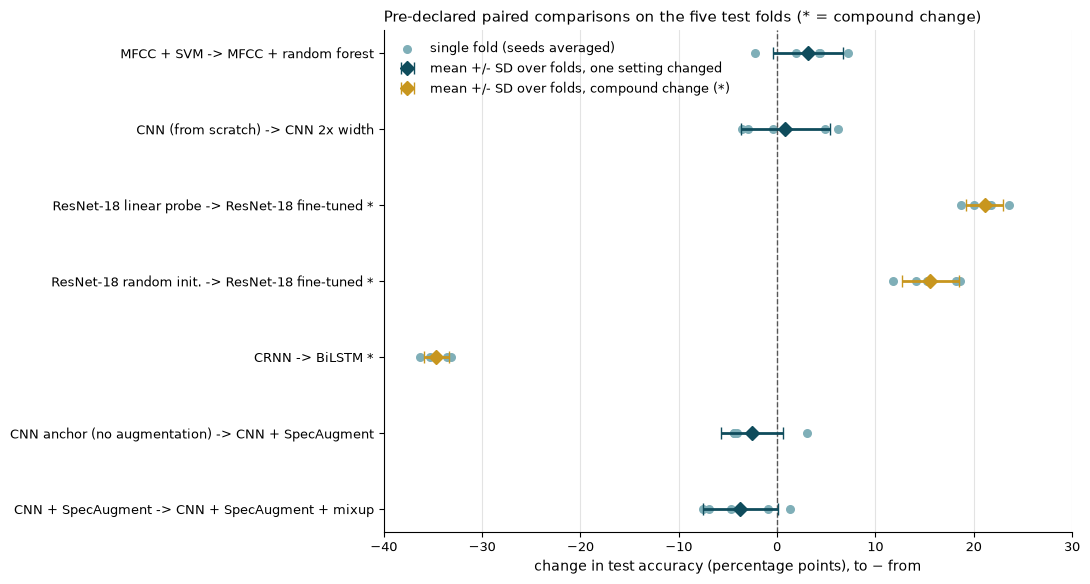

                                       comparison  mean  sd  up  down
               MFCC + SVM -> MFCC + random forest   3.1 3.5   4     1
               CNN (from scratch) -> CNN 2x width   0.9 4.5   2     3
 ResNet-18 linear probe -> ResNet-18 fine-tuned *  21.1 1.9   5     0
 ResNet-18 random init. -> ResNet-18 fine-tuned *  15.6 2.9   5     0
                                 CRNN -> BiLSTM * -34.6 1.3   0     5
CNN anchor (no augmentation) -> CNN + SpecAugment  -2.5 3.2   1     4
   CNN + SpecAugment -> CNN + SpecAugment + mixup  -3.7 3.8   1     4
No clear difference (gap smaller than both seed spreads of the results table): CNN (from scratch) -> CNN 2x width (gap 0.9, seed spreads 2.8 / 5.9); not decidable (single seed, no seed spread): MFCC + SVM -> MFCC + random forest


In [42]:
# Pre-declared paired comparisons on the five test folds (to minus from, seeds averaged per fold; * = compound change).
# (from, to, compound) for each comparison declared before testing
PAIRED = [("MFCC + SVM", "MFCC + random forest", False),
          ("CNN (from scratch)", "CNN 2x width", False),
          ("ResNet-18 linear probe", "ResNet-18 fine-tuned", True),
          ("ResNet-18 random init.", "ResNet-18 fine-tuned", True),
          ("ResNet-18 fine-tuned", "ResNet-18 fine-tuned, 50% of the training data", False),
          ("ResNet-18 fine-tuned, 50% of the training data", "ResNet-18 fine-tuned, 25% of the training data", False),
          ("CRNN", "BiLSTM", True),
          ("CNN anchor (no augmentation)", "CNN + SpecAugment", False),
          ("CNN + SpecAugment", "CNN + SpecAugment + mixup", False)]


def seed_spread_raw(runs):
    """Range of the per-seed five-fold means (%), unrounded (same statistic as seed_spread in final_table); NaN for one seed."""
    seed_means = [100 * float(eval_io.test_acc(r).mean()) for r in runs]
    return max(seed_means) - min(seed_means) if len(runs) > 1 else float("nan")


def round_half_away(x, ndigits=1):
    """Round once for display, exact ties away from zero. Fold means are exact fractions, so float noise is removed
    first (9 decimals) and a value such as 0.85 rounds to 0.9 whatever its binary representation."""
    import decimal
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return float("nan")
    q = decimal.Decimal(f"{float(x):.9f}").quantize(decimal.Decimal(1).scaleb(-ndigits), rounding=decimal.ROUND_HALF_UP)
    return float(q)


def fold_means(runs):
    """Test accuracy (%) per fold, seeds averaged within each fold (unrounded)."""
    # one column per seed of per-fold test accuracy, averaged across the columns
    return (pd.DataFrame({i: eval_io.test_acc(r) for i, r in enumerate(runs)}) * 100).mean(axis=1)


if FINAL_RUNS:
    # comparisons whose configurations have no test results are listed and skipped
    skipped = [(a, b) for a, b, _ in PAIRED if a not in TABLE_RUNS or b not in TABLE_RUNS]
    if skipped:
        print("Not in the results table (no test folds; compared on the validation set in the data-size figure):",
              "; ".join(f"{a} -> {b}" for a, b in skipped))
    # per-fold difference (to minus from), its mean and SD, and how many folds go up or down
    rows = []
    for a, b, compound in PAIRED:
        if a in TABLE_RUNS and b in TABLE_RUNS:
            d = fold_means(TABLE_RUNS[b]) - fold_means(TABLE_RUNS[a])
            rows.append({"comparison": f"{a} -> {b}" + (" *" if compound else ""), "diff": d,
                         "mean": d.mean(), "sd": d.std(ddof=1), "up": int((d > 0).sum()), "down": int((d < 0).sum())})
    PAIRED_DIFF = pd.DataFrame(rows)
    # one row per comparison: single folds as dots, mean +/- SD as a diamond
    fig, ax = plt.subplots(figsize=(11, 0.62 * len(rows) + 1.6))
    for y, r in enumerate(rows):
        ax.scatter(r["diff"].values, [y] * len(r["diff"]), color=FIG_MID, s=30, zorder=2,
                   label="single fold (seeds averaged)" if y == 0 else None)
        # gold = compound change (more than one setting differs), teal = one setting, as in the report figure
        compound = r["comparison"].endswith(" *")
        first_of_kind = all(q["comparison"].endswith(" *") != compound for q in rows[:y])
        ax.errorbar(r["mean"], y, xerr=r["sd"], fmt="D", color=FIG_GOLD if compound else FIG_TEAL, ms=7, capsize=4,
                    lw=2, zorder=3, label=("mean +/- SD over folds, compound change (*)" if compound else
                                          "mean +/- SD over folds, one setting changed") if first_of_kind else None)
    # zero line, comparison labels (first comparison at the top) and styling
    ax.axvline(0, color="#555", lw=1, ls="--")
    ax.set_yticks(range(len(rows)), [r["comparison"] for r in rows], fontsize=9.5)
    ax.invert_yaxis()
    ax.set_xlabel("change in test accuracy (percentage points), to − from", fontsize=10)
    ax.set_title("Pre-declared paired comparisons on the five test folds (* = compound change)", fontsize=11, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#E3E3E3", lw=0.8)
    ax.tick_params(axis="x", labelsize=9)
    # x axis on whole tens, so the most negative comparison has a labelled tick beyond it
    x_lo = 10 * math.floor(min(float(r["diff"].min()) for r in rows) / 10)
    x_hi = 10 * math.ceil(max(float(r["diff"].max()) for r in rows) / 10)
    ax.set_xlim(x_lo, x_hi); ax.set_xticks(range(x_lo, x_hi + 1, 10))
    ax.legend(frameon=False, fontsize=9, loc="upper left")   # an empty corner: no comparison has data there
    plt.tight_layout()
    plt.show()
    # print the table of means, SDs and fold counts
    print(PAIRED_DIFF[["comparison", "mean", "sd", "up", "down"]].assign(
        mean=PAIRED_DIFF["mean"].map(round_half_away), sd=PAIRED_DIFF["sd"].map(round_half_away)).to_string(index=False))
    # no clear difference: gap smaller than both seed spreads, both from unrounded means
    no_diff, no_spread = [], []
    # for each comparison: compare the gap in results-table means with both seed spreads
    for a, b, compound in PAIRED:
        if a in TABLE_RUNS and b in TABLE_RUNS:
            name = f"{a} -> {b}" + (" *" if compound else "")
            gap = abs(fold_means(TABLE_RUNS[b]).mean() - fold_means(TABLE_RUNS[a]).mean())
            sa, sb = seed_spread_raw(TABLE_RUNS[a]), seed_spread_raw(TABLE_RUNS[b])
            # a single-seed configuration has no seed spread
            if pd.isna(sa) or pd.isna(sb):
                no_spread.append(name)
            elif gap < sa and gap < sb:
                rd = round_half_away
                no_diff.append(f"{name} (gap {rd(gap):.1f}, seed spreads {rd(sa):.1f} / {rd(sb):.1f})")
    print("No clear difference (gap smaller than both seed spreads of the results table): "
          + ("; ".join(no_diff) if no_diff else "none")
          + ("; not decidable (single seed, no seed spread): " + "; ".join(no_spread) if no_spread else ""))

**Paired comparisons.** For each pair declared before testing, the dots are the five fold-paired differences in test accuracy, with seeds averaged per fold. The diamond is their mean ± SD over folds; this is descriptive, not a significance test. The differences, gaps and seed spreads are computed in this notebook from unrounded means and rounded once for display. A * and a gold diamond mark a compound comparison, where more than one setting changes; a teal diamond marks a one-setting comparison, as in the report.

The three compound comparisons move all five folds the same way. The wider CNN is not clearly different from the baseline (rule in Section 5.1), and the two data-size pairs have no test folds (data-size figure below).

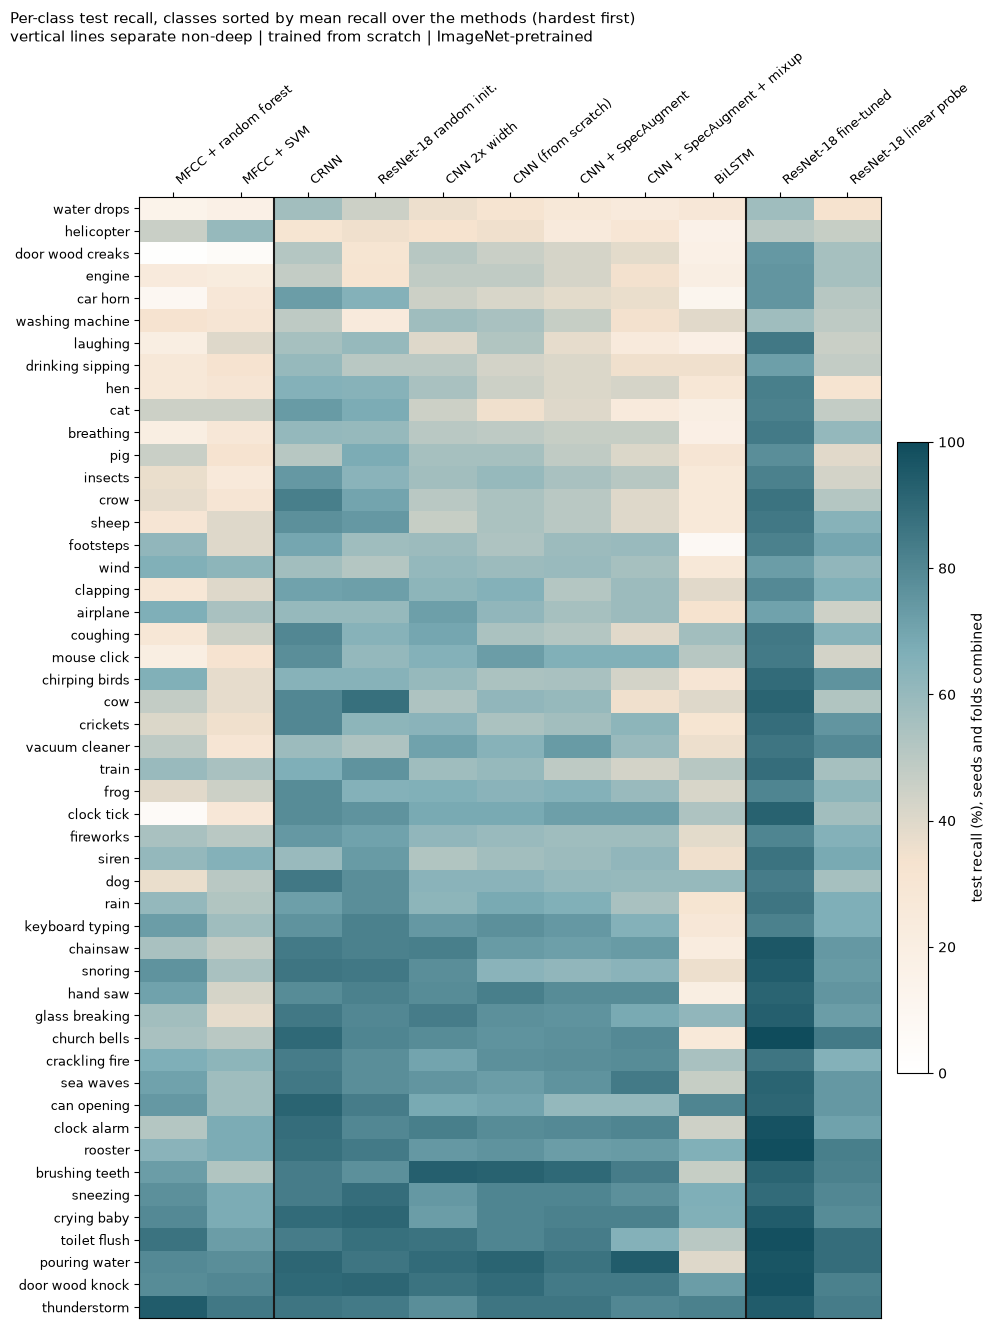

Mean recall over the methods (%): hardest water drops 33.6, helicopter 36.9, door wood creaks 37.6; easiest thunderstorm 85.2, door wood knock 85.0, pouring water 83.6; largest range across methods: clock tick, from 5.8 (MFCC + random forest) to 92.5 (ResNet-18 fine-tuned)


In [43]:
# Per-class test recall heatmap, classes sorted by mean recall over the methods (hardest first).
if FINAL_RUNS:
    H = PER_CLASS_N.loc[HEAT_ORDER, HEAT_METHODS]
    fig, ax = plt.subplots(figsize=(10, 13.5))
    im = ax.imshow(H.values, cmap=FIG_SEQ, vmin=0, vmax=100, aspect="auto")
    ax.set_yticks(range(len(H)), H.index, fontsize=9)
    ax.set_xticks(range(H.shape[1]), H.columns, rotation=40, ha="right", fontsize=9.5)
    ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
    plt.setp(ax.get_xticklabels(), ha="left", rotation=40)
    groups = RESULTS_TABLE.set_index("method").loc[HEAT_METHODS, "group"].tolist()
    for j in range(1, len(groups)):
        if groups[j] != groups[j - 1]:
            ax.axvline(j - 0.5, color="#1A1A1A", lw=1.5)
    plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="test recall (%), seeds and folds combined")
    fig.suptitle("Per-class test recall, classes sorted by mean recall over the methods (hardest first)\n"
                 "vertical lines separate non-deep | trained from scratch | ImageNet-pretrained", x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()
    mean_r = H.mean(axis=1)
    spread = H.max(axis=1) - H.min(axis=1)
    print("Mean recall over the methods (%): hardest " + ", ".join(f"{c} {mean_r[c]:.1f}" for c in HEAT_ORDER[:3])
          + "; easiest " + ", ".join(f"{c} {mean_r[c]:.1f}" for c in HEAT_ORDER[::-1][:3])
          + f"; largest range across methods: {spread.idxmax()}, from {H.loc[spread.idxmax()].min():.1f} "
          f"({H.loc[spread.idxmax()].idxmin()}) to {H.loc[spread.idxmax()].max():.1f} ({H.loc[spread.idxmax()].idxmax()})")

**Per-class recall.** The heatmap shows test recall of each class for each method, from all seeds and folds combined. Classes are sorted by mean recall over the methods, hardest at the top. The anchor is identical to the from-scratch CNN, so it is shown once.

The classes with the lowest mean recall tend to be hard for most methods, but not for all: door wood creaks, third lowest by mean recall, reaches 74.2% recall with the fine-tuned ResNet-18. A few classes, such as clock tick, range from almost never to almost always right depending on the method.

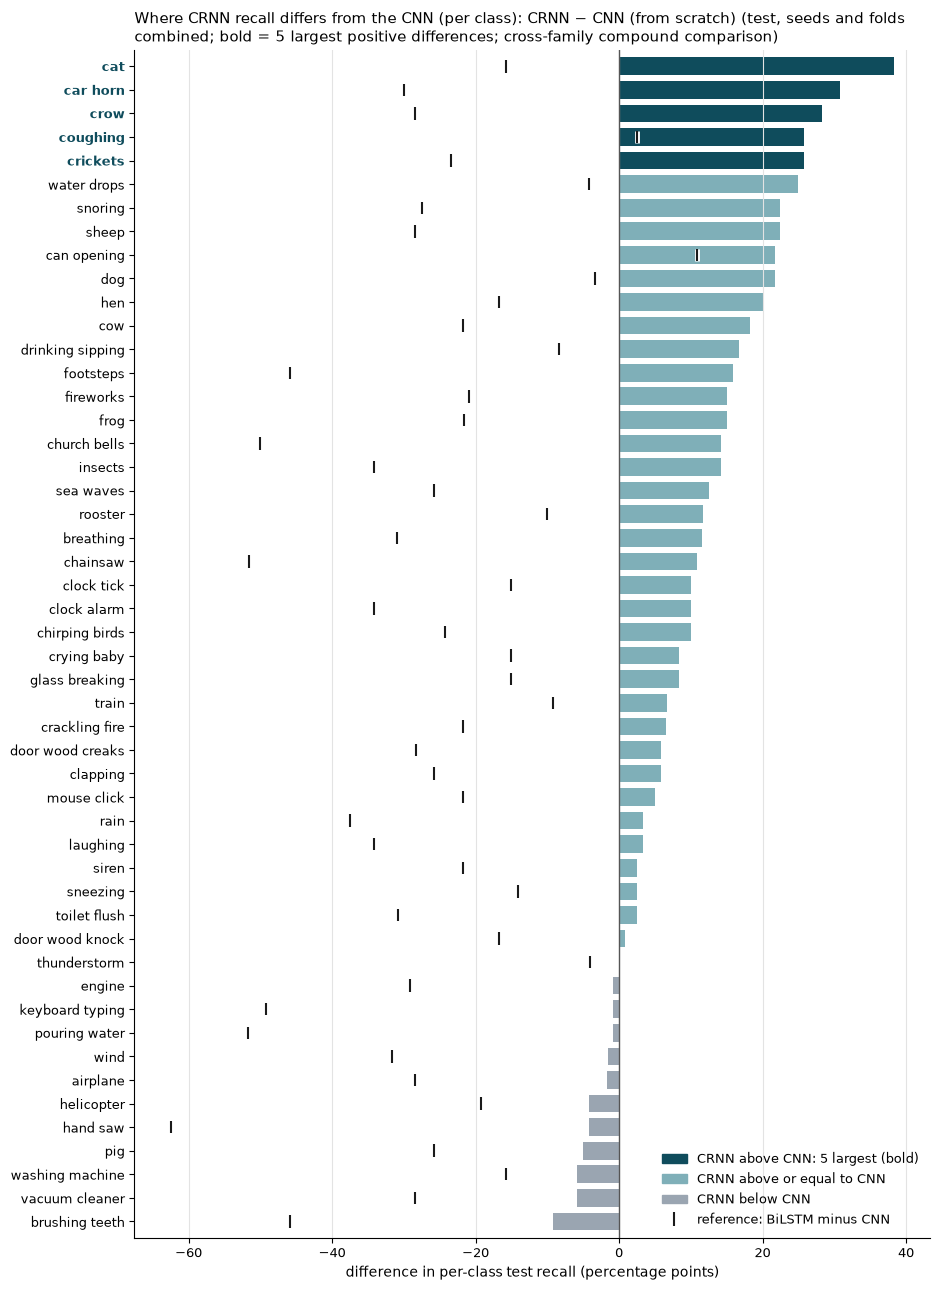

CRNN minus CNN (from scratch), per-class test recall: higher on 38 of 50 classes, lower on 11, mean +9.8 points; largest: cat +38.3, car horn +30.8, crow +28.3. BiLSTM minus CNN (from scratch): lower on 48 of 50 classes, mean -24.8 points.


In [44]:
# Per-class test recall, CRNN minus CNN (from scratch): a compound comparison, not attributed to temporal modelling.
# reference model, compared model, second temporal model, and how many classes to highlight
CNN_REF, TIME_MODEL, TIME_CONTROL, N_HIGHLIGHT = "CNN (from scratch)", "CRNN", "BiLSTM", 5
if FINAL_RUNS and {CNN_REF, TIME_MODEL, TIME_CONTROL} <= set(PER_CLASS_N.columns):
    # per-class recall difference CRNN minus CNN, sorted from lowest to highest
    gain = (PER_CLASS_N[TIME_MODEL] - PER_CLASS_N[CNN_REF]).sort_values(kind="stable")
    # the same difference for BiLSTM, in the same class order
    ctrl = (PER_CLASS_N[TIME_CONTROL] - PER_CLASS_N[CNN_REF])[gain.index]
    # the classes with the largest positive differences
    top_gain = set(gain.index[::-1][:N_HIGHLIGHT])
    # bars: CRNN minus CNN per class; ticks: BiLSTM minus CNN
    fig, ax = plt.subplots(figsize=(9.5, 13))
    y = np.arange(len(gain))
    ax.barh(y, gain.values, color=[FIG_TEAL if c in top_gain else (FIG_MID if v >= 0 else "#9AA5B1")
                                   for c, v in gain.items()], height=0.75, label=f"{TIME_MODEL} − {CNN_REF}")
    # dark marks with a white outline, visible on white and on the dark bars
    from matplotlib import patheffects
    ax.scatter(ctrl.values, y, marker="|", s=80, color="#1A1A1A", linewidths=1.5, zorder=3,
               path_effects=[patheffects.withStroke(linewidth=3.5, foreground="white")])
    # zero line, class labels and styling
    ax.axvline(0, color="#555", lw=1)
    ax.set_yticks(y, gain.index, fontsize=9)
    for t in ax.get_yticklabels():                 # the highlighted classes
        if t.get_text() in top_gain:
            t.set_fontweight("bold"); t.set_color(FIG_TEAL)
    ax.set_xlabel("difference in per-class test recall (percentage points)", fontsize=10)
    ax.set_title(f"Where {TIME_MODEL} recall differs from the CNN (per class): {TIME_MODEL} − {CNN_REF} (test, seeds and folds\n"
                 f"combined; bold = {N_HIGHLIGHT} largest positive differences; cross-family compound comparison)", fontsize=11, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#E3E3E3", lw=0.8)
    ax.tick_params(axis="x", labelsize=9)
    ax.set_ylim(-0.7, len(gain) - 0.3)
    # explicit legend: the three bar colours and the reference mark
    ax.legend(handles=[matplotlib.patches.Patch(color=FIG_TEAL, label=f"{TIME_MODEL} above CNN: {N_HIGHLIGHT} largest (bold)"),
                       matplotlib.patches.Patch(color=FIG_MID, label=f"{TIME_MODEL} above or equal to CNN"),
                       matplotlib.patches.Patch(color="#9AA5B1", label=f"{TIME_MODEL} below CNN"),
                       matplotlib.lines.Line2D([], [], ls="", marker="|", ms=10, mew=1.5, color="#1A1A1A",
                                               label=f"reference: {TIME_CONTROL} minus CNN")],
              frameon=False, fontsize=9, loc="lower right")
    plt.tight_layout()
    plt.show()
    # count classes above and below zero and name the largest positive differences
    best3 = gain.index[::-1][:3]
    print(f"{TIME_MODEL} minus {CNN_REF}, per-class test recall: higher on {int((gain > 0).sum())} of {len(gain)} classes, "
          f"lower on {int((gain < 0).sum())}, mean {gain.mean():+.1f} points; largest: "
          + ", ".join(f"{c} {gain[c]:+.1f}" for c in best3)
          + f". {TIME_CONTROL} minus {CNN_REF}: lower on {int((ctrl < 0).sum())} of {len(ctrl)} classes, "
          f"mean {ctrl.mean():+.1f} points.")
elif FINAL_RUNS:
    print(f"CRNN-vs-CNN figure skipped: {CNN_REF}, {TIME_MODEL} and {TIME_CONTROL} must all be in FINAL_RUNS.")

**CRNN against CNN.** Bars give the per-class test recall of the CRNN minus the from-scratch CNN, with seeds and folds combined and the largest gains highlighted. The BiLSTM minus CNN difference is a dark reference mark; the legend explains the three bar colours.

This figure answers Q4 (Section 4.4). The CRNN is higher on most classes, with the largest gains for cat, car horn and crow (printed below the figure). The BiLSTM is below the CNN on almost every class. As a cross-family comparison (*), it does not isolate the effect of modelling time.

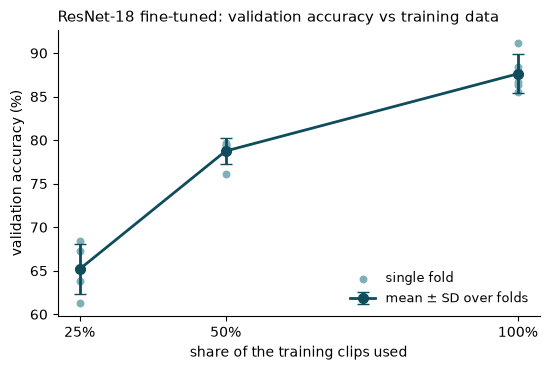

Change in mean validation accuracy: 25% to 50% of the training clips 13.6 points, 50% to 100% 8.9 points (fold SDs 2.8 / 1.5 / 2.2)


In [45]:
# Data size (ResNet-18, validation only): fine-tuned ResNet-18 trained on 25 / 50 / 100 % of the training clips.
def val_per_fold(base, seeds):
    """Best validation accuracy (%) per fold, seeds averaged within each fold; None if no seed is available."""
    # load every seed that exists
    runs = [r for r in (eval_io.load_run_or_none(RESULTS / f"{base}_s{s}") for s in seeds) if r is not None]
    if not runs:
        return None
    # stack all seeds, then average the seeds within each fold
    dev = pd.concat([r["dev"] for r in runs], ignore_index=True)
    return dev.groupby("fold")["best_val_acc"].mean() * 100


# run name (without the _s<seed> suffix) for each share of the training clips
DATA_SIZE_RUNS = {25: "line3/2026-10-28_r18-ft-frac25", 50: "line3/2026-10-28_r18-ft-frac50", 100: "line3/2026-10-20_r18-ft"}
# per-fold validation accuracy of each data size; drop sizes with no runs
size = {pct: val_per_fold(base, (0, 1, 2)) for pct, base in DATA_SIZE_RUNS.items()}
size = {pct: v for pct, v in size.items() if v is not None}
if len(size) == len(DATA_SIZE_RUNS):
    # mean and SD over folds for each data size
    pcts = list(size)
    means = [size[p].mean() for p in pcts]
    sds = [size[p].std() for p in pcts]
    # single folds as dots, mean +/- SD over folds as a line with error bars
    fig, ax = plt.subplots(figsize=(5.6, 3.8))
    for p in pcts:
        ax.scatter([p] * len(size[p]), size[p], color="#7FAFB8", s=22, zorder=2, label="single fold" if p == pcts[0] else None)
    ax.errorbar(pcts, means, yerr=sds, color="#0F4C5C", lw=2, marker="o", ms=7, capsize=4, zorder=3, label="mean ± SD over folds")
    ax.set_xticks(pcts, [f"{p}%" for p in pcts])
    ax.set_xlabel("share of the training clips used")
    ax.set_ylabel("validation accuracy (%)")
    ax.set_title("ResNet-18 fine-tuned: validation accuracy vs training data", fontsize=11, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    plt.tight_layout()
    plt.show()
    # change in mean accuracy between consecutive sizes, compared with the fold SD
    print(f"Change in mean validation accuracy: 25% to 50% of the training clips {means[1] - means[0]:.1f} points, "
          f"50% to 100% {means[2] - means[1]:.1f} points (fold SDs {sds[0]:.1f} / {sds[1]:.1f} / {sds[2]:.1f})")
else:
    print("Data-size figure skipped: not all three ResNet-18 data-size runs are available.")

**Amount of training data.** The figure shows validation accuracy of the fine-tuned ResNet-18 trained on a quarter, a half and all of each round's training clips. The validation set is the same throughout (validation only, by protocol). Seeds are averaged per fold, then mean ± SD over folds. Accuracy still rises clearly from half to all of the data, so more labelled clips would probably still help.

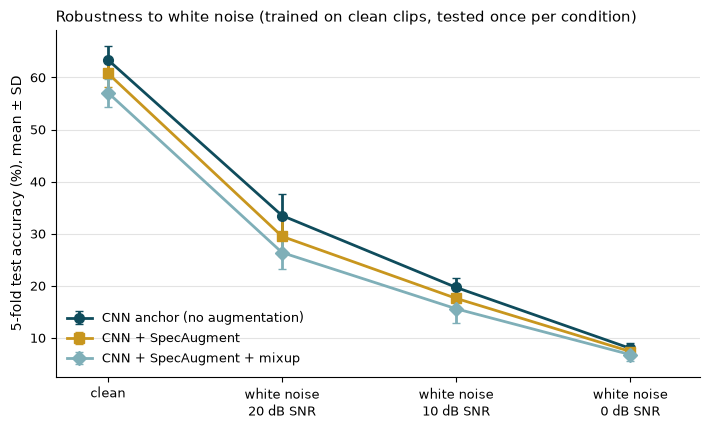

,seeds,clean,clean SD,white noise 20 dB,white noise 20 dB SD,white noise 10 dB,white noise 10 dB SD,white noise 0 dB,white noise 0 dB SD
method,,,,,,,,,
CNN anchor (no augmentation),3,63.4,2.7,33.5,4.2,19.7,1.8,8.0,1.0
CNN + SpecAugment,3,60.8,2.6,29.5,3.7,17.6,2.5,7.4,0.9
CNN + SpecAugment + mixup,3,57.1,2.7,26.4,3.1,15.6,2.7,6.8,1.2


Gap in test accuracy (points) per condition; no clear difference = gap smaller than both seed spreads (seed spreads per noise level):


,clean,20 dB,10 dB,0 dB
CNN anchor (no augmentation) vs CNN + SpecAugment,2.5,4.0,no clear difference,no clear difference
CNN anchor (no augmentation) vs CNN + SpecAugment + mixup,6.3,7.1,4.1,1.2
CNN + SpecAugment vs CNN + SpecAugment + mixup,3.7,3.1,2.0,no clear difference


Drop from clean to 0 dB (points): CNN anchor (no augmentation) 55.3, CNN + SpecAugment 53.5, CNN + SpecAugment + mixup 50.3


In [46]:
# Augmentation series: test accuracy on the clean folds and with white noise at 20, 10 and 0 dB SNR (declared before testing).
# the three configurations of the augmentation series
ROBUST_METHODS = ["CNN anchor (no augmentation)", "CNN + SpecAugment", "CNN + SpecAugment + mixup"]
if FINAL_RUNS and all(m in TABLE_RUNS for m in ROBUST_METHODS):
    # mean and SD over folds per noise condition
    ROBUST = eval_io.robust_table({m: TABLE_RUNS[m] for m in ROBUST_METHODS})
    # the same means unrounded, from the saved clean and noisy test predictions (seeds averaged within each fold, then
    # the mean over the five folds, as in eval_io.robust_table): differences are taken from these and rounded once
    def robust_mean_raw(runs, cond):
        per_seed = {}
        for r in runs:
            preds = r["test_preds"] if cond == "clean" else {k: d[cond] for k, d in r.get("robust_preds", {}).items() if cond in d}
            per_seed[r["config"]["seed"]] = pd.Series({k: float((p["y_true"] == p["y_pred"]).mean()) for k, p in sorted(preds.items())})
        return float((pd.DataFrame(per_seed) * 100).mean(axis=1).mean())

    ROBUST_RAW = pd.DataFrame({c: {m: robust_mean_raw(TABLE_RUNS[m], c) for m in ROBUST.index}
                               for c in ROBUST.columns if c != "seeds" and not c.endswith("_sd")})
    rd = round_half_away                          # defined with the paired comparisons above
    # condition columns (without the SD columns) and their axis labels
    conds = [c for c in ROBUST.columns if c != "seeds" and not c.endswith("_sd")]
    labels = ["clean" if c == "clean" else re.sub(r"^.*_snr(-?\d+)$", r"\1 dB", c) for c in conds]
    # one line per configuration across the conditions
    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    for (m, r), col, mk in zip(ROBUST.iterrows(), [FIG_TEAL, FIG_GOLD, FIG_MID], "osD"):
        ax.errorbar(range(len(conds)), [r[c] for c in conds], yerr=[r[f"{c}_sd"] for c in conds], color=col, marker=mk,
                    ms=7, lw=2, capsize=3, label=m)
    # axis labels, title and styling
    ax.set_xticks(range(len(conds)), [lab if lab == "clean" else f"white noise\n{lab} SNR" for lab in labels], fontsize=9.5)
    ax.set_ylabel("5-fold test accuracy (%), mean ± SD", fontsize=10)
    ax.set_title("Robustness to white noise (trained on clean clips, tested once per condition)", fontsize=11, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#E3E3E3", lw=0.8)
    ax.tick_params(axis="y", labelsize=9)
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    ax.set_xlim(-0.3, len(conds) - 0.6)
    plt.tight_layout()
    plt.show()
    with pd.option_context("display.width", 250, "display.max_columns", None):   # noise levels as readable column names
        display(ROBUST.rename(columns=lambda c: re.sub(r"white_snr(-?\d+)", r"white noise \1 dB", c).replace("_sd", " SD")))
    # accuracy drop from clean to the last noise condition
    worst = conds[-1]
    drop = ROBUST_RAW["clean"] - ROBUST_RAW[worst]
    # seed spread of one configuration under one condition
    def rb_seed_spread(runs, cond):
        """Range of the per-seed five-fold means (%) for one condition (same statistic as seed_spread in final_table)."""
        # per seed: the clean test predictions or the noisy ones of this condition
        means = []
        for r in runs:
            preds = r["test_preds"] if cond == "clean" else {k: d[cond] for k, d in r.get("robust_preds", {}).items() if cond in d}
            # all five folds are needed
            if len(preds) != 5:
                return float("nan")
            # five-fold mean accuracy of this seed
            means.append(100 * np.mean([float((p["y_true"] == p["y_pred"]).mean()) for p in preds.values()]))
        return max(means) - min(means) if len(means) > 1 else float("nan")

    # spread table; fall back to the clean seed spreads if any value is missing
    RB_SPREAD = pd.DataFrame({c: {m: rb_seed_spread(TABLE_RUNS[m], c) for m in ROBUST.index} for c in conds})
    from_clean = RB_SPREAD.isna().any().any()
    if from_clean:                                # per-seed robust results unavailable: clean-condition seed spreads
        RB_SPREAD = pd.DataFrame({c: RESULTS_TABLE.set_index("method").loc[ROBUST.index, "seed_spread"] for c in conds})
    # per condition and pair of configurations: the gap in points, or no clear difference (gap smaller than both seed spreads)
    gaps = {}
    for c, lab in zip(conds, labels):
        for i, a in enumerate(ROBUST.index):
            for b in ROBUST.index[i + 1:]:
                gap, sa, sb = abs(ROBUST_RAW.loc[a, c] - ROBUST_RAW.loc[b, c]), RB_SPREAD.loc[a, c], RB_SPREAD.loc[b, c]
                gaps.setdefault(f"{a} vs {b}", {})[lab] = "no clear difference" if gap < sa and gap < sb else f"{rd(gap):.1f}"
    print("Gap in test accuracy (points) per condition; no clear difference = gap smaller than both seed spreads "
          + ("(clean-condition seed spreads of the results table):" if from_clean else "(seed spreads per noise level):"))
    with pd.option_context("display.width", 250, "display.max_columns", None, "display.max_colwidth", None):
        display(pd.DataFrame(gaps).T)
    print("Drop from clean to " + labels[-1] + " (points): " + ", ".join(f"{m} {rd(drop[m]):.1f}" for m in ROBUST.index))
elif FINAL_RUNS:
    print("Robustness figure skipped: the three augmentation-series configurations must all be in FINAL_RUNS.")

**Noise robustness.** The table and figure give test accuracy of the three augmentation-series models on clean test folds and with white noise at 20, 10 and 0 dB SNR. These conditions were declared before testing, and values are mean ± SD over folds with seeds averaged per fold. The gaps and drops printed below the table are computed in this notebook from unrounded means and rounded once for display.

Accuracy falls steeply for all three, and neither augmentation helps. The anchor is ahead or not clearly different at every level. The noise is scaled to each clip's own power, so this is not a general noise-robustness result. Whether clips with long quiet stretches lose more than other clips is an untested hypothesis.

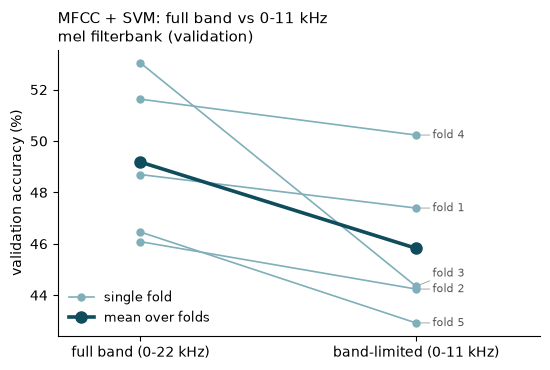

0-11 kHz minus full band, validation accuracy: mean -3.4 points, per fold -8.7 to -1.3, SD 3.1; lower on 5 of 5 folds


In [47]:
# Band-limit control (MFCC + SVM, validation only): the same MFCC + RBF-SVM on the full band and on 0-11 kHz input.
BAND_RUNS = {"full band (0-22 kHz)": "line1/2026-10-17_mfcc-svm", "band-limited (0-11 kHz)": "line1/2026-10-30_mfcc-svm-fmax11k"}
band = {label: val_per_fold(base, (0,)) for label, base in BAND_RUNS.items()}
if all(v is not None for v in band.values()):
    full, lim = band.values()
    folds = sorted(set(full.index) & set(lim.index))
    diff = lim[folds] - full[folds]
    fig, ax = plt.subplots(figsize=(5.6, 3.8))
    label_y, gap = {}, 0.06 * (max(full.max(), lim.max()) - min(full.min(), lim.min()))   # keep fold labels apart
    for k in sorted(folds, key=lambda k: lim[k]):
        label_y[k] = max(lim[k], max(label_y.values(), default=-1e9) + gap)
    for k in folds:
        ax.plot([0, 1], [full[k], lim[k]], color="#7FAFB8", lw=1.2, marker="o", ms=5, zorder=2,
                label="single fold" if k == folds[0] else None)
        ax.annotate(f"fold {k}", (1, lim[k]), xytext=(1.06, label_y[k]), textcoords="data", va="center", fontsize=8, color="#555",
                    arrowprops=dict(arrowstyle="-", color="#999999", lw=0.6, shrinkA=0, shrinkB=3))   # leader line to the dot
    ax.plot([0, 1], [full[folds].mean(), lim[folds].mean()], color="#0F4C5C", lw=2.6, marker="o", ms=8, zorder=3,
            label="mean over folds")
    ax.set_xticks([0, 1], list(BAND_RUNS))
    ax.set_xlim(-0.3, 1.45)
    ax.set_ylabel("validation accuracy (%)")
    ax.set_title("MFCC + SVM: full band vs 0-11 kHz\nmel filterbank (validation)", fontsize=11, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    plt.tight_layout()
    plt.show()
    lower = int((diff < 0).sum())
    print(f"0-11 kHz minus full band, validation accuracy: mean {diff.mean():+.1f} points, per fold {diff.min():+.1f} to "
          f"{diff.max():+.1f}, SD {diff.std():.1f}; lower on {lower} of {len(folds)} folds")
else:
    print("Band-limit figure skipped: one of the two MFCC + SVM runs is not available.")

**Band-limit control.** The figure compares validation accuracy of the same MFCC + SVM pipeline on the full-band (0-22 kHz) and band-limited (0-11 kHz) input, one line per fold. The only intended setting change is the upper edge of the MFCC mel filterbank: the 128 filters are spread over 0-11 kHz instead of 0-22 kHz, so the filters below 11 kHz also move. The two runs also used different software versions (Python and torch), most clearly on folds 2-5: the environment records of both runs are in their `env` entries in `support/frozen/runs.b64`. Only the validation set is used. The SVM uses probability calibration with a fixed seed 0 and runs once per fold.

Reducing the MFCC filterbank upper edge lowered mean validation accuracy by 3.4 points, lower on all five folds. Because the filters below 11 kHz also change, this does not show that the classifier uses information above 11 kHz, and it cannot tell sound content from recording cut-offs.

### 5.4 Comparison with previous work
Published ESC-50 results, each with its source (paper and page or table number) and how its setting differs from ours.
- **Not directly comparable:** inputs, training length, augmentation and pretraining all differ. So these numbers are not directly comparable with ours.
- **Page numbers:** table and page numbers refer to the arXiv or author version of each paper.
- **ESResNet rows:** quoted from Table II of Guzhov et al. (2021), who report them from their earlier ESResNet paper.

In [48]:
# Published ESC-50 results and where each number comes from (Section 7.2); not directly comparable with ours.
# Page numbers in "where" refer to the arXiv / author version of each paper.
# one row per published result: accuracy, where it is reported, folds used, pretraining
# and the main differences from our setting
# values are taken from the papers (two derived from reported error rates)
# order: no pretraining, then pretrained models, then human listeners
PRIOR_WORK = pd.DataFrame([
    {"method": "Piczak 2015a: SVM on MFCC + ZCR", "acc_5fold": 39.6, "where": "§3.2; Fig. 1 p.3, number in text p.4",
     "five_fold": "yes", "pretraining": "none", "difference": "12 MFCCs + ZCR (mean / SD) vs our 40 MFCCs + deltas"},
    {"method": "Piczak 2015a: random forest on MFCC + ZCR", "acc_5fold": 44.3, "where": "§3.2; Fig. 1 p.3, number in text p.4",
     "five_fold": "yes", "pretraining": "none", "difference": "12 MFCCs + ZCR (mean / SD) vs our 40 MFCCs + deltas"},
    {"method": "Piczak 2015b: CNN on log-mel segments", "acc_5fold": 64.5, "where": "§3.3, p.4, Fig. 4",
     "five_fold": "yes", "pretraining": "none", "difference": "log-mel + deltas on short segments, voting over segments"},
    {"method": "Tokozume 2018: Logmel-CNN + BN", "acc_5fold": 72.4, "where": "Table 1, p.7 (error 27.6%; accuracy derived)",
     "five_fold": "5 folds x 5 repeats", "pretraining": "none", "difference": "no mixing"},
    {"method": "Tokozume 2018: Logmel-CNN + BN + BC learning", "acc_5fold": 76.9, "where": "Table 1, p.7 (error 23.1%; accuracy derived)",
     "five_fold": "5 folds x 5 repeats", "pretraining": "none", "difference": "between-class mixing (not mixup), doubled training schedule"},
    {"method": "Zhang 2021: CRNN (CNN + BiGRU)", "acc_5fold": 79.9, "where": "Table 2, p.9",
     "five_fold": "yes", "pretraining": "none", "difference": "gammatone + deltas, 1.5 s segments with voting, 300 epochs"},
    {"method": "Zhang 2021: CRNN + attention + augmentation", "acc_5fold": 86.1, "where": "Table 2, p.9",
     "five_fold": "yes", "pretraining": "none", "difference": "adds attention and augmentation to the above"},
    {"method": "Zhang 2019: CRNN + temporal / channel attention", "acc_5fold": 85.8, "where": "Table 5, p.8 (85.8 ± 0.6)",
     "five_fold": "yes (5 repeats)", "pretraining": "none",
     "difference": "log-gammatone + deltas on 128-frame segments, masking + mixup, 400 epochs"},
    {"method": "Kong 2020: CNN14 from scratch", "acc_5fold": 83.3, "where": "Table XIII, p.10",
     "five_fold": "yes", "pretraining": "none", "difference": "14-layer CNN designed for AudioSet-scale training"},
    {"method": "Guzhov 2021: ESResNet, random init.", "acc_5fold": 83.15, "where": "Table II, p.6",
     "five_fold": "yes", "pretraining": "none", "difference": "ResNet-50 + attention on STFT, 300 epochs, heavy augmentation"},
    {"method": "Guzhov 2021: ESResNet, ImageNet", "acc_5fold": 91.50, "where": "Table II, p.6",
     "five_fold": "yes", "pretraining": "ImageNet", "difference": "ResNet-50 + attention on STFT, 300 epochs, heavy augmentation"},
    {"method": "Gong 2021: AST, ImageNet", "acc_5fold": 88.7, "where": "Table 7, p.4 (88.7 ± 0.7)",
     "five_fold": "5 folds x 3 repeats", "pretraining": "ImageNet", "difference": "transformer, much larger model, frequency / time masking"},
    {"method": "Kong 2020: CNN14 fine-tuned from AudioSet", "acc_5fold": 94.7, "where": "Table XIII, p.10",
     "five_fold": "yes", "pretraining": "AudioSet", "difference": "AudioSet audio pretraining"},
    {"method": "Gong 2021: AST, ImageNet + AudioSet", "acc_5fold": 95.6, "where": "Table 7, p.4 (95.6 ± 0.4)",
     "five_fold": "5 folds x 3 repeats", "pretraining": "ImageNet + AudioSet", "difference": "adds AudioSet pretraining (highest result in this table)"},
    {"method": "Piczak 2015a: human listeners (crowd-sourced)", "acc_5fold": 81.3, "where": "§3.1, p.2",
     "five_fold": "n/a", "pretraining": "n/a", "difference": "historical reference only, not a model",
     "note": "crowd-listener accuracy, not a model"},
])
# only the human-listener row has a note; the others get an empty string
PRIOR_WORK["note"] = PRIOR_WORK["note"].fillna("")   # acc_5fold of the human row is listener accuracy, not 5-fold model accuracy
# wide display so the long text columns are not cut
with pd.option_context("display.width", 300, "display.max_colwidth", 90):
    # rename columns for display only; the stored frame keeps the short names
    display(PRIOR_WORK.set_index("method").rename(columns={
        "acc_5fold": "accuracy (%)", "where": "where in the paper", "five_fold": "official 5 folds",
        "difference": "difference from our setting"}))

,accuracy (%),where in the paper,official 5 folds,pretraining,difference from our setting,note
method,,,,,,
Piczak 2015a: SVM on MFCC + ZCR,39.60,"§3.2; Fig. 1 p.3, number in text p.4",yes,none,12 MFCCs + ZCR (mean / SD) vs our 40 MFCCs + deltas,
Piczak 2015a: random forest on MFCC + ZCR,44.30,"§3.2; Fig. 1 p.3, number in text p.4",yes,none,12 MFCCs + ZCR (mean / SD) vs our 40 MFCCs + deltas,
Piczak 2015b: CNN on log-mel segments,64.50,"§3.3, p.4, Fig. 4",yes,none,"log-mel + deltas on short segments, voting over segments",
Tokozume 2018: Logmel-CNN + BN,72.40,"Table 1, p.7 (error 27.6%; accuracy derived)",5 folds x 5 repeats,none,no mixing,
Tokozume 2018: Logmel-CNN + BN + BC learning,76.90,"Table 1, p.7 (error 23.1%; accuracy derived)",5 folds x 5 repeats,none,"between-class mixing (not mixup), doubled training schedule",
Zhang 2021: CRNN (CNN + BiGRU),79.90,"Table 2, p.9",yes,none,"gammatone + deltas, 1.5 s segments with voting, 300 epochs",
Zhang 2021: CRNN + attention + augmentation,86.10,"Table 2, p.9",yes,none,adds attention and augmentation to the above,
Zhang 2019: CRNN + temporal / channel attention,85.80,"Table 5, p.8 (85.8 ± 0.6)",yes (5 repeats),none,"log-gammatone + deltas on 128-frame segments, masking + mixup, 400 epochs",
Kong 2020: CNN14 from scratch,83.30,"Table XIII, p.10",yes,none,14-layer CNN designed for AudioSet-scale training,


**Reading the comparison.**
- **From scratch:** our from-scratch CNN is close to the first published CNN on ESC-50 (Piczak, 2015b).
- **Higher published results:** among these selected results, published from-scratch and ImageNet-pretrained models reach higher accuracy, but with larger networks, much longer training or heavier augmentation. AudioSet pretraining gives the best results in this selection, and we did not test it. The table is a selection, not a complete list of ESC-50 results.
- **Use of the table:** because the settings differ, the table places our results in context rather than ranking them.

### 5.5 Reading the results
Short answers to the five questions of Section 1. The full reading is in each method's subsection.

| Question | Answer | Details |
|---|---|---|
| Q1 | MFCC models are clearly below every CNN. Random forest vs SVM cannot be judged with one SVM seed | 4.1.4 |
| Q2 | The CNN is clearly above the MFCC baseline. Doubling its width makes no clear difference | 4.2.4 |
| Q3 | Full fine-tuning gives the best test accuracy. Frozen features are not clearly different from the CNN | 4.3.4 |
| Q4 | The CRNN is far above the BiLSTM and has higher recall than the CNN on most classes. The cause is not attributed (compound comparison) | 4.4.4, 5.3 |
| Q5 | Neither augmentation step helped, on clean or noisy test clips | 4.5.4, 5.3 |

**Main findings.**
- **Best overall:** the fine-tuned ImageNet ResNet-18 is well ahead of every model trained only on ESC-50. Among those, the CRNN is best.
- **Pretraining:** the same ResNet-18 from random weights is far lower. That comparison also changes the epoch cap and the normalisation, so it does not measure the pretrained weights alone.
- **Size:** size by itself does not explain the ranking. The three ResNet-18 configurations have the same number of parameters but very different accuracy.
- **Ties:** gaps that our rule calls no clear difference (Section 5.1) are not ranked.

## 6. Discussion

This section discusses what the results mean across methods. Section 6.1 shows which classes most methods get wrong and discusses how the three augmentation-series CNNs cope with added noise (results in Section 5.3). Section 6.2 lists the strengths, weaknesses and limitations of each method and possible future work.

### 6.1 Cross-model analysis

The cell below looks across all methods at once, using the test predictions of the runs in the results table, and shows which classes most methods get wrong. The CNN anchor gave the same test predictions as the CNN (from scratch), so the error table counts that model once. What each method costs and how the models cope with noise are in the cost and robustness tables of Section 5.3; the insight below uses the error table and the robustness table.

In [49]:
# Shared analysis across methods: per-class errors of the runs in FINAL_RUNS (Section 5); cost and robustness: Section 5.3.


def per_class_errors(table_runs, class_names=None):
    """Error rate (%) = 100 - recall per class and method, plus mean error and the number of methods above 50%."""
    out = {}
    for name, runs in table_runs.items():
        runs = [r for r in runs if r is not None]
        if not runs:
            continue
        cm = eval_io.confusion(runs).values       # test predictions, summed over all seeds and folds (M3)
        support = cm.sum(axis=1)                  # classes absent from these predictions get NaN, not 100% error
        out[name] = np.round(np.where(support > 0, 100 - 100 * np.diag(cm) / np.maximum(support, 1), np.nan), 1)
    df = pd.DataFrame(out)
    if class_names is not None:
        df.index = list(class_names)
    if len(df.columns):
        df["mean_error"] = df[list(out)].mean(axis=1).round(1)
        df["n_methods_over_50"] = (df[list(out)] > 50).sum(axis=1)       # NaN never counts as over 50
        df = df.sort_values(["n_methods_over_50", "mean_error"], ascending=False)
    return df


if TABLE_RUNS:
    # methods with identical test predictions count once (the CNN anchor = CNN (from scratch), SAME_AS in Section 5.1)
    DISTINCT_RUNS = {m: rs for m, rs in TABLE_RUNS.items() if SAME_AS[m] == m}
    SAME_NOTES = [f"{m} (same test predictions as {SAME_AS[m]})" for m in TABLE_RUNS if SAME_AS[m] != m]
    ERROR_TABLE = per_class_errors(DISTINCT_RUNS, FIG_NAMES)   # readable class names, as in the Section 5 figures
    # short column names so the table fits the page
    SHORT_NAMES = {"MFCC + SVM": "SVM", "MFCC + random forest": "RF", "CNN (from scratch)": "CNN", "CNN 2x width": "CNN 2x",
                   "ResNet-18 linear probe": "R18 probe", "ResNet-18 fine-tuned": "R18 FT", "ResNet-18 random init.": "R18 random",
                   "CRNN": "CRNN", "BiLSTM": "BiLSTM", "CNN + SpecAugment": "+SpecAug", "CNN + SpecAugment + mixup": "+SpecAug +mixup",
                   "mean_error": "mean error", "n_methods_over_50": "methods over 50%"}
    print(f"Per-class test error rate (%), {len(DISTINCT_RUNS)} distinct methods (counted once: {'; '.join(SAME_NOTES) or 'none'}).")
    print("Order: number of methods with an error above 50%, then mean error over the methods; 10 hardest classes.")
    print("Columns: " + "; ".join(f"{v} = {k}" for k, v in SHORT_NAMES.items() if k in DISTINCT_RUNS))
    with pd.option_context("display.width", 250, "display.max_columns", None):
        display(ERROR_TABLE.head(10).rename(columns=SHORT_NAMES))

Per-class test error rate (%), 11 distinct methods (counted once: CNN anchor (no augmentation) (same test predictions as CNN (from scratch))).
Order: number of methods with an error above 50%, then mean error over the methods; 10 hardest classes.
Columns: SVM = MFCC + SVM; RF = MFCC + random forest; CNN = CNN (from scratch); CNN 2x = CNN 2x width; R18 probe = ResNet-18 linear probe; R18 FT = ResNet-18 fine-tuned; R18 random = ResNet-18 random init.; CRNN = CRNN; BiLSTM = BiLSTM; +SpecAug = CNN + SpecAugment; +SpecAug +mixup = CNN + SpecAugment + mixup


,SVM,RF,CNN,CNN 2x,R18 probe,R18 FT,R18 random,CRNN,BiLSTM,+SpecAug,+SpecAug +mixup,mean error,methods over 50%
water drops,82.5,85.8,68.3,64.2,66.7,42.5,55.0,43.3,72.5,73.3,75.8,66.4,9
helicopter,40.0,54.2,65.0,66.7,53.3,50.0,65.0,69.2,84.2,75.8,70.8,63.1,9
engine,77.5,75.8,51.7,51.7,44.2,25.0,68.3,52.5,80.8,57.5,65.8,59.2,9
washing machine,70.0,67.5,45.0,42.5,50.8,42.5,75.8,50.8,60.8,53.3,65.8,56.8,8
cat,55.0,55.0,65.0,55.0,52.5,18.3,32.5,26.7,80.8,60.0,75.8,52.4,8
door wood creaks,95.0,99.2,54.2,49.2,44.2,25.8,69.2,48.3,82.5,57.5,61.7,62.4,7
car horn,72.5,90.8,58.3,55.0,49.2,25.0,35.0,27.5,88.3,61.7,63.3,57.0,7
laughing,60.0,80.0,47.5,60.0,54.2,15.0,40.0,44.2,81.7,62.5,75.8,56.4,7
drinking sipping,67.5,73.3,56.7,50.0,52.5,28.3,50.0,40.0,65.0,59.2,65.0,55.2,7
hen,70.0,73.3,55.0,45.0,68.3,17.5,35.8,35.0,71.7,59.2,57.5,53.5,7


**Insight.**
- **Two groups of hard classes** (error table above):
  1. Steady, machine-like sounds without clear onsets, such as helicopter, engine and washing machine. For the best method, helicopter is most often mistaken for airplane (confusion matrix, Section 5.1).
  2. Quiet, sparse sounds whose short events are separated by long quiet stretches. Examples are water drops, drinking and sipping, and a creaking wooden door. Water drops is also among the quietest classes in the EDA, so much of each clip carries little class information.
- **Easiest classes:** over all methods, thunderstorm, door wood knock and pouring water (per-class heatmap, Section 5.3).
- **Data, not one model:** the classes at the top of the error table (ordered by how many methods get them wrong more than half the time, then by mean error) are wrong more than half the time for most of the 11 distinct methods. This suggests that part of the difficulty lies in the data rather than in any one model, although the best model does much better on some of them (door wood creaks: 74.2% recall with the fine-tuned ResNet-18).
- **Quiet clips:** quietness alone does not explain the errors. Can opening is also mostly quiet, but most methods recognise it well in the heatmap, possibly because its single sharp event is distinctive.
- **Best model:** the fine-tuned ResNet-18 has the lowest error on almost every hard class, but the set of hard classes stays similar across methods.
- **Noise** (robustness table, Section 5.3): under added white noise, all three augmentation-series models fall steeply and are low at 0 dB, though still above chance. Neither augmentation helps. The anchor is clearly ahead at 20 dB, and its lead over SpecAugment is not clear at 10 and 0 dB. This is consistent with masking and mixing not imitating additive broadband noise.

### 6.2 Strengths, weaknesses, limitations, future work

**Shared strengths.**
- The final settings, the no-clear-difference rule and the noise levels were all chosen without test results.
- Every neural and random-forest configuration ran with three seeds; the SVM ran once per fold with a fixed probability-calibration seed.
- Each test fold was used once per selected run (34 runs); the data-size and band-limit runs were validation only.

**Shared weaknesses and limitations.**
- Our training schedules are short compared with much of the literature. So our numbers describe what each method reaches under a student compute budget, not its best possible accuracy.
- ESC-50 is small (40 clips per class), so a few clips can move a per-class recall noticeably.
- The best model, the fine-tuned ResNet-18, still misses about 15% of clean test clips, and only the three small CNNs of the augmentation series were noise-tested, with accuracy roughly halving at 20 dB. So deployment readiness is not established.

*Traditional features (4.1).*
- **Strengths:** it trains in seconds, has no learned features and gives a transparent lower bar.
- **Weaknesses:** the mean and spread over time discard the order of events. That is a plausible reason for its errors on rhythmic or short events, but this experiment does not establish it.
- **Limitations:** the SVM runs once per fold, so its variation between seeds is unknown. The band-limit control changes the lower mel filters as well, so it leaves open whether the drop comes from the sound or from recording cut-offs.
- **Future work:** a pre-declared comparison that keeps the temporal structure with the classifier and protocol fixed. We would also test on recordings from outside ESC-50.

*CNN from scratch (4.2).*
- **Strengths:** a small, stable model and the fixed anchor of the augmentation series. The separate anchor runs gave identical test predictions.
- **Weaknesses:** it stays well below the fine-tuned ResNet-18 and the CRNN.
- **Limitations:** we tested only one change (doubling the width), under one short schedule without learning-rate tuning.
- **Future work:** a longer schedule with a learning-rate schedule, before drawing conclusions about width.

*ImageNet-pretrained ResNet-18 (4.3).*
- **Strengths:** the most accurate configuration, with short training per fold on a Tesla T4 GPU.
- **Weaknesses:** ImageNet features come from photographs, and we did not try audio pretraining.
- **Limitations:** the from-scratch comparison changes three settings at once, so it does not isolate the pretrained weights. The data-size runs are validation results only.
- **Future work:** an AudioSet-pretrained model (PANNs or AST) under the same protocol, and a one-variable ablation of the initialisation.

*Temporal models (4.4).*
- **Strengths:** the CRNN is the best model without external data. It has higher test recall than the from-scratch CNN on most classes.
- **Weaknesses:** the frame-sequence BiLSTM stayed weak, and we did not try a stronger recurrent baseline.
- **Limitations:** the CRNN and the CNN differ in several ways at once. So the per-class gains are not evidence that modelling time is the cause.
- **Future work:** one-variable ablations under the same budget: the convolutional front end, GRU versus LSTM, and the number of recurrent layers. We would also add attention under the same protocol: in the CRNN following Zhang et al. (2021), and separately in the small CNN.

*Augmentation and cross-model analysis (4.5, 6.1).*
- **Strengths:** the noise conditions were declared before testing. The negative result (both augmentation steps lowered accuracy under the fixed schedule) is kept in the results table.
- **Weaknesses:** each augmentation was tried at one strength under the short schedule.
- **Limitations:** the noise is synthetic white noise set relative to each clip's own power. Clips with long quiet stretches may lose more, but we did not test this. The test is not a general noise-robustness result. It also covers only the three small CNNs.
- **Future work:** longer schedules for the augmented models, recorded background noise instead of white noise, and the same noise test for every model.

## 7. Reproducibility & References

- **Environment**: the devices, Python and torch versions of the final runs are summarised in the first table of Section 7.1. They come from the `env.json` file saved with each fold. The library versions of this notebook run are printed in Section 0.1.
- **Seeds**: the seed of every run is stored in its `config.json`. All runs use `eval_io.seed_everything`.
- **Protocol**: official 5 folds. Training, validation and selection use only the training and validation sets. For the selected configurations, each test fold is evaluated once per seed, after the final settings were chosen (audit summary in Section 7.1); the data-size and band-limit runs are validation only.
- **Data & results**: the split and data fingerprints are in Section 2.3. The results of every run shown are saved in `support/frozen/` (Section 0.3). The ESC-50 audio is at https://github.com/karolpiczak/ESC-50.

### 7.1 Run log and audit summary
We compute the tables below from the saved run data.
1. **Where the final runs were trained,** summarised by method section. Its `device` column is the CUDA GPU when there was one; otherwise it records whether Apple's MPS backend was available on the machine, not that it was used. So the MFCC + SVM fold marked `mps` ran on the CPU (scikit-learn), and the neural models only use CUDA or the CPU (Section 4.0).
2. **Settings of every final configuration.** "Compound" marks a comparison that changes more than one setting, with the same flags as the paired comparisons of Section 5.3. For the MFCC models the `input` column reads `logmel_128x431`. Their MFCCs are computed from the raw audio through the same mel front end, and this field only selects the band.
3. **Audit summary, one row per method.** It shows whether all seeds were selected together before testing and whether each test fold was used once. It also shows whether the saved test timestamps and prediction hashes match the test log. The last line printed by the audit cell reports the fold-1 re-runs that other team members ran independently.

The project repository ([https://github.com/tangsteven64/comp9444-fireworks](https://github.com/tangsteven64/comp9444-fireworks)) holds this notebook and its `support/` folder. The saved records summarised above (selection times, test logs covering all 34 selected runs, and the fold-1 re-runs) are in `support/frozen/`, which the notebook reads.

In [50]:
# Where the final runs were trained: one row per (method section, device, Python, torch), from each fold's env.json.
SECTION_NAMES = {"line1": "4.1 MFCC statistics", "line2": "4.2 CNN from scratch", "line3": "4.3 ResNet-18",
                 "line4": "4.4 Temporal models", "line5": "4.5 Augmentation series"}   # run-folder names
if FINAL_RUNS:
    env_rows = []
    for name, runs in TABLE_RUNS.items():
        for r in runs:
            for k, env in r["env"].items():
                env_rows.append({"section": SECTION_NAMES[r["config"]["line"]], "device": env.get("device", "?"), "python": env.get("python", "?"),
                                 "torch": env.get("torch", "?"), "run": r["key"], "fold": k})
    ENV_TABLE = (pd.DataFrame(env_rows).groupby(["section", "device", "python", "torch"])
                 .agg(runs=("run", "nunique"), folds=("fold", "size")).reset_index())
    display(ENV_TABLE)
    expected = {(r["key"], k) for runs in TABLE_RUNS.values() for r in runs for k in r["dev"]["fold"]}
    missing = sorted(expected - {(e["run"], e["fold"]) for e in env_rows})
    print(f"Environment records available for all {len(expected)} selected run-fold pairs." if not missing else
          f"Environment records available for {len(expected) - len(missing)} of {len(expected)} selected run-fold pairs; missing: {missing}")

,section,device,python,torch,runs,folds
0,4.1 MFCC statistics,cpu,3.13.16,2.11.0+cpu,4,19
1,4.1 MFCC statistics,mps,3.12.13,2.2.2,1,1
2,4.2 CNN from scratch,Tesla T4,3.13.15,2.11.0+cu130,1,5
3,4.2 CNN from scratch,Tesla T4,3.13.16,2.11.0+cu130,5,25
4,4.3 ResNet-18,Tesla T4,3.13.15,2.11.0+cu130,6,30
5,4.3 ResNet-18,Tesla T4,3.13.16,2.11.0+cu130,3,15
6,4.4 Temporal models,Tesla T4,3.13.15,2.11.0+cu130,6,30
7,4.5 Augmentation series,Tesla T4,3.13.15,2.11.0+cu130,1,1
8,4.5 Augmentation series,Tesla T4,3.13.16,2.11.0+cu130,9,44


Environment records available for all 170 selected run-fold pairs.


In [51]:
# Settings of every final configuration, from config.json (compound = more than one setting changed).
def _arch_text(cfg):
    a = cfg.get("arch") or cfg.get("model") or {}
    parts = [a.get("type", "?")] + [f"{k}={v}" for k, v in a.items() if k != "type"]
    if cfg.get("features"):
        parts.insert(0, f"features={cfg['features'].get('type')}")
    return ", ".join(str(p) for p in parts)


if FINAL_RUNS:
    cfg_rows = []
    method_of = {rel: m for m, rels in FINAL_RUNS.items() for rel in rels}   # run name -> method name
    for name, runs in TABLE_RUNS.items():
        c = runs[0]["config"]
        cfg_rows.append({"method": name, "section": SECTION_NAMES[c["line"]], "group": GROUP_NAMES[c["group"]], "input": c["input"],
                         "model": _arch_text(c), "epochs_max": c.get("epochs_max", "-"),
                         "patience": c.get("early_stop_patience", "-"), "lr": c.get("lr", "-"),
                         "batch": c.get("batch_size", "-"), "augmentation": c.get("augment", "none"),
                         "seeds": ", ".join(str(r["config"]["seed"]) for r in runs),
                         "compared with": method_of.get(c.get("compare_to"), c.get("compare_to", "-")), "changed_variable": c.get("changed_variable", "-"),
                         # the explicit compound flags of the pre-declared paired comparisons (PAIRED, Section 5.3)
                         "compound": "yes" if any({a, b} == {name, method_of.get(c.get("compare_to"))} and comp
                                                   for a, b, comp in PAIRED) else ""})
    CONFIG_TABLE = pd.DataFrame(cfg_rows).set_index("method")
    with pd.option_context("display.max_colwidth", 90, "display.width", 400, "display.max_columns", None):
        display(CONFIG_TABLE.rename(columns={"epochs_max": "max epochs", "changed_variable": "changed variable"}))

,section,group,input,model,max epochs,patience,lr,batch,augmentation,seeds,compared with,changed variable,compound
method,,,,,,,,,,,,,
MFCC + SVM,4.1 MFCC statistics,non-deep (MFCC statistics),logmel_128x431,"features=mfcc_stats, svm, C=10.0, gamma=scale",-,-,-,-,none,0,baseline,none,
MFCC + random forest,4.1 MFCC statistics,non-deep (MFCC statistics),logmel_128x431,"features=mfcc_stats, rf, n_estimators=500, max_features=sqrt",-,-,-,-,none,"0, 1, 2",MFCC + SVM,model,
CNN (from scratch),4.2 CNN from scratch,trained from scratch,logmel_128x431,"cnn, conv_channels=[32, 64, 128, 256], dropout=0.3",50,8,0.001,32,none,"0, 1, 2",baseline,none,
CNN 2x width,4.2 CNN from scratch,trained from scratch,logmel_128x431,"cnn, conv_channels=[64, 128, 256, 512], dropout=0.3",50,8,0.001,32,none,"0, 1, 2",CNN (from scratch),arch,
ResNet-18 linear probe,4.3 ResNet-18,ImageNet-pretrained,logmel_128x431,"resnet18, pretrained=imagenet, mode=linear_probe",50,8,0.001,32,none,"0, 1, 2",baseline,none,
ResNet-18 fine-tuned,4.3 ResNet-18,ImageNet-pretrained,logmel_128x431,"resnet18, pretrained=imagenet, mode=full_finetune",30,8,0.0001,32,none,"0, 1, 2",ResNet-18 linear probe,arch+epochs_max+lr,yes
ResNet-18 random init.,4.3 ResNet-18,trained from scratch,logmel_128x431,"resnet18, pretrained=none, mode=full_finetune",60,8,0.0001,32,none,"0, 1, 2",ResNet-18 fine-tuned,arch+epochs_max+norm,yes
CRNN,4.4 Temporal models,trained from scratch,logmel_128x431,"crnn, conv_channels=[32, 64, 128, 128], rnn_hidden=128, dropout=0.3",50,8,0.001,32,none,"0, 1, 2",baseline,none,
BiLSTM,4.4 Temporal models,trained from scratch,logmel_128x431,"lstm, time_pool=2, rnn_hidden=128, rnn_layers=2, dropout=0.3",50,8,0.001,32,none,"0, 1, 2",CRNN,arch,yes


In [52]:
# Per method: selected before testing (same record for every seed, all tests later), test folds, file checks.
if FINAL_RUNS:
    audit_rows = []
    # per run of each method in the results table: check its test log
    for name, runs in TABLE_RUNS.items():
        for r in runs:
            ev = (EVIDENCE or {}).get("test_logs", {}).get(r["key"])
            # runs without a saved test log are listed but not checked
            if ev is None:
                audit_rows.append({"method": name, "run": r["key"], "PASS": "no saved test log"})
                continue
            # test log rows: time, fold and SHA-256 of the saved predictions
            log = pd.DataFrame(ev["rows"], columns=["time", "fold", "sha256"]).astype({"fold": int})
            log["t"] = pd.to_datetime(log["time"], utc=True)
            # recorded time at which the configuration was selected
            sel_at = (r["selected"] or {}).get("selected_at", "")
            # test times match the run's records and prediction hashes match the log
            tested_match = all(r["tested_at"].get(int(f)) == t for t, f in zip(log["time"], log["fold"]))
            hash_ok = all(ev["preds_sha256"].get(str(f)) == h for f, h in zip(log["fold"], log["sha256"]))
            # collect the per-run checks
            row = {"method": name, "run": r["key"], "log rows": len(log), "folds": log["fold"].nunique(),
                   "repeated folds": int(log["fold"].duplicated().sum()),
                   "all tests after selection": bool(sel_at) and bool((log["t"] > pd.Timestamp(sel_at)).all()),
                   "files ok": tested_match and hash_ok, "robustness log rows": ev["robust_rows"]}
            # a run passes if every fold was tested exactly once after selection and its timestamps and hashes match
            row["PASS"] = (row["log rows"] == eval_io.N_FOLDS and set(log["fold"]) == set(range(1, eval_io.N_FOLDS + 1))
                           and row["repeated folds"] == 0 and row["all tests after selection"] and tested_match and hash_ok)
            audit_rows.append(row)
    # one row per run
    AUDIT_TABLE = pd.DataFrame(audit_rows).set_index("run")
    # helpers for the summary table
    yes = lambda ok: "yes" if ok else "no"   # noqa: E731
    check_col = "saved timestamps and prediction hashes match the test log"
    # one summary row per method
    summary = []
    for name, a in AUDIT_TABLE.groupby("method", sort=False):
        a = a.reindex(columns=["folds", "repeated folds", "all tests after selection", "files ok", "robustness log rows"])
        # the selection record must be the same for every seed of the method
        sel = TABLE_RUNS[name][0]["selected"] or {}
        same_record = all((r["selected"] or {}) == sel for r in TABLE_RUNS[name])
        summary.append({"method": name, "seeds": len(a),
                        "selected before testing": yes(same_record and a["all tests after selection"].eq(True).all()),
                        "test folds used": f"{a['folds'].min():.0f} of {eval_io.N_FOLDS}"
                                           + (", each once" if a["repeated folds"].eq(0).all() else ", not each once"),
                        check_col: yes(a["files ok"].eq(True).all()),
                        "noise-test log rows per seed": ", ".join(str(int(v)) for v in sorted(set(a["robustness log rows"])))
                                                        if a["robustness log rows"].gt(0).any() else "-"})
    # show the summary, then the number of runs that pass the test-fold audit
    with pd.option_context("display.width", 250, "display.max_columns", None):
        display(pd.DataFrame(summary).set_index("method"))
    n_pass = int((AUDIT_TABLE['PASS'] == True).sum())  # noqa: E712
    print(f"{n_pass} of {len(AUDIT_TABLE)} selected runs pass the test-fold audit: one test record per fold, "
          "each made after the configuration was selected.")

    # independent fold-1 re-runs: the saved records in support/frozen/evidence.b64 (original and re-run of one selected run)
    reruns = EVIDENCE.get("fold1_reruns", [])
    if reruns:
        hw = lambda d: "cpu" if d in ("cpu", "mps") else d   # noqa: E731  ('mps' only records availability; scikit-learn uses the CPU)
        diffs = [100 * (c["rerun"]["best_val_acc"] - c["original"]["best_val_acc"]) for c in reruns]
        same_hw = all(hw(c["original"]["device"]) == hw(c["rerun"]["device"]) for c in reruns)
        devices = {}                       # devices of all originals and re-runs, per group
        for c in reruns:
            devices.setdefault("MFCC" if c["line"] == "line1" else "neural", set()).update(
                hw(c[k]["device"]) for k in ("original", "rerun"))
        methods = {c["line"] for c in reruns}
        n_words = dict(enumerate(["no", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"]))
        if (same_hw and all(c["same_config"] for c in reruns) and methods == set(SECTION_NAMES)
                and devices == {"neural": {"Tesla T4"}, "MFCC": {"cpu"}}):
            print(f"For at least one selected run of each method, another team member independently re-ran fold 1 on the same type "
                  f"of hardware (a Tesla T4 GPU for the neural models, a CPU for the MFCC classifier); all {n_words.get(len(reruns), len(reruns))} "
                  f"re-runs {'matched' if max(abs(d) for d in diffs) < 0.005 else 'were compared with'} the original validation accuracy "
                  f"(difference {max(abs(d) for d in diffs):.2f} points).")
        else:
            print(f"{len(reruns)} independent fold-1 re-runs of {len(methods)} of {len(SECTION_NAMES)} methods; largest difference "
                  f"in validation accuracy {max(abs(d) for d in diffs):.2f} points.")


,seeds,selected before testing,test folds used,saved timestamps and prediction hashes match the test log,noise-test log rows per seed
method,,,,,
MFCC + SVM,1,yes,"5 of 5, each once",yes,-
MFCC + random forest,3,yes,"5 of 5, each once",yes,-
CNN (from scratch),3,yes,"5 of 5, each once",yes,-
CNN 2x width,3,yes,"5 of 5, each once",yes,-
ResNet-18 linear probe,3,yes,"5 of 5, each once",yes,-
ResNet-18 fine-tuned,3,yes,"5 of 5, each once",yes,-
ResNet-18 random init.,3,yes,"5 of 5, each once",yes,-
CRNN,3,yes,"5 of 5, each once",yes,-
BiLSTM,3,yes,"5 of 5, each once",yes,-


34 of 34 selected runs pass the test-fold audit: one test record per fold, each made after the configuration was selected.
For at least one selected run of each method, another team member independently re-ran fold 1 on the same type of hardware (a Tesla T4 GPU for the neural models, a CPU for the MFCC classifier); all six re-runs matched the original validation accuracy (difference 0.00 points).


### 7.2 References

Every work cited in Sections 1-6. Software libraries are linked where they are used (Sections 4.0 to 4.5).

- Bello, J. P., Silva, C., Nov, O., Dubois, R. L., Arora, A., Salamon, J., Mydlarz, C., & Doraiswamy, H. (2019). SONYC: A system for monitoring, analyzing, and mitigating urban noise pollution. *Communications of the ACM*, 62(2), 68–77. https://doi.org/10.1145/3224204
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Çakır, E., Parascandolo, G., Heittola, T., Huttunen, H., & Virtanen, T. (2017). Convolutional recurrent neural networks for polyphonic sound event detection. *IEEE/ACM Transactions on Audio, Speech, and Language Processing*, 25(6), 1291–1303. https://doi.org/10.1109/TASLP.2017.2690575
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder-decoder for statistical machine translation. *EMNLP 2014*, 1724–1734. https://doi.org/10.3115/v1/D14-1179
- Choi, K., Fazekas, G., Sandler, M., & Cho, K. (2017). Convolutional recurrent neural networks for music classification. *ICASSP 2017*, 2392–2396. https://doi.org/10.1109/ICASSP.2017.7952585
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20(3), 273–297. https://doi.org/10.1007/BF00994018
- Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. *CVPR 2009*, 248–255. https://doi.org/10.1109/CVPR.2009.5206848
- Gong, Y., Chung, Y.-A., & Glass, J. (2021). AST: Audio Spectrogram Transformer. *Interspeech 2021*, 571–575. https://doi.org/10.21437/Interspeech.2021-698
- Guzhov, A., Raue, F., Hees, J., & Dengel, A. (2021). ESResNe(X)t-fbsp: Learning robust time-frequency transformation of audio. *2021 International Joint Conference on Neural Networks (IJCNN)*, 1–8. https://doi.org/10.1109/IJCNN52387.2021.9533654
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. *CVPR 2016*, 770–778. https://doi.org/10.1109/CVPR.2016.90
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735
- Jain, D., Ngo, H., Patel, P., Goodman, S., Findlater, L., & Froehlich, J. (2020). SoundWatch: Exploring smartwatch-based deep learning approaches to support sound awareness for deaf and hard of hearing users. *ASSETS 2020*, 1–13. https://doi.org/10.1145/3373625.3416991
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR 2015*. https://arxiv.org/abs/1412.6980
- Kong, Q., Cao, Y., Iqbal, T., Wang, Y., Wang, W., & Plumbley, M. D. (2020). PANNs: Large-scale pretrained audio neural networks for audio pattern recognition. *IEEE/ACM Transactions on Audio, Speech, and Language Processing*, 28, 2880–2894. https://doi.org/10.1109/TASLP.2020.3030497
- Palanisamy, K., Singhania, D., & Yao, A. (2020). Rethinking CNN models for audio classification. *arXiv:2007.11154*. https://arxiv.org/abs/2007.11154
- Park, D. S., Chan, W., Zhang, Y., Chiu, C.-C., Zoph, B., Cubuk, E. D., & Le, Q. V. (2019). SpecAugment: A simple data augmentation method for automatic speech recognition. *Interspeech 2019*, 2613–2617. https://doi.org/10.21437/Interspeech.2019-2680
- Piczak, K. J. (2015a). ESC: Dataset for environmental sound classification. *Proceedings of the 23rd ACM International Conference on Multimedia*, 1015–1018. https://doi.org/10.1145/2733373.2806390
- Piczak, K. J. (2015b). Environmental sound classification with convolutional neural networks. *2015 IEEE 25th International Workshop on Machine Learning for Signal Processing (MLSP)*, 1–6. https://doi.org/10.1109/MLSP.2015.7324337
- Salamon, J., & Bello, J. P. (2017). Deep convolutional neural networks and data augmentation for environmental sound classification. *IEEE Signal Processing Letters*, 24(3), 279–283. https://doi.org/10.1109/LSP.2017.2657381
- Shin, S., Kim, J., Yu, Y., Lee, S., & Lee, K. (2021). Self-supervised transfer learning from natural images for sound classification. *Applied Sciences*, 11(7), 3043. https://doi.org/10.3390/app11073043
- Tokozume, Y., Ushiku, Y., & Harada, T. (2018). Learning from between-class examples for deep sound recognition. *ICLR 2018*. https://arxiv.org/abs/1711.10282
- Wang, H., Zou, Y., Chong, D., & Wang, W. (2020). Environmental sound classification with parallel temporal-spectral attention. *Interspeech 2020*, 821–825. https://doi.org/10.21437/Interspeech.2020-1219
- Zhang, H., Cisse, M., Dauphin, Y. N., & Lopez-Paz, D. (2018). mixup: Beyond empirical risk minimization. *ICLR 2018*. https://arxiv.org/abs/1710.09412
- Zhang, Z., Xu, S., Zhang, S., Qiao, T., & Cao, S. (2019). Learning attentive representations for environmental sound classification. *IEEE Access*, 7, 130327–130339. https://doi.org/10.1109/ACCESS.2019.2939495
- Zhang, Z., Xu, S., Zhang, S., Qiao, T., & Cao, S. (2021). Attention based convolutional recurrent neural network for environmental sound classification. *Neurocomputing*, 453, 896–903. https://doi.org/10.1016/j.neucom.2020.08.069